Loading the data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
trans = pd.read_csv('C:/Users/prosp/Downloads/archive (1)/transaction_data.csv')
prod = pd.read_csv('C:/Users/prosp/Downloads/archive (1)/product.csv')
demo = pd.read_csv('C:/Users/prosp/Downloads/archive (1)/hh_demographic.csv')

In [3]:
trans.head()
prod.head()
demo.head()

,AGE_DESC,MARITAL_STATUS_CODE,INCOME_DESC,HOMEOWNER_DESC,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC,household_key
0,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,1
1,45-54,A,50-74K,Homeowner,2 Adults No Kids,2,None/Unknown,7
2,25-34,U,25-34K,Unknown,2 Adults Kids,3,1,8
3,25-34,U,75-99K,Homeowner,2 Adults Kids,4,2,13
4,45-54,B,50-74K,Homeowner,Single Female,1,None/Unknown,16


In [4]:
trans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB


In [5]:
prod.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92353 entries, 0 to 92352
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   PRODUCT_ID            92353 non-null  int64 
 1   MANUFACTURER          92353 non-null  int64 
 2   DEPARTMENT            92353 non-null  object
 3   BRAND                 92353 non-null  object
 4   COMMODITY_DESC        92353 non-null  object
 5   SUB_COMMODITY_DESC    92353 non-null  object
 6   CURR_SIZE_OF_PRODUCT  92353 non-null  object
dtypes: int64(2), object(5)
memory usage: 4.9+ MB


In [6]:
demo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   AGE_DESC             801 non-null    object
 1   MARITAL_STATUS_CODE  801 non-null    object
 2   INCOME_DESC          801 non-null    object
 3   HOMEOWNER_DESC       801 non-null    object
 4   HH_COMP_DESC         801 non-null    object
 5   HOUSEHOLD_SIZE_DESC  801 non-null    object
 6   KID_CATEGORY_DESC    801 non-null    object
 7   household_key        801 non-null    int64 
dtypes: int64(1), object(7)
memory usage: 50.2+ KB


In [7]:
df = trans.copy()
hh = demo.copy()
prod = prod.copy()

print("Transactions:", df.shape)
print("Households:", hh.shape)
print("Products:", prod.shape)

Transactions: (2595732, 12)
Households: (801, 8)
Products: (92353, 7)


Merging the files

In [8]:
# Merge transactions with product information
df = df.merge(
    prod,
    on="PRODUCT_ID",
    how="left",
    validate="many_to_one"
)

In [9]:
# Merge household demographics
df = df.merge(
    hh,
    on="household_key",
    how="left",
    validate="many_to_one"
)

In [10]:
print("Merged dataset shape:", df.shape)

Merged dataset shape: (2595732, 25)


checking invalid transactions

In [11]:
print("Quantity less than or equal to zero:")
print((df["QUANTITY"] <= 0).sum())

print("\nSales value less than or equal to zero:")
print((df["SALES_VALUE"] <= 0).sum())

print("\nQuantity statistics:")
print(df["QUANTITY"].describe())

print("\nSales value statistics:")
print(df["SALES_VALUE"].describe())

Quantity less than or equal to zero:
14466

Sales value less than or equal to zero:
18850

Quantity statistics:
count    2.595732e+06
mean     1.004286e+02
std      1.153436e+03
min      0.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      8.963800e+04
Name: QUANTITY, dtype: float64

Sales value statistics:
count    2.595732e+06
mean     3.104120e+00
std      4.182274e+00
min      0.000000e+00
25%      1.290000e+00
50%      2.000000e+00
75%      3.490000e+00
max      8.400000e+02
Name: SALES_VALUE, dtype: float64


In [12]:
# Create a flag for records suitable for basic price calculation
df["valid_for_price"] = (
    (df["QUANTITY"] > 0) &
    (df["SALES_VALUE"] > 0)
)

# Calculate provisional unit price
df["unit_price_raw"] = np.where(
    df["valid_for_price"],
    df["SALES_VALUE"] / df["QUANTITY"],
    np.nan
)

print(df["unit_price_raw"].describe())

count    2.576815e+06
mean     2.441160e+00
std      2.720931e+00
min      1.658746e-03
25%      1.000000e+00
50%      1.940000e+00
75%      2.990000e+00
max      4.999900e+02
Name: unit_price_raw, dtype: float64


Data Cleaning

In [13]:
# Examine quantity distribution
print(df["QUANTITY"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.995, 0.999]
))

count    2.595732e+06
mean     1.004286e+02
std      1.153436e+03
min      0.000000e+00
50%      1.000000e+00
90%      2.000000e+00
95%      3.000000e+00
99%      1.000000e+01
99.5%    1.000500e+04
99.9%    1.694354e+04
max      8.963800e+04
Name: QUANTITY, dtype: float64


In [14]:
# Find transactions with quantities greater than 100
high_quantity = df[df["QUANTITY"] > 100]

print("Number of unusual records:", len(high_quantity))

print("\nDepartments:")
print(high_quantity["DEPARTMENT"].value_counts())

print("\nProducts:")
print(
    high_quantity[
        [
            "PRODUCT_ID",
            "QUANTITY",
            "SALES_VALUE",
            "DEPARTMENT",
            "COMMODITY_DESC",
            "SUB_COMMODITY_DESC"
        ]
    ].head(15)
)

Number of unusual records: 23136

Departments:
DEPARTMENT
KIOSK-GAS          20267
MISC SALES TRAN     2868
PRODUCE                1
Name: count, dtype: int64

Products:
       PRODUCT_ID  QUANTITY  SALES_VALUE       DEPARTMENT     COMMODITY_DESC  \
5378      6534178       995         2.18        KIOSK-GAS  COUPON/MISC ITEMS   
5380      6534178      1461         3.20        KIOSK-GAS  COUPON/MISC ITEMS   
6213      6534178      2416         5.00        KIOSK-GAS  COUPON/MISC ITEMS   
6674      6534178      2728         6.00        KIOSK-GAS  COUPON/MISC ITEMS   
7198      6534178      8737        20.00        KIOSK-GAS  COUPON/MISC ITEMS   
8055      6534178     11066        23.01        KIOSK-GAS  COUPON/MISC ITEMS   
8866      6534178      5598        12.20        KIOSK-GAS  COUPON/MISC ITEMS   
9201      6534178      9026        20.03        KIOSK-GAS  COUPON/MISC ITEMS   
10264     6534178     12025        25.00        KIOSK-GAS  COUPON/MISC ITEMS   
10508     6534178      9255   

In [15]:
# Calculate provisional unit prices
df["unit_price_raw"] = np.where(
    (df["QUANTITY"] > 0) & (df["SALES_VALUE"] > 0),
    df["SALES_VALUE"] / df["QUANTITY"],
    np.nan
)

# Display the 20 most expensive transactions
expensive = df.nlargest(20, "unit_price_raw")

print(
    expensive[
        [
            "PRODUCT_ID",
            "unit_price_raw",
            "QUANTITY",
            "SALES_VALUE",
            "DEPARTMENT",
            "COMMODITY_DESC",
            "SUB_COMMODITY_DESC"
        ]
    ]
)

         PRODUCT_ID  unit_price_raw  QUANTITY  SALES_VALUE       DEPARTMENT  \
1152895    13212959          499.99         1       499.99          DRUG GM   
547657      1089093          455.00         1       455.00     MISC. TRANS.   
526495      1089093          430.00         1       430.00     MISC. TRANS.   
3600        1089093          400.00         1       400.00     MISC. TRANS.   
2352647     1089093          380.00         1       380.00     MISC. TRANS.   
1366400    13506935          329.99         1       329.99          DRUG GM   
1338386    13213287          299.99         1       299.99          DRUG GM   
1484604    13381576          299.99         1       299.99          DRUG GM   
1085442    12484608          280.00         3       840.00  MISC SALES TRAN   
655985      1089093          252.50         2       505.00     MISC. TRANS.   
2309406     1134688          250.00         1       250.00  MISC SALES TRAN   
124890      9655051          224.99         1       

In [16]:
# Identify problematic transactions
problematic = df[
    (df["QUANTITY"] <= 0) |
    (df["SALES_VALUE"] <= 0)
]

print("Problematic records:", len(problematic))

print("\nQuantity <= 0:", (df["QUANTITY"] <= 0).sum())

print("\nSales <= 0:", (df["SALES_VALUE"] <= 0).sum())

print(
    "\nRecords where both are non-positive:",
    (
        (df["QUANTITY"] <= 0) &
        (df["SALES_VALUE"] <= 0)
    ).sum()
)

Problematic records: 18917

Quantity <= 0: 14466

Sales <= 0: 18850

Records where both are non-positive: 14399


In [17]:
# Flag valid quantities
df["valid_quantity"] = df["QUANTITY"] > 0

# Flag valid sales
df["valid_sales"] = df["SALES_VALUE"] > 0

# Flag records suitable for provisional price calculations
df["valid_for_price"] = (
    df["valid_quantity"] &
    df["valid_sales"]
)

# Flag unusually high quantities
df["high_quantity"] = df["QUANTITY"] > 100

# Flag special transaction departments
df["special_transaction"] = df["DEPARTMENT"].isin([
    "KIOSK-GAS",
    "MISC SALES TRAN",
    "MISC. TRANS."
])

# Display summary
print(df[
    [
        "valid_quantity",
        "valid_sales",
        "valid_for_price",
        "high_quantity",
        "special_transaction"
    ]
].sum())

valid_quantity         2581266
valid_sales            2576882
valid_for_price        2576815
high_quantity            23136
special_transaction      30460
dtype: int64


In [18]:
# Exclude special transaction departments
grocery_df = df[
    ~df["special_transaction"]
].copy()

# Keep records with positive quantities and sales
grocery_df = grocery_df[
    grocery_df["valid_for_price"]
].copy()

# Remove extremely high quantities for this preliminary analysis
grocery_df = grocery_df[
    grocery_df["QUANTITY"] <= 100
].copy()

print("Original records:", len(df))
print("Preliminary analysis records:", len(grocery_df))

print("\nRemaining departments:")
print(grocery_df["DEPARTMENT"].nunique())

Original records: 2595732
Preliminary analysis records: 2546481

Remaining departments:
40


In [19]:
grocery_df

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,...,HOMEOWNER_DESC,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC,valid_for_price,unit_price_raw,valid_quantity,valid_sales,high_quantity,special_transaction
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,...,NaN,NaN,NaN,NaN,True,1.39,True,True,False,False
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,...,NaN,NaN,NaN,NaN,True,0.82,True,True,False,False
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,...,NaN,NaN,NaN,NaN,True,0.99,True,True,False,False
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,...,NaN,NaN,NaN,NaN,True,1.21,True,True,False,False
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,...,NaN,NaN,NaN,NaN,True,1.50,True,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2595727,1598,42305362535,711,92130,1,0.99,3228,0.00,1520,102,...,NaN,NaN,NaN,NaN,True,0.99,True,True,False,False
2595728,1598,42305362535,711,114102,1,8.89,3228,0.00,1520,102,...,NaN,NaN,NaN,NaN,True,8.89,True,True,False,False
2595729,1598,42305362535,711,133449,1,6.99,3228,0.00,1520,102,...,NaN,NaN,NaN,NaN,True,6.99,True,True,False,False
2595730,1598,42305362535,711,6923644,1,4.50,3228,-0.49,1520,102,...,NaN,NaN,NaN,NaN,True,4.50,True,True,False,False


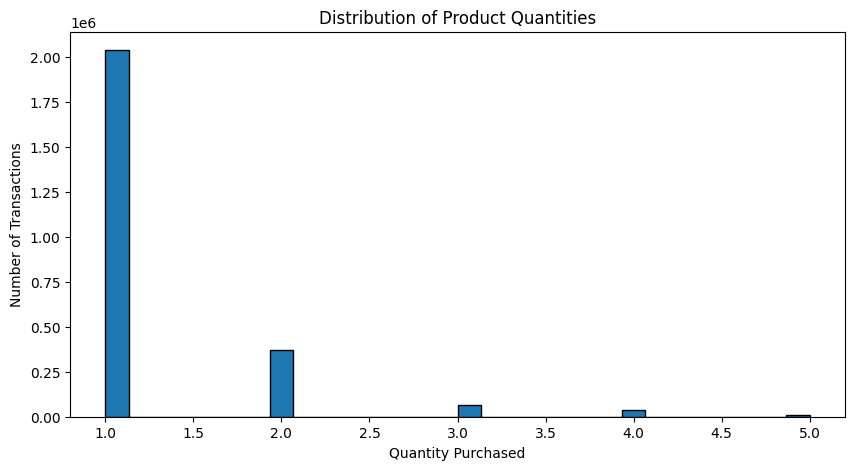

In [20]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

# Limit the graph to the 99th percentile to make the distribution readable
quantity_limit = grocery_df["QUANTITY"].quantile(0.99)

plt.hist(
    grocery_df[grocery_df["QUANTITY"] <= quantity_limit]["QUANTITY"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Product Quantities")
plt.xlabel("Quantity Purchased")
plt.ylabel("Number of Transactions")

plt.show()

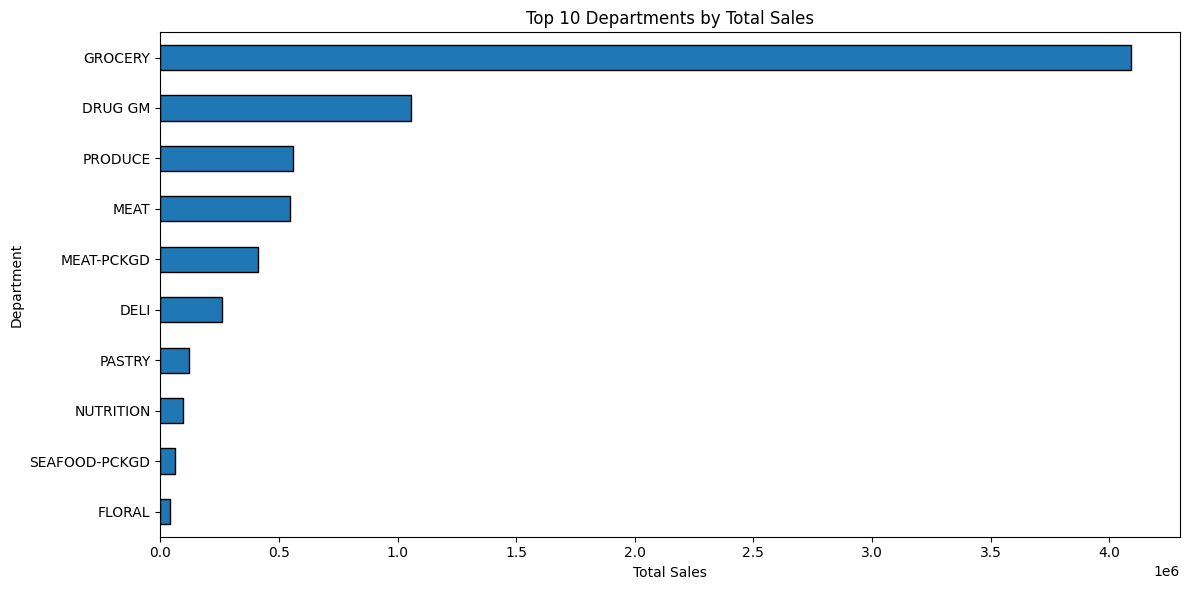

In [21]:
department_sales = (
    grocery_df.groupby("DEPARTMENT")["SALES_VALUE"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

department_sales.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Departments by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

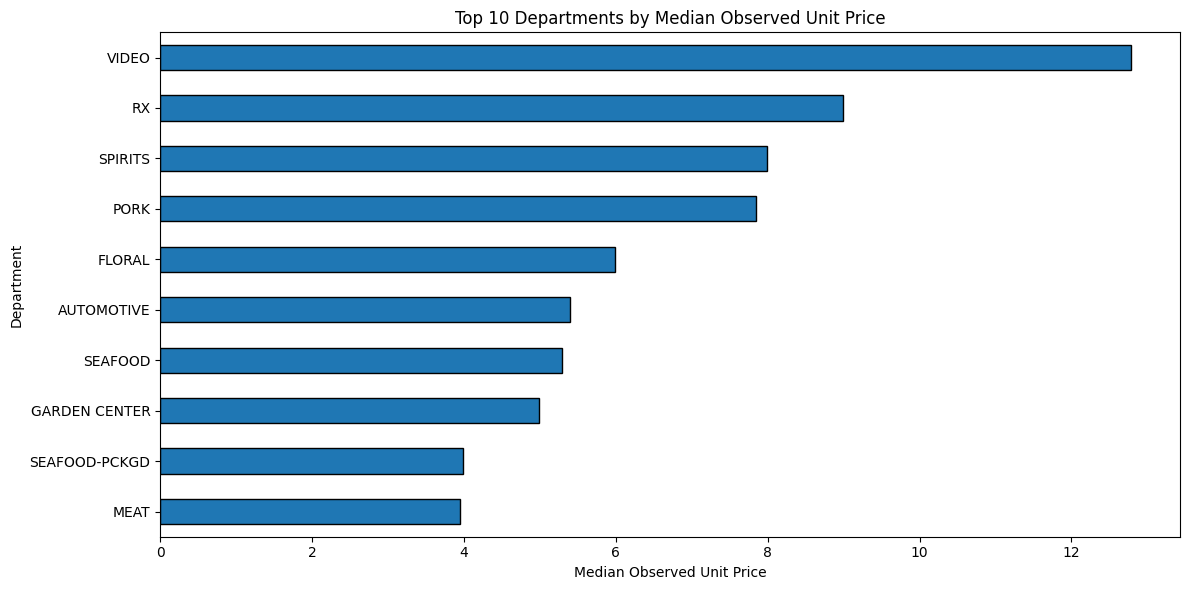

In [22]:
department_prices = (
    grocery_df.groupby("DEPARTMENT")["unit_price_raw"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

department_prices.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Departments by Median Observed Unit Price")
plt.xlabel("Median Observed Unit Price")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

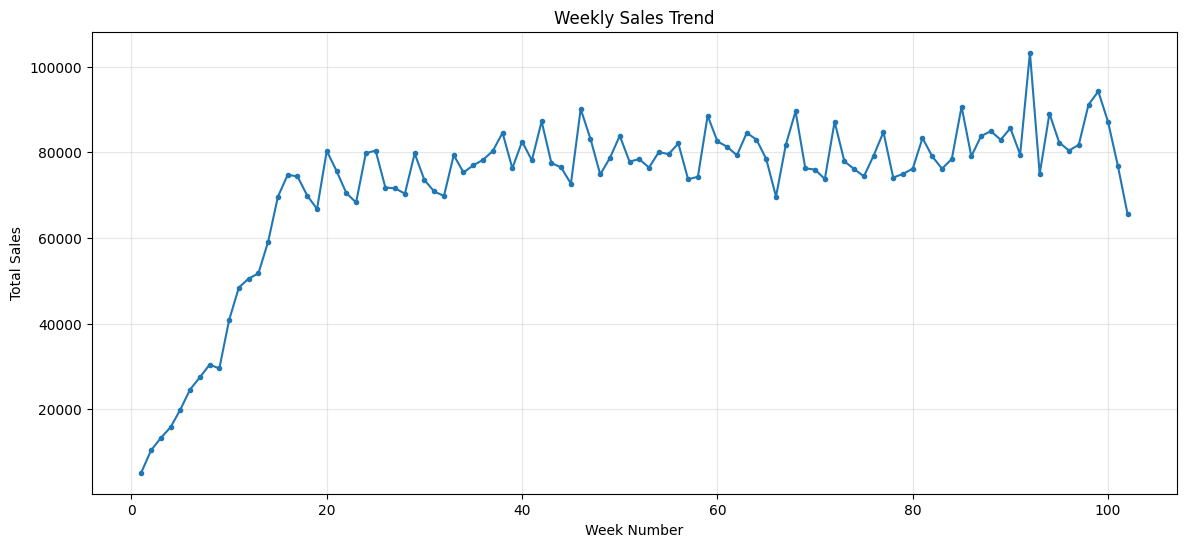

In [23]:
weekly_sales = (
    grocery_df.groupby("WEEK_NO")["SALES_VALUE"]
    .sum()
)

plt.figure(figsize=(14, 6))

plt.plot(
    weekly_sales.index,
    weekly_sales.values,
    marker="o",
    markersize=3
)

plt.title("Weekly Sales Trend")
plt.xlabel("Week Number")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)

plt.show()

In [24]:
# Group transactions by product and week
product_week = (
    grocery_df
    .groupby(["PRODUCT_ID", "WEEK_NO"])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count")
    )
    .reset_index()
)

# Calculate average observed price
product_week["average_price"] = (
    product_week["total_sales"] /
    product_week["total_quantity"]
)

# Display results
print("Dataset shape:", product_week.shape)

product_week.head()

Dataset shape: (1070099, 6)


,PRODUCT_ID,WEEK_NO,total_quantity,total_sales,transactions,average_price
0,25671,23,1,3.49,1,3.49
1,25671,36,1,3.49,1,3.49
2,25671,59,4,13.96,1,3.49
3,26093,66,1,1.59,1,1.59
4,26190,35,1,1.54,1,1.54


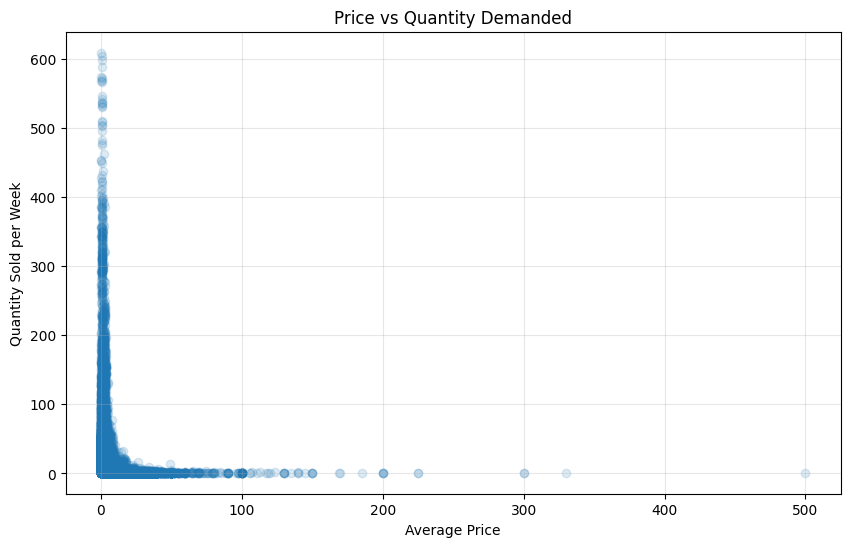

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    product_week["average_price"],
    product_week["total_quantity"],
    alpha=0.15
)

plt.title("Price vs Quantity Demanded")
plt.xlabel("Average Price")
plt.ylabel("Quantity Sold per Week")

plt.grid(alpha=0.3)
plt.show()

# calculating elasticity

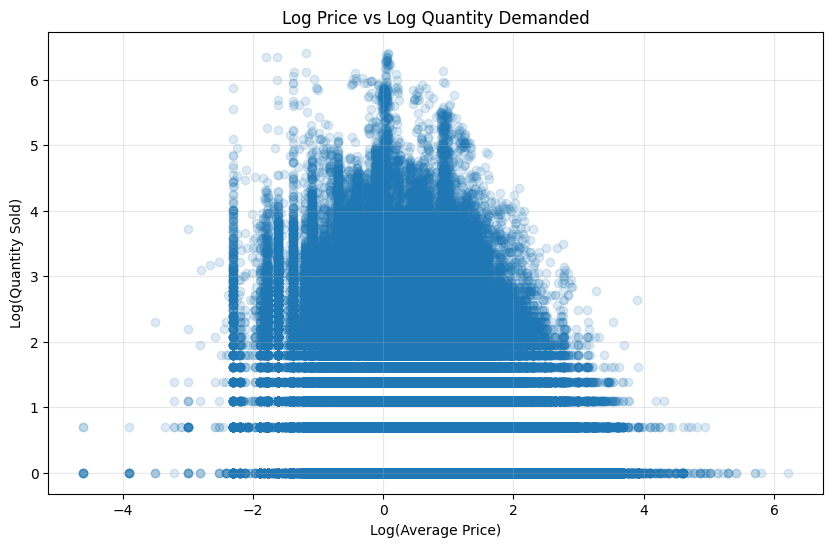

In [26]:
import numpy as np

# Keep positive observations
elasticity_data = product_week[
    (product_week["average_price"] > 0) &
    (product_week["total_quantity"] > 0)
].copy()

plt.figure(figsize=(10, 6))

plt.scatter(
    np.log(elasticity_data["average_price"]),
    np.log(elasticity_data["total_quantity"]),
    alpha=0.15
)

plt.title("Log Price vs Log Quantity Demanded")
plt.xlabel("Log(Average Price)")
plt.ylabel("Log(Quantity Sold)")

plt.grid(alpha=0.3)
plt.show()

calculating percentage changes

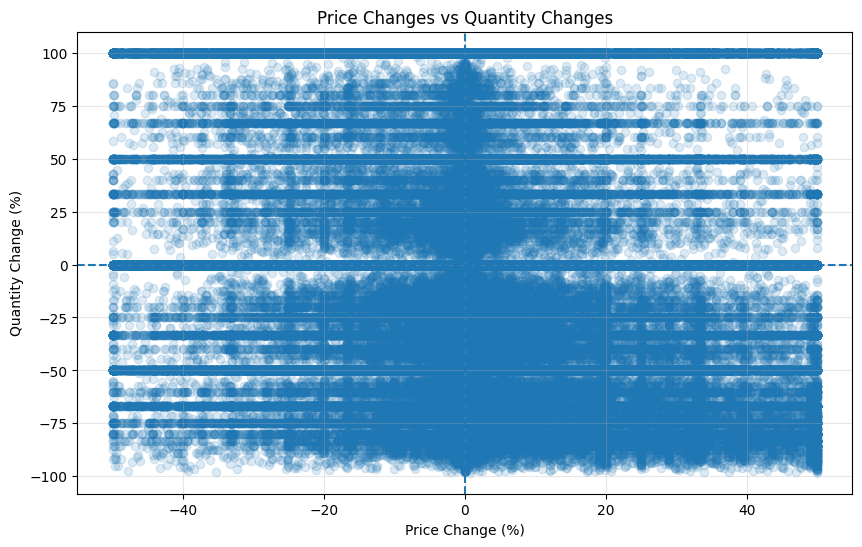

In [27]:
# Sort by product and week
elasticity_data = elasticity_data.sort_values(
    ["PRODUCT_ID", "WEEK_NO"]
).copy()

# Calculate percentage changes
elasticity_data["price_change"] = (
    elasticity_data.groupby("PRODUCT_ID")["average_price"]
    .pct_change() * 100
)

elasticity_data["quantity_change"] = (
    elasticity_data.groupby("PRODUCT_ID")["total_quantity"]
    .pct_change() * 100
)

# Remove infinite and missing values
change_data = elasticity_data.replace(
    [np.inf, -np.inf], np.nan
).dropna(
    subset=["price_change", "quantity_change"]
)

# Restrict extreme changes for readability
change_data = change_data[
    change_data["price_change"].between(-50, 50) &
    change_data["quantity_change"].between(-100, 100)
]

plt.figure(figsize=(10, 6))

plt.scatter(
    change_data["price_change"],
    change_data["quantity_change"],
    alpha=0.15
)

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.title("Price Changes vs Quantity Changes")
plt.xlabel("Price Change (%)")
plt.ylabel("Quantity Change (%)")

plt.grid(alpha=0.3)
plt.show()

## Calculating the correlation

In [28]:
# Calculate correlation between log price and log quantity

elasticity_data["log_price"] = np.log(
    elasticity_data["average_price"]
)

elasticity_data["log_quantity"] = np.log(
    elasticity_data["total_quantity"]
)

correlation = elasticity_data[
    ["log_price", "log_quantity"]
].corr()

print(correlation)

              log_price  log_quantity
log_price      1.000000     -0.302359
log_quantity  -0.302359      1.000000


In [29]:
product_correlations = (
    elasticity_data
    .groupby("PRODUCT_ID")
    .apply(
        lambda x: x["log_price"].corr(x["log_quantity"])
        if len(x) >= 10 else np.nan
    )
    .reset_index(name="correlation")
)

# Remove products without valid correlations
product_correlations = product_correlations.dropna()

print(product_correlations["correlation"].describe())

C:\Users\prosp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\prosp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


count    23425.000000
mean        -0.173561
std          0.266362
min         -1.000000
25%         -0.353567
50%         -0.169049
75%          0.002286
max          1.000000
Name: correlation, dtype: float64


C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\2273143990.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


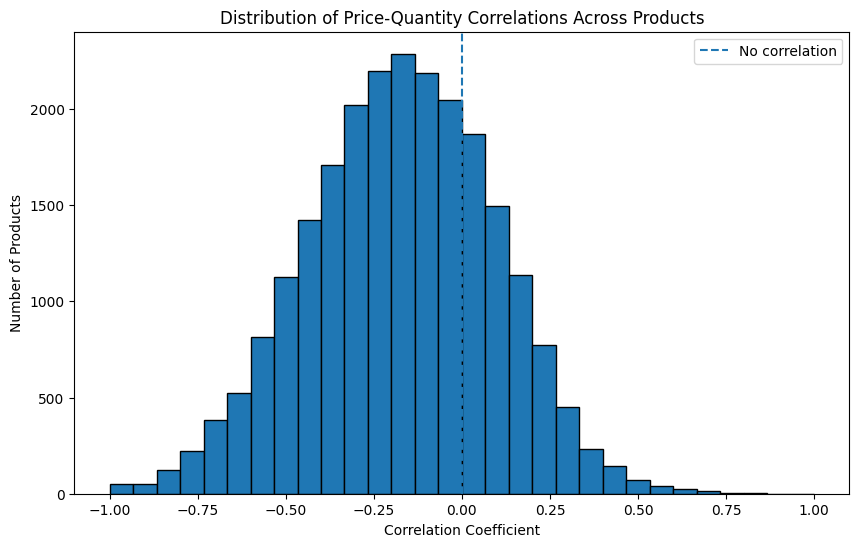

In [30]:
plt.figure(figsize=(10, 6))

plt.hist(
    product_correlations["correlation"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    label="No correlation"
)

plt.title("Distribution of Price-Quantity Correlations Across Products")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Number of Products")

plt.legend()
plt.show()

In [31]:
# Strongest negative correlations
print("Most negative correlations:")

print(
    product_correlations
    .sort_values("correlation")
    .head(10)
)

# Strongest positive correlations
print("\nMost positive correlations:")

print(
    product_correlations
    .sort_values("correlation", ascending=False)
    .head(10)
)

Most negative correlations:
       PRODUCT_ID  correlation
9491       851150         -1.0
30235     1036785         -1.0
30857     1042102         -1.0
16034      909769         -1.0
56010     6424403         -1.0
24636      986492         -1.0
82035    13416108         -1.0
14910      899931         -1.0
66545     9487921         -1.0
56092     6442602         -1.0

Most positive correlations:
       PRODUCT_ID  correlation
8545       843118     1.000000
39953     1124784     0.859185
36631     1094532     0.835689
7678       835254     0.820656
14895      899766     0.811347
38666     1112905     0.807980
33886     1069750     0.786796
34922     1078753     0.781736
67496     9553176     0.752204
12599      878934     0.750583


In [32]:
# Attach product information
product_correlations = product_correlations.merge(
    prod,
    on="PRODUCT_ID",
    how="left"
)

product_correlations[
    [
        "PRODUCT_ID",
        "DEPARTMENT",
        "BRAND",
        "COMMODITY_DESC",
        "correlation"
    ]
].head(10)

,PRODUCT_ID,DEPARTMENT,BRAND,COMMODITY_DESC,correlation
0,27658,GROCERY,Private,BAKED BREAD/BUNS/ROLLS,0.018345
1,28897,GROCERY,Private,EGGS,-0.391507
2,28966,GROCERY,Private,EGGS,-0.540018
3,29629,GROCERY,Private,BAKED BREAD/BUNS/ROLLS,-0.054615
4,32553,GROCERY,Private,FLUID MILK PRODUCTS,-0.519427
5,32916,GROCERY,Private,FLUID MILK PRODUCTS,0.299985
6,34160,GROCERY,Private,FLUID MILK PRODUCTS,-0.214213
7,34873,GROCERY,Private,FLUID MILK PRODUCTS,-0.257507
8,36406,GROCERY,National,FRZN MEAT/MEAT DINNERS,0.248651
9,40885,GROCERY,Private,FLUID MILK PRODUCTS,0.059417


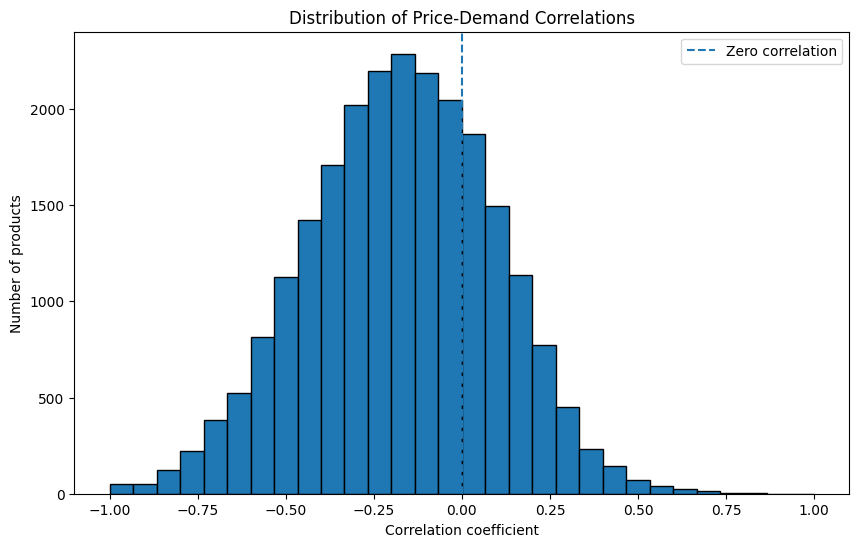

In [33]:
plt.figure(figsize=(10, 6))

plt.hist(
    product_correlations["correlation"],
    bins=30,
    edgecolor="black"
)

plt.axvline(0, linestyle="--", label="Zero correlation")

plt.title("Distribution of Price-Demand Correlations")
plt.xlabel("Correlation coefficient")
plt.ylabel("Number of products")

plt.legend()
plt.show()

In [34]:
most_sensitive = product_correlations.sort_values(
    "correlation",
    ascending=True
).head(10)

print(
    most_sensitive[
        ["PRODUCT_ID", "DEPARTMENT", "BRAND",
         "COMMODITY_DESC", "correlation"]
    ]
)

       PRODUCT_ID DEPARTMENT     BRAND             COMMODITY_DESC  correlation
1681       851150  NUTRITION  National                     FROZEN         -1.0
10842     1036785       DELI   Private                 SANDWICHES         -1.0
11119     1042102    DRUG GM  National         HAIR CARE PRODUCTS         -1.0
4593       909769    DRUG GM  National                     SEWING         -1.0
16945     6424403    DRUG GM  National  HAND/BODY/FACIAL PRODUCTS         -1.0
8344       986492    DRUG GM   Private                   ANTACIDS         -1.0
22262    13416108  NUTRITION  National                       SOUP         -1.0
4087       899931    DRUG GM  National      IRONING AND CHEMICALS         -1.0
19321     9487921    GROCERY  National          BAKED SWEET GOODS         -1.0
16963     6442602    DRUG GM  National                   BABY HBC         -1.0


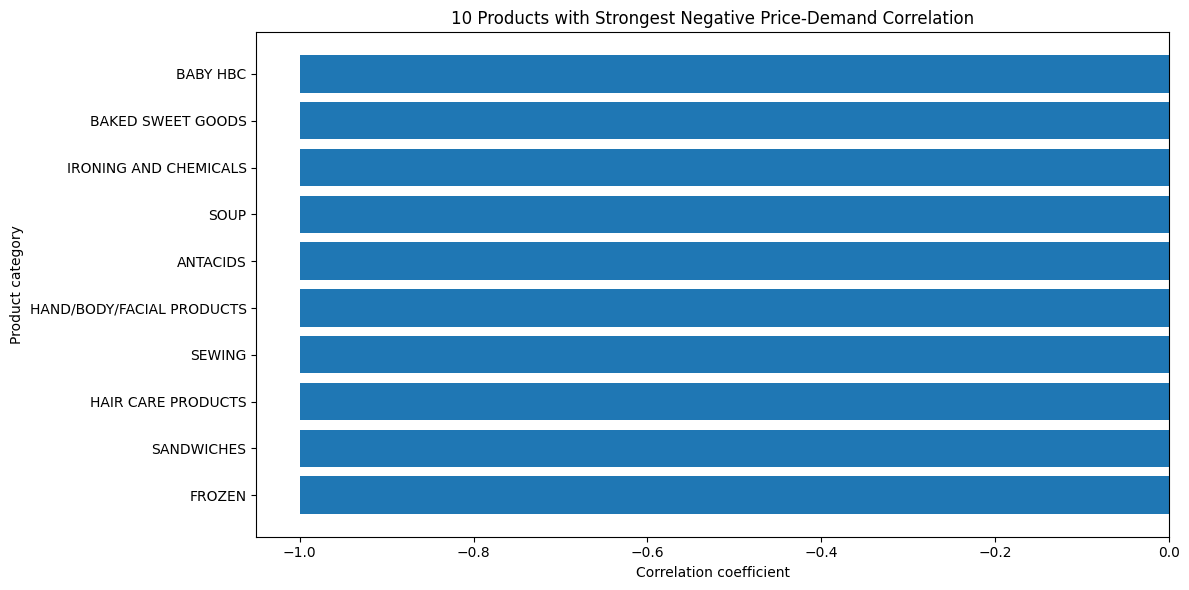

In [35]:
plt.figure(figsize=(12, 6))

plt.barh(
    most_sensitive["COMMODITY_DESC"].fillna("Unknown"),
    most_sensitive["correlation"]
)

plt.title("10 Products with Strongest Negative Price-Demand Correlation")
plt.xlabel("Correlation coefficient")
plt.ylabel("Product category")

plt.tight_layout()
plt.show()

# Elasticity Model

In [36]:
# Calculate product-level statistics

product_summary = (
    product_week
    .groupby("PRODUCT_ID")
    .agg(
        weeks_observed=("WEEK_NO", "nunique"),
        average_price=("average_price", "mean"),
        price_std=("average_price", "std"),
        total_quantity=("total_quantity", "sum")
    )
    .reset_index()
)

# Calculate price variation
product_summary["price_cv"] = (
    product_summary["price_std"] /
    product_summary["average_price"]
)

# Select products with sufficient observations and price variation
eligible = product_summary[
    (product_summary["weeks_observed"] >= 20) &
    (product_summary["price_cv"] > 0.01)
].copy()

# Display the 10 products with the most observed weeks
candidates = eligible.sort_values(
    ["weeks_observed", "price_cv"],
    ascending=False
).head(10)

print(candidates)

       PRODUCT_ID  weeks_observed  average_price  price_std  total_quantity  \
9903       854852             102       2.881367   0.899869            4095   
31873     1051516             102       1.586395   0.492497            1375   
41362     1137688             102       1.356793   0.397609            1323   
23887      979707             102       1.183658   0.338067            2758   
12603      878996             102       3.390947   0.966109            3667   
39949     1124729             102       0.462708   0.131490            2719   
29024     1026118             102       2.028517   0.559756            2047   
11186      866211             102       3.680225   0.955238            3703   
28631     1022254             102       1.879338   0.485865            1824   
16064      910032             102       2.699776   0.647210            2820   

       price_cv  
9903   0.312306  
31873  0.310451  
41362  0.293051  
23887  0.285612  
12603  0.284908  
39949  0.284176  
2902

In [37]:
# Select the first candidate
selected_product = candidates.iloc[0]["PRODUCT_ID"]

print("Selected Product ID:", selected_product)

Selected Product ID: 854852.0


In [38]:
# Extract observations for the selected product

single_product = product_week[
    product_week["PRODUCT_ID"] == selected_product
].copy()

# Sort observations by week
single_product = single_product.sort_values("WEEK_NO")

print("Number of observations:", len(single_product))

single_product.head()

Number of observations: 102


,PRODUCT_ID,WEEK_NO,total_quantity,total_sales,transactions,average_price
95753,854852,1,2,5.25,2,2.625000
95754,854852,2,5,11.30,5,2.260000
95755,854852,3,10,22.54,10,2.254000
95756,854852,4,5,17.88,5,3.576000
95757,854852,5,11,26.02,11,2.365455


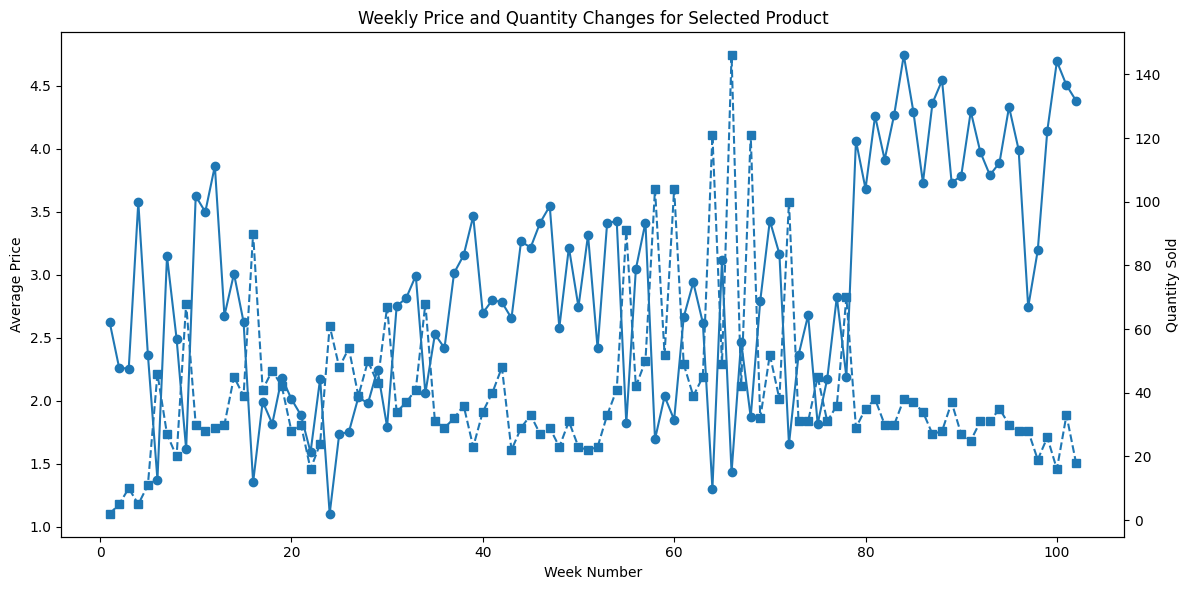

In [39]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot price
ax1.plot(
    single_product["WEEK_NO"],
    single_product["average_price"],
    marker="o",
    label="Price"
)

ax1.set_xlabel("Week Number")
ax1.set_ylabel("Average Price")

# Create a second axis for quantity
ax2 = ax1.twinx()

ax2.plot(
    single_product["WEEK_NO"],
    single_product["total_quantity"],
    marker="s",
    linestyle="--",
    label="Quantity"
)

ax2.set_ylabel("Quantity Sold")

plt.title("Weekly Price and Quantity Changes for Selected Product")

fig.tight_layout()
plt.show()

# Building regression model

In [40]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\prosp\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [41]:
import statsmodels.api as sm

In [42]:
# Calculate natural logarithms

single_product["log_price"] = np.log(
    single_product["average_price"]
)

single_product["log_quantity"] = np.log(
    single_product["total_quantity"]
)

In [43]:
# Independent variable (X)
X = single_product["log_price"]

# Dependent variable (Y)
Y = single_product["log_quantity"]

In [44]:
X = sm.add_constant(X)

In [45]:
# Create regression model
model = sm.OLS(Y, X).fit(cov_type="HC3")

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           log_quantity   R-squared:                       0.162
Model:                            OLS   Adj. R-squared:                  0.154
Method:                 Least Squares   F-statistic:                     22.97
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           5.72e-06
Time:                        05:54:25   Log-Likelihood:                -84.987
No. Observations:                 102   AIC:                             174.0
Df Residuals:                     100   BIC:                             179.2
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.2745      0.185     23.071      0.0

In [46]:
elasticity = model.params["log_price"]

print("Estimated Price Elasticity:", elasticity)

Estimated Price Elasticity: -0.7392872631637977


In [47]:
p_value = model.pvalues["log_price"]

print("P-value:", p_value)

if p_value < 0.05:
    print("The price coefficient is statistically significant.")
else:
    print("The price coefficient is not statistically significant.")

P-value: 1.641645006504155e-06
The price coefficient is statistically significant.


In [48]:
product_summary = (
    product_week
    .groupby("PRODUCT_ID")
    .agg(
        weeks_observed=("WEEK_NO", "nunique"),
        average_price=("average_price", "mean"),
        price_std=("average_price", "std"),
        total_quantity=("total_quantity", "sum")
    )
    .reset_index()
)

product_summary["price_cv"] = (
    product_summary["price_std"] /
    product_summary["average_price"]
)

eligible_products = product_summary[
    (product_summary["weeks_observed"] >= 30) &
    (product_summary["price_cv"] > 0.01)
].copy()

print("Total products:", len(product_summary))
print("Eligible products:", len(eligible_products))

Total products: 91336
Eligible products: 11484


In [49]:
results = []

for product_id in eligible_products["PRODUCT_ID"]:

    # Extract data for the current product
    product_data = product_week[
        product_week["PRODUCT_ID"] == product_id
    ].copy()

    # Sort observations by week
    product_data = product_data.sort_values("WEEK_NO")

    # Create logarithmic variables
    product_data["log_price"] = np.log(
        product_data["average_price"]
    )

    product_data["log_quantity"] = np.log(
        product_data["total_quantity"]
    )

    # Define independent and dependent variables
    X = sm.add_constant(product_data["log_price"])
    Y = product_data["log_quantity"]

    # Estimate regression
    model = sm.OLS(Y, X).fit(cov_type="HC3")

    # Save model results
    results.append({
        "PRODUCT_ID": product_id,
        "elasticity": model.params["log_price"],
        "p_value": model.pvalues["log_price"],
        "std_error": model.bse["log_price"],
        "lower_ci": model.conf_int().loc["log_price", 0],
        "upper_ci": model.conf_int().loc["log_price", 1],
        "r_squared": model.rsquared,
        "weeks_observed": len(product_data)
    })

print("Models completed:", len(results))

C:\Users\prosp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\regression\linear_model.py:2257: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h)) ** 2
C:\Users\prosp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\regression\linear_model.py:2257: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h)) ** 2
C:\Users\prosp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\regression\linear_model.py:2257: RuntimeWarning: divide by zero encountered in divide
  self.het_scale = (self.wresid / (1 - h)) ** 2
C:\Users\prosp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsm

Models completed: 11484


In [50]:
elasticity_results = pd.DataFrame(results)

print("Total results:", len(elasticity_results))

print("\nMissing elasticity values:")
print(elasticity_results["elasticity"].isna().sum())

print("\nInfinite elasticity values:")
print(np.isinf(elasticity_results["elasticity"]).sum())

print("\nMissing p-values:")
print(elasticity_results["p_value"].isna().sum())

Total results: 11484

Missing elasticity values:
0

Infinite elasticity values:
0

Missing p-values:
0


In [51]:
elasticity_results["elasticity"].describe()

count    11484.000000
mean        -0.972330
std          1.511463
min        -16.661366
25%         -1.623361
50%         -0.863980
75%         -0.228435
max         13.591437
Name: elasticity, dtype: float64

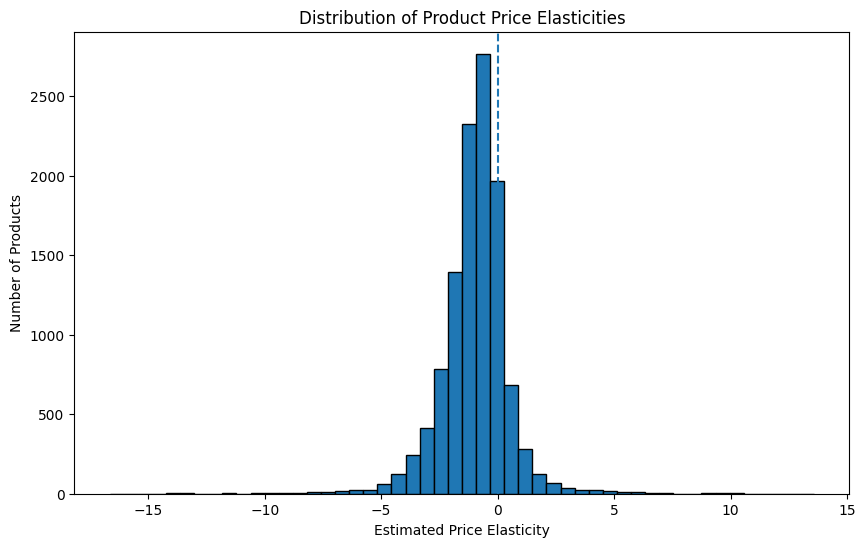

In [52]:
plt.figure(figsize=(10, 6))

plt.hist(
    elasticity_results["elasticity"].dropna(),
    bins=50,
    edgecolor="black"
)

plt.axvline(0, linestyle="--")

plt.title("Distribution of Product Price Elasticities")
plt.xlabel("Estimated Price Elasticity")
plt.ylabel("Number of Products")

plt.show()

# Elasticity Classification

In [53]:
elasticity_results = elasticity_results.merge(
    prod,
    on="PRODUCT_ID",
    how="left"
)

elasticity_results.head()

,PRODUCT_ID,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,weeks_observed,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,28897,-0.970061,0.037017,0.465129,-1.881698,-0.058425,0.153278,33,69,GROCERY,Private,EGGS,EGGS - X-LARGE,A D 1 DZ
1,29629,-0.234378,0.731312,0.682559,-1.572169,1.103413,0.002983,30,69,GROCERY,Private,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHEAT/MULTIGRAIN BR,20 OZ
2,42346,0.113377,0.931053,1.310408,-2.454976,2.681729,0.000522,32,69,GROCERY,Private,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,1 GA
3,43871,-0.302920,0.791344,1.144969,-2.547018,1.941179,0.004872,33,69,GROCERY,Private,EGGS,EGGS - LARGE,ALL 1 DZ
4,108646,-0.180439,0.594445,0.338913,-0.844697,0.483818,0.013604,30,450,NUTRITION,National,REFRIGERATED,SOY/RICE MILK,64 OZ


In [54]:
def classify_elasticity(value):

    if value < -1:
        return "Elastic"

    elif value > -1 and value < 0:
        return "Inelastic"

    elif value == 0:
        return "Perfectly Inelastic"

    else:
        return "Positive Elasticity"


elasticity_results["elasticity_category"] = (
    elasticity_results["elasticity"].apply(classify_elasticity)
)

In [55]:
category_counts = elasticity_results[
    "elasticity_category"
].value_counts()

print(category_counts)

elasticity_category
Elastic                5134
Inelastic              4276
Positive Elasticity    2074
Name: count, dtype: int64


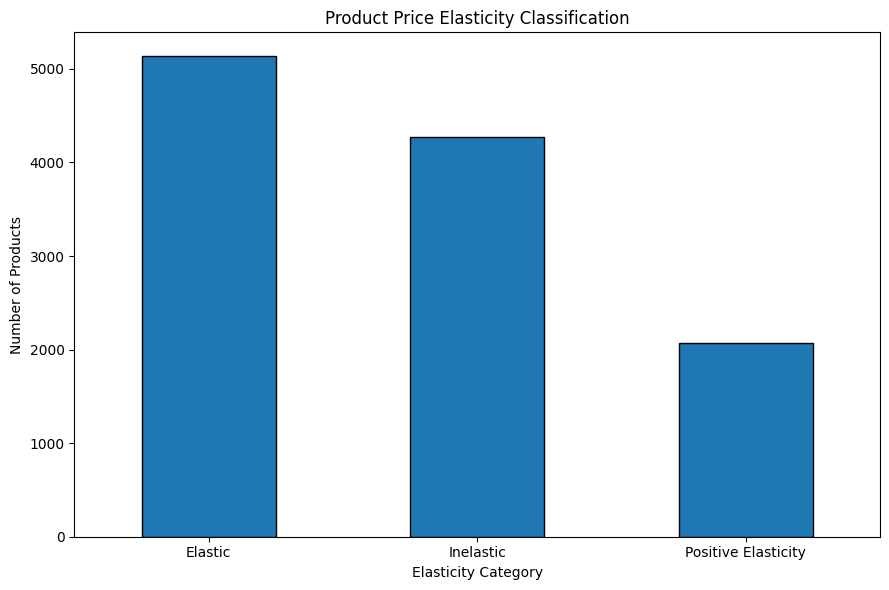

In [56]:
plt.figure(figsize=(9, 6))

category_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Product Price Elasticity Classification")
plt.xlabel("Elasticity Category")
plt.ylabel("Number of Products")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
most_sensitive = elasticity_results.sort_values(
    "elasticity",
    ascending=True
).head(10)

most_sensitive[
    [
        "PRODUCT_ID",
        "DEPARTMENT",
        "BRAND",
        "COMMODITY_DESC",
        "elasticity",
        "p_value"
    ]
]

,PRODUCT_ID,DEPARTMENT,BRAND,COMMODITY_DESC,elasticity,p_value
674,843127,GROCERY,National,BAKED SWEET GOODS,-16.661366,6.323231e-01
6843,1069268,GROCERY,National,DOG FOODS,-15.319202,8.077396e-02
147,824074,DRUG GM,National,MAGAZINE,-14.537818,3.575606e-103
8232,1119910,PRODUCE,Private,POPCORN,-14.125491,3.255544e-01
9831,7440665,GROCERY,National,BAG SNACKS,-13.844905,6.532099e-01
2547,909497,DRUG GM,National,CANDY - PACKAGED,-13.470582,2.463965e-08
3487,943233,GROCERY,National,BAKED SWEET GOODS,-13.398381,5.807193e-24
6010,1038564,GROCERY,Private,CONDIMENTS/SAUCES,-13.300265,3.152537e-05
136,823767,GROCERY,National,SALD DRSNG/SNDWCH SPRD,-13.197726,4.397067e-17
667,842817,GROCERY,National,BAG SNACKS,-11.422118,5.912633e-01


In [58]:
significant_products = elasticity_results[
    elasticity_results["p_value"] < 0.05
].copy()

print("Total products:", len(elasticity_results))
print("Statistically significant products:", len(significant_products))
print(
    "Percentage significant:",
    round(len(significant_products) / len(elasticity_results) * 100, 2),
    "%"
)

Total products: 11484
Statistically significant products: 4643
Percentage significant: 40.43 %


In [59]:
reliable_sensitive = significant_products[
    significant_products["elasticity"] < 0
].sort_values(
    "elasticity",
    ascending=True
)

reliable_sensitive[
    [
        "PRODUCT_ID",
        "DEPARTMENT",
        "COMMODITY_DESC",
        "elasticity",
        "p_value",
        "r_squared",
        "weeks_observed"
    ]
].head(15)

,PRODUCT_ID,DEPARTMENT,COMMODITY_DESC,elasticity,p_value,r_squared,weeks_observed
147,824074,DRUG GM,MAGAZINE,-14.537818,3.575606e-103,0.369876,30
2547,909497,DRUG GM,CANDY - PACKAGED,-13.470582,2.463965e-08,0.441271,40
3487,943233,GROCERY,BAKED SWEET GOODS,-13.398381,5.807193e-24,0.284297,102
6010,1038564,GROCERY,CONDIMENTS/SAUCES,-13.300265,3.152537e-05,0.355013,43
136,823767,GROCERY,SALD DRSNG/SNDWCH SPRD,-13.197726,4.397067e-17,0.539436,37
7182,1080867,GROCERY,CANNED JUICES,-11.372197,6.658939e-05,0.434145,33
533,837569,DRUG GM,CANDY - PACKAGED,-11.297757,1.251537e-03,0.285182,56
2121,894968,GROCERY,FLUID MILK PRODUCTS,-11.085242,8.378395e-07,0.114675,88
3052,927191,GROCERY,SEAFOOD - SHELF STABLE,-10.561673,4.687830e-07,0.252623,101
3192,932694,MEAT-PCKGD,LUNCHMEAT,-10.392215,4.498449e-20,0.121096,37


In [60]:
top_products = reliable_sensitive.head(5)["PRODUCT_ID"].tolist()

diagnostics = []

for product_id in top_products:

    data = product_week[
        product_week["PRODUCT_ID"] == product_id
    ].copy()

    diagnostics.append({
        "PRODUCT_ID": product_id,
        "weeks": len(data),
        "average_price": data["average_price"].mean(),
        "minimum_price": data["average_price"].min(),
        "maximum_price": data["average_price"].max(),
        "price_std": data["average_price"].std(),
        "price_cv": (
            data["average_price"].std() /
            data["average_price"].mean()
        ),
        "average_quantity": data["total_quantity"].mean(),
        "minimum_quantity": data["total_quantity"].min(),
        "maximum_quantity": data["total_quantity"].max()
    })

diagnostics_df = pd.DataFrame(diagnostics)

diagnostics_df

,PRODUCT_ID,weeks,average_price,minimum_price,maximum_price,price_std,price_cv,average_quantity,minimum_quantity,maximum_quantity
0,824074,30,4.739444,4.433333,4.75,0.057815,0.012199,1.200000,1,3
1,909497,40,10.473750,9.840000,10.99,0.359912,0.034363,2.375000,1,11
2,943233,102,1.080432,1.000000,1.19,0.031013,0.028704,7.107843,1,23
3,1038564,43,2.380233,2.210000,2.39,0.036871,0.015490,1.325581,1,4
4,823767,37,1.276486,1.190000,1.29,0.034658,0.027151,1.702703,1,5


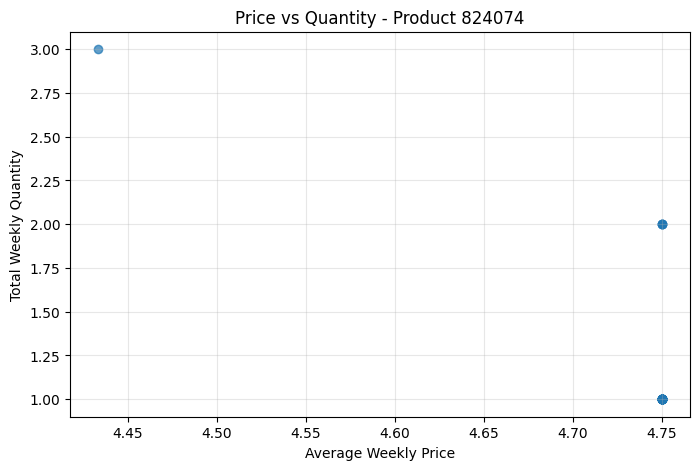

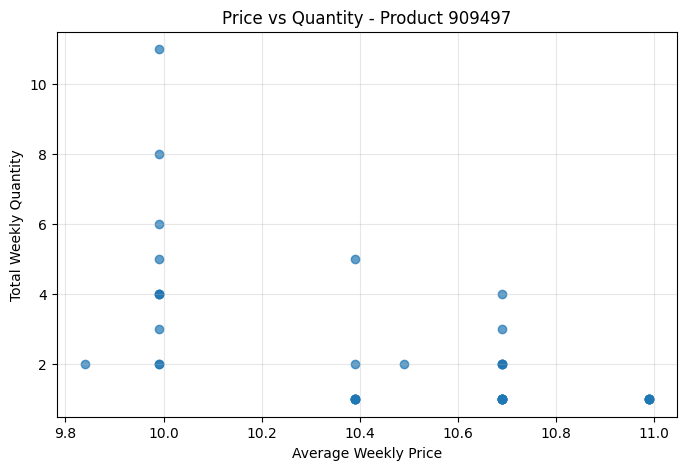

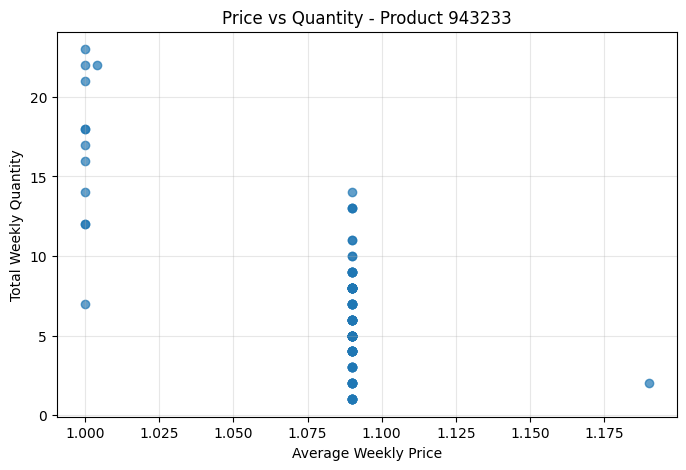

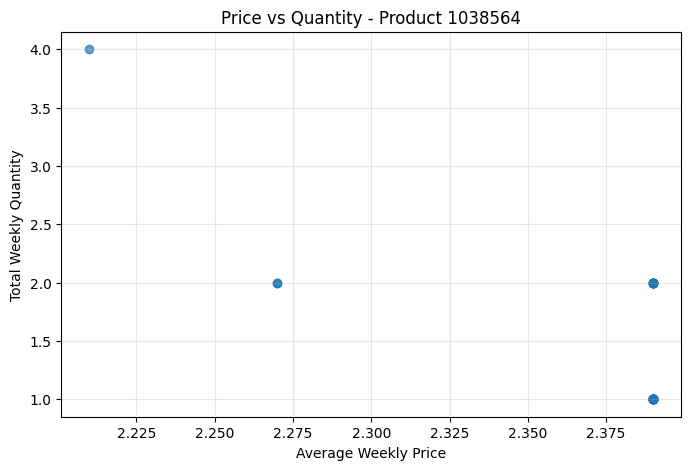

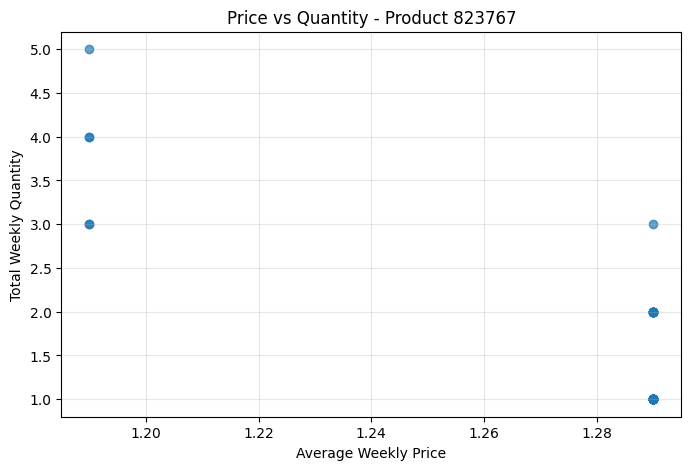

In [61]:
for product_id in top_products:

    data = product_week[
        product_week["PRODUCT_ID"] == product_id
    ].copy()

    plt.figure(figsize=(8, 5))

    plt.scatter(
        data["average_price"],
        data["total_quantity"],
        alpha=0.7
    )

    plt.title(f"Price vs Quantity - Product {product_id}")
    plt.xlabel("Average Weekly Price")
    plt.ylabel("Total Weekly Quantity")
    plt.grid(alpha=0.3)

    plt.show()

In [62]:
least_sensitive = significant_products[
    (significant_products["elasticity"] < 0) &
    (significant_products["elasticity"] > -1)
].sort_values(
    "elasticity",
    ascending=False
)

least_sensitive[
    [
        "PRODUCT_ID",
        "DEPARTMENT",
        "COMMODITY_DESC",
        "elasticity",
        "p_value",
        "r_squared",
        "weeks_observed"
    ]
].head(15)

,PRODUCT_ID,DEPARTMENT,COMMODITY_DESC,elasticity,p_value,r_squared,weeks_observed
11190,12810369,MEAT,PORK,-0.256209,0.010218,0.074547,37
547,837969,DELI,DELI MEATS,-0.308465,0.015754,0.058847,73
9367,6533182,GROCERY,ICE CREAM/MILK/SHERBTS,-0.402658,0.013837,0.049690,31
6106,1041766,GROCERY,MILK BY-PRODUCTS,-0.407476,0.043004,0.072330,55
1072,856524,GROCERY,CONDIMENTS/SAUCES,-0.414372,0.023656,0.081881,49
10471,9655175,GROCERY,ICE CREAM/MILK/SHERBTS,-0.446084,0.010305,0.075513,32
7725,1100617,GROCERY,CRACKERS/MISC BKD FD,-0.446591,0.043681,0.092167,31
1181,860776,PRODUCE,VEGETABLES - ALL OTHERS,-0.471489,0.031658,0.042100,102
9928,8064946,DELI,CHEESES,-0.471565,0.012229,0.134753,33
2631,912503,PRODUCE,SQUASH,-0.484911,0.000258,0.150743,57


In [63]:
most_elastic = significant_products[
    significant_products["elasticity"] < -1
].sort_values(
    "elasticity",
    ascending=True
)

most_elastic[
    [
        "PRODUCT_ID",
        "DEPARTMENT",
        "COMMODITY_DESC",
        "elasticity",
        "p_value",
        "r_squared",
        "weeks_observed"
    ]
].head(15)

,PRODUCT_ID,DEPARTMENT,COMMODITY_DESC,elasticity,p_value,r_squared,weeks_observed
147,824074,DRUG GM,MAGAZINE,-14.537818,3.575606e-103,0.369876,30
2547,909497,DRUG GM,CANDY - PACKAGED,-13.470582,2.463965e-08,0.441271,40
3487,943233,GROCERY,BAKED SWEET GOODS,-13.398381,5.807193e-24,0.284297,102
6010,1038564,GROCERY,CONDIMENTS/SAUCES,-13.300265,3.152537e-05,0.355013,43
136,823767,GROCERY,SALD DRSNG/SNDWCH SPRD,-13.197726,4.397067e-17,0.539436,37
7182,1080867,GROCERY,CANNED JUICES,-11.372197,6.658939e-05,0.434145,33
533,837569,DRUG GM,CANDY - PACKAGED,-11.297757,1.251537e-03,0.285182,56
2121,894968,GROCERY,FLUID MILK PRODUCTS,-11.085242,8.378395e-07,0.114675,88
3052,927191,GROCERY,SEAFOOD - SHELF STABLE,-10.561673,4.687830e-07,0.252623,101
3192,932694,MEAT-PCKGD,LUNCHMEAT,-10.392215,4.498449e-20,0.121096,37


In [64]:
print("Inelastic products:", len(least_sensitive))

print("Elastic products:", len(most_elastic))

print(
    "Total significant negative products:",
    len(least_sensitive) + len(most_elastic)
)

Inelastic products: 594
Elastic products: 3808
Total significant negative products: 4402


In [65]:
from statsmodels.stats.multitest import multipletests

In [66]:
elasticity_results["adjusted_p_value"] = multipletests(
    elasticity_results["p_value"],
    method="fdr_bh"
)[1]

In [67]:
validated_products = elasticity_results[
    (elasticity_results["adjusted_p_value"] < 0.05) &
    (elasticity_results["elasticity"] < 0)
].copy()

print("Total products modelled:", len(elasticity_results))

print(
    "Significant products after FDR correction:",
    len(validated_products)
)

Total products modelled: 11484
Significant products after FDR correction: 3522


In [68]:
validated_products["demand_category"] = np.where(
    validated_products["elasticity"] < -1,
    "Elastic",
    "Inelastic"
)

print(
    validated_products["demand_category"].value_counts()
)

demand_category
Elastic      3221
Inelastic     301
Name: count, dtype: int64


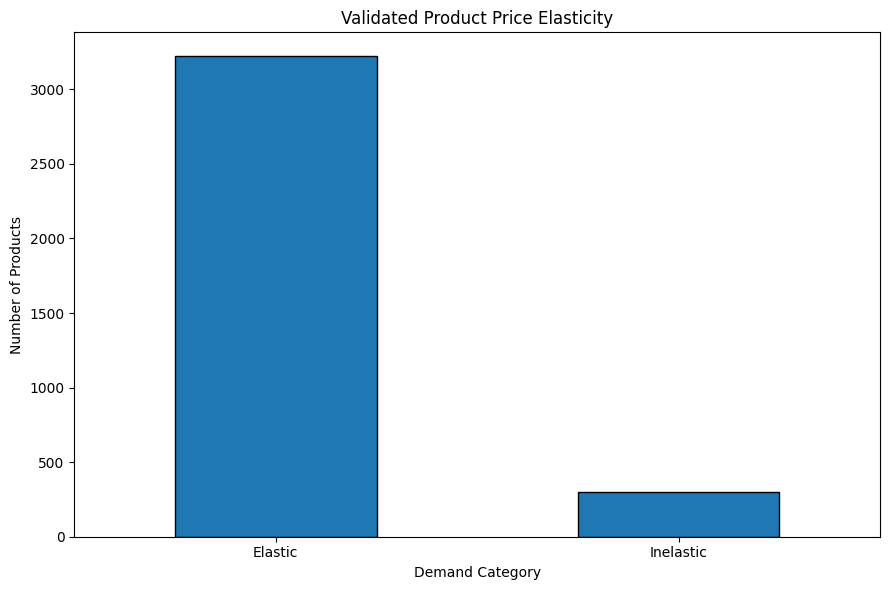

In [69]:
plt.figure(figsize=(9, 6))

validated_products["demand_category"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Validated Product Price Elasticity")
plt.xlabel("Demand Category")
plt.ylabel("Number of Products")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [70]:
grocery_df["discount_amount"] = (
    grocery_df["RETAIL_DISC"].abs() +
    grocery_df["COUPON_DISC"].abs() +
    grocery_df["COUPON_MATCH_DISC"].abs()
)

grocery_df["is_promotion"] = (
    grocery_df["discount_amount"] > 0
).astype(int)

In [71]:
product_week_extended = (
    grocery_df
    .groupby(["PRODUCT_ID", "WEEK_NO"])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

product_week_extended["average_price"] = (
    product_week_extended["total_sales"] /
    product_week_extended["total_quantity"]
)

product_week_extended["promotion_share"] = (
    product_week_extended["promotional_transactions"] /
    product_week_extended["transactions"]
)

In [72]:
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

improved_results = []

for product_id in eligible_products["PRODUCT_ID"]:

    # Get data for this product
    product_data = product_week_extended[
        product_week_extended["PRODUCT_ID"] == product_id
    ].copy()

    product_data = product_data.sort_values("WEEK_NO")

    # Remove invalid observations
    product_data = product_data[
        (product_data["average_price"] > 0) &
        (product_data["total_quantity"] > 0)
    ].copy()

    # Check that enough observations are available
    if len(product_data) < 30:
        continue

    # Create logarithmic variables
    product_data["log_price"] = np.log(
        product_data["average_price"]
    )

    product_data["log_quantity"] = np.log(
        product_data["total_quantity"]
    )

    # Create a time trend
    product_data["time_trend"] = (
        product_data["WEEK_NO"] - product_data["WEEK_NO"].min()
    )

    # Skip products with almost no price variation
    if product_data["log_price"].std() < 0.001:
        continue

    # Define independent variables
    X = product_data[
        ["log_price", "promotion_share", "time_trend"]
    ]

    X = sm.add_constant(X)

    # Define dependent variable
    Y = product_data["log_quantity"]

    # Fit regression with HAC standard errors
    model = sm.OLS(Y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 4}
    )

    improved_results.append({
        "PRODUCT_ID": product_id,
        "elasticity": model.params["log_price"],
        "p_value": model.pvalues["log_price"],
        "std_error": model.bse["log_price"],
        "lower_ci": model.conf_int().loc["log_price", 0],
        "upper_ci": model.conf_int().loc["log_price", 1],
        "r_squared": model.rsquared,
        "weeks_observed": len(product_data)
    })

print("Improved models completed:", len(improved_results))

C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3458551444.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3458551444.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3458551444.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3458551444.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3458551444.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined

Improved models completed: 11484


C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3458551444.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(


In [73]:
improved_elasticity_results = pd.DataFrame(improved_results)

improved_elasticity_results = improved_elasticity_results.merge(
    prod,
    on="PRODUCT_ID",
    how="left"
)

print(improved_elasticity_results.shape)

improved_elasticity_results.head()

(11484, 14)


,PRODUCT_ID,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,weeks_observed,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,28897,-0.120250,0.816606,0.518517,-1.136525,0.896024,0.196144,33,69,GROCERY,Private,EGGS,EGGS - X-LARGE,A D 1 DZ
1,29629,2.407058,0.156041,1.696886,-0.918778,5.732895,0.097321,30,69,GROCERY,Private,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHEAT/MULTIGRAIN BR,20 OZ
2,42346,0.366651,0.755621,1.178047,-1.942278,2.675580,0.013016,32,69,GROCERY,Private,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,1 GA
3,43871,-0.511656,0.789544,1.917007,-4.268920,3.245609,0.017070,33,69,GROCERY,Private,EGGS,EGGS - LARGE,ALL 1 DZ
4,108646,0.036193,0.872110,0.224833,-0.404471,0.476858,0.113137,30,450,NUTRITION,National,REFRIGERATED,SOY/RICE MILK,64 OZ


In [74]:
improved_elasticity_results["adjusted_p_value"] = multipletests(
    improved_elasticity_results["p_value"],
    method="fdr_bh"
)[1]

In [75]:
improved_validated_products = improved_elasticity_results[
    (improved_elasticity_results["adjusted_p_value"] < 0.05) &
    (improved_elasticity_results["elasticity"] < 0)
].copy()


In [76]:
improved_validated_products["demand_category"] = np.where(
    improved_validated_products["elasticity"] < -1,
    "Elastic",
    "Inelastic"
)

In [77]:
improved_validated_products["demand_category"].value_counts()

demand_category
Elastic      2864
Inelastic     208
Name: count, dtype: int64

In [78]:
comparison = elasticity_results[
    ["PRODUCT_ID", "elasticity"]
].merge(
    improved_elasticity_results[
        ["PRODUCT_ID", "elasticity"]
    ],
    on="PRODUCT_ID",
    suffixes=("_original", "_improved")
)

comparison["elasticity_change"] = (
    comparison["elasticity_improved"] -
    comparison["elasticity_original"]
)

comparison.head()

,PRODUCT_ID,elasticity_original,elasticity_improved,elasticity_change
0,28897,-0.970061,-0.120250,0.849811
1,29629,-0.234378,2.407058,2.641436
2,42346,0.113377,0.366651,0.253275
3,43871,-0.302920,-0.511656,-0.208736
4,108646,-0.180439,0.036193,0.216632


In [79]:
comparison["elasticity_change"].describe()

count    11484.000000
mean         1.148001
std         27.762213
min       -999.425836
25%         -0.456938
50%          0.028323
75%          0.595281
max        821.839783
Name: elasticity_change, dtype: float64

In [80]:
largest_changes = comparison.copy()

largest_changes["absolute_change"] = (
    largest_changes["elasticity_change"].abs()
)

largest_changes = largest_changes.sort_values(
    "absolute_change",
    ascending=False
)

largest_changes = largest_changes.merge(
    prod[["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC"]],
    on="PRODUCT_ID",
    how="left"
)

largest_changes.head(15)

,PRODUCT_ID,elasticity_original,elasticity_improved,elasticity_change,absolute_change,DEPARTMENT,COMMODITY_DESC
0,935570,1.802494,-997.623342,-999.425836,999.425836,GROCERY,MEAT - SHELF STABLE
1,1026482,-0.113817,821.725966,821.839783,821.839783,DRUG GM,FIRST AID PRODUCTS
2,976787,1.081576,811.627521,810.545945,810.545945,DRUG GM,FIRST AID PRODUCTS
3,993339,-2.524204,747.967957,750.492161,750.492161,GROCERY,YOGURT
4,12782180,0.988104,741.869829,740.881726,740.881726,GROCERY,BAG SNACKS
5,1116549,-0.242367,721.760215,722.002581,722.002581,COSMETICS,MAKEUP AND TREATMENT
6,984380,0.941432,704.444930,703.503498,703.503498,DRUG GM,FIRST AID PRODUCTS
7,1096810,2.447441,679.563567,677.116126,677.116126,GROCERY,FLOUR & MEALS
8,12330860,3.411688,582.716577,579.304889,579.304889,GROCERY,BAG SNACKS
9,6034281,-2.291551,566.898005,569.189556,569.189556,GROCERY,COFFEE


In [81]:
problem_product = product_week_extended[
    product_week_extended["PRODUCT_ID"] == 935570
].copy()

problem_product = problem_product.sort_values("WEEK_NO")

problem_product[
    [
        "WEEK_NO",
        "average_price",
        "total_quantity",
        "promotion_share"
    ]
].describe()

,WEEK_NO,average_price,total_quantity,promotion_share
count,82.000000,82.000000,82.000000,82.000000
mean,55.402439,1.982165,3.634146,0.024390
std,27.397332,0.049861,2.733027,0.155207
min,7.000000,1.667500,1.000000,0.000000
25%,33.250000,1.990000,1.000000,0.000000
50%,54.500000,1.990000,3.000000,0.000000
75%,78.750000,1.990000,5.000000,0.000000
max,102.000000,1.990000,11.000000,1.000000


In [82]:
problem_product[
    [
        "WEEK_NO",
        "average_price",
        "total_quantity",
        "promotion_share"
    ]
].head(15)

,WEEK_NO,average_price,total_quantity,promotion_share
286010,7,1.9900,2,0.0
286011,8,1.6675,4,1.0
286012,11,1.9900,1,0.0
286013,12,1.9900,1,0.0
286014,13,1.9900,2,0.0
286015,14,1.9900,1,0.0
286016,16,1.9900,3,0.0
286017,18,1.9900,3,0.0
286018,19,1.9900,7,0.0
286019,20,1.9900,5,0.0


In [83]:
price_diagnostics = product_week_extended.groupby(
    "PRODUCT_ID"
).agg(
    weeks_observed=("WEEK_NO", "nunique"),
    distinct_prices=("average_price", "nunique"),
    average_price=("average_price", "mean"),
    price_std=("average_price", "std"),
    average_quantity=("total_quantity", "mean"),
    promotion_weeks=("promotion_share", lambda x: (x > 0).sum())
).reset_index()

price_diagnostics["price_cv"] = (
    price_diagnostics["price_std"] /
    price_diagnostics["average_price"]
)

price_diagnostics.describe()

,PRODUCT_ID,weeks_observed,distinct_prices,average_price,price_std,average_quantity,promotion_weeks,price_cv
count,9.133600e+04,91336.000000,91336.000000,91336.000000,57454.000000,91336.000000,91336.000000,57454.000000
mean,5.299562e+06,11.716070,3.476428,3.971862,0.447819,1.573047,5.395507,0.128728
std,5.345443e+06,20.052137,6.815612,5.520689,0.947779,2.474081,12.864757,0.143069
min,2.567100e+04,1.000000,1.000000,0.010000,0.000000,1.000000,0.000000,0.000000
25%,9.697842e+05,1.000000,1.000000,1.665456,0.020507,1.000000,0.000000,0.012462
50%,1.596006e+06,3.000000,1.000000,2.740000,0.233854,1.000000,1.000000,0.099028
75%,9.677534e+06,11.000000,3.000000,4.523333,0.514805,1.545455,3.000000,0.182070
max,1.831630e+07,102.000000,102.000000,499.990000,38.176695,302.882353,102.000000,2.401145


In [84]:
reliable_products = price_diagnostics[
    (price_diagnostics["weeks_observed"] >= 30) &
    (price_diagnostics["distinct_prices"] >= 5) &
    (price_diagnostics["price_cv"] > 0.02) &
    (price_diagnostics["average_quantity"] >= 3)
].copy()

print("Reliable products:", len(reliable_products))

Reliable products: 2831


In [85]:
final_results = []

for product_id in reliable_products["PRODUCT_ID"]:

    product_data = product_week_extended[
        product_week_extended["PRODUCT_ID"] == product_id
    ].copy()

    product_data = product_data.sort_values("WEEK_NO")

    product_data["log_price"] = np.log(
        product_data["average_price"]
    )

    product_data["log_quantity"] = np.log(
        product_data["total_quantity"]
    )

    product_data["time_trend"] = (
        product_data["WEEK_NO"] - product_data["WEEK_NO"].min()
    )

    X = product_data[
        ["log_price", "promotion_share", "time_trend"]
    ]

    X = sm.add_constant(X)

    Y = product_data["log_quantity"]

    model = sm.OLS(Y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 4}
    )

    final_results.append({
        "PRODUCT_ID": product_id,
        "elasticity": model.params["log_price"],
        "p_value": model.pvalues["log_price"],
        "std_error": model.bse["log_price"],
        "lower_ci": model.conf_int().loc["log_price", 0],
        "upper_ci": model.conf_int().loc["log_price", 1],
        "r_squared": model.rsquared,
        "weeks_observed": len(product_data)
    })

print("Final models completed:", len(final_results))

C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\1234389018.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\1234389018.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\1234389018.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\1234389018.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(Y, X).fit(
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\1234389018.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined

Final models completed: 2831


In [86]:
final_elasticity = pd.DataFrame(final_results)

final_elasticity = final_elasticity.merge(
    prod,
    on="PRODUCT_ID",
    how="left"
)

final_elasticity.head()

,PRODUCT_ID,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,weeks_observed,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,818980,-5.983733,9.341107e-03,2.302046,-10.495660,-1.471806,0.123614,65,1251,GROCERY,National,BEANS - CANNED GLASS & MW,PREPARED BEANS - BAKED W/PORK,15.75 OZ
1,819063,-1.048180,5.642208e-01,1.817914,-4.611226,2.514867,0.020880,95,754,GROCERY,National,PASTA SAUCE,MAINSTREAM,26 OZ
2,819227,-2.348593,5.109399e-02,1.203981,-4.708352,0.011166,0.043896,40,1225,GROCERY,National,CAT FOOD,CAN CATFD GOURMET/SUP PREM (GR,3 OZ
3,819255,-4.454090,1.810763e-24,0.436299,-5.309220,-3.598960,0.600742,73,1007,MEAT-PCKGD,National,BREAKFAST SAUSAGE/SANDWICHES,ROLLS - PORK,1 LB
4,819304,-1.369963,1.495741e-01,0.950678,-3.233258,0.493332,0.235643,95,754,GROCERY,National,PASTA SAUCE,MAINSTREAM,26 OZ


In [87]:
final_elasticity["adjusted_p_value"] = multipletests(
    final_elasticity["p_value"],
    method="fdr_bh"
)[1]

In [88]:
final_validated = final_elasticity[
    (final_elasticity["adjusted_p_value"] < 0.05) &
    (final_elasticity["elasticity"] < 0)
].copy()

final_validated["demand_category"] = np.where(
    final_validated["elasticity"] < -1,
    "Elastic",
    "Inelastic"
)

final_validated["demand_category"].value_counts()

demand_category
Elastic      1203
Inelastic      20
Name: count, dtype: int64

In [89]:
final_validated["elasticity"].describe()

count    1223.000000
mean       -3.148308
std         2.836408
min       -76.873419
25%        -3.640205
50%        -2.668626
75%        -1.982634
max        -0.199592
Name: elasticity, dtype: float64

In [90]:
final_validated[
    ["PRODUCT_ID", "COMMODITY_DESC", "elasticity",
     "lower_ci", "upper_ci", "r_squared"]
].sort_values(
    "elasticity"
).head(10)

,PRODUCT_ID,COMMODITY_DESC,elasticity,lower_ci,upper_ci,r_squared
809,919644,FROZEN PIZZA,-76.873419,-126.881823,-26.865015,0.222860
2509,7409957,FRZN POTATOES,-29.730893,-37.589975,-21.871812,0.088788
2770,12987975,BAG SNACKS,-17.301104,-23.039976,-11.562231,0.192724
1916,1080867,CANNED JUICES,-16.490818,-21.089035,-11.892601,0.479443
80,828278,VEGETABLES - SHELF STABLE,-15.075261,-23.871285,-6.279237,0.104947
2123,1113588,FRZN MEAT/MEAT DINNERS,-12.427701,-17.025466,-7.829935,0.252927
1243,982493,BAKED SWEET GOODS,-12.358878,-17.183659,-7.534096,0.321647
1670,1044188,CHEESE,-12.082147,-21.561285,-2.603008,0.069710
1439,1009200,FRZN MEAT/MEAT DINNERS,-10.504463,-14.570194,-6.438732,0.087439
1808,1065593,BATH TISSUES,-10.500340,-15.547934,-5.452747,0.408684


In [91]:
# Count elastic and inelastic products
final_validated["demand_category"].value_counts()

demand_category
Elastic      1203
Inelastic      20
Name: count, dtype: int64

In [92]:
category_percentages = (
    final_validated["demand_category"]
    .value_counts(normalize=True) * 100
)

print(category_percentages.round(2))

demand_category
Elastic      98.36
Inelastic     1.64
Name: proportion, dtype: float64


In [93]:
commodity_analysis = (
    final_validated
    .groupby("COMMODITY_DESC")
    .agg(
        number_of_products=("PRODUCT_ID", "count"),
        average_elasticity=("elasticity", "mean"),
        median_elasticity=("elasticity", "median"),
        elastic_products=(
            "demand_category",
            lambda x: (x == "Elastic").sum()
        ),
        inelastic_products=(
            "demand_category",
            lambda x: (x == "Inelastic").sum()
        )
    )
    .reset_index()
)

commodity_analysis["elastic_percentage"] = (
    commodity_analysis["elastic_products"] /
    commodity_analysis["number_of_products"] * 100
)

commodity_analysis = commodity_analysis.sort_values(
    "average_elasticity"
)

commodity_analysis.head(15)

,COMMODITY_DESC,number_of_products,average_elasticity,median_elasticity,elastic_products,inelastic_products,elastic_percentage
79,MISC. DAIRY,4,-6.390039,-7.220425,4,0,100.0
64,FRZN POTATOES,7,-5.941080,-1.986761,7,0,100.0
97,REFRIGERATED,1,-5.504158,-5.504158,1,0,100.0
22,CANNED MILK,3,-5.260293,-4.749740,3,0,100.0
7,BATH TISSUES,12,-5.133657,-4.807056,12,0,100.0
11,BEERS/ALES,6,-5.072970,-4.700204,6,0,100.0
48,EXOTIC GAME/FOWL,1,-4.998642,-4.998642,1,0,100.0
58,FROZEN PIZZA,38,-4.965164,-2.683790,38,0,100.0
103,SEAFOOD - SHELF STABLE,10,-4.798829,-3.803925,10,0,100.0
77,MELONS,2,-4.786049,-4.786049,2,0,100.0


In [94]:
commodity_analysis.sort_values(
    "average_elasticity",
    ascending=False
).head(15)

,COMMODITY_DESC,number_of_products,average_elasticity,median_elasticity,elastic_products,inelastic_products,elastic_percentage
110,SQUASH,1,-0.588730,-0.588730,0,1,0.000000
82,NEWSPAPER,1,-0.908604,-0.908604,0,1,0.000000
120,VEGETABLES SALAD,3,-0.930115,-1.078806,2,1,66.666667
116,VALUE ADDED FRUIT,1,-0.949975,-0.949975,0,1,0.000000
111,STATIONERY & SCHOOL SUPPLIES,3,-0.984375,-0.978584,1,2,33.333333
52,FLORAL-FRESH CUT,1,-1.158528,-1.158528,1,0,100.000000
38,DELI MEATS,1,-1.435992,-1.435992,1,0,100.000000
106,SNACK NUTS,1,-1.440386,-1.440386,1,0,100.000000
113,TROPICAL FRUIT,3,-1.547027,-0.952639,1,2,33.333333
93,PORK,10,-1.576832,-1.568422,8,2,80.000000


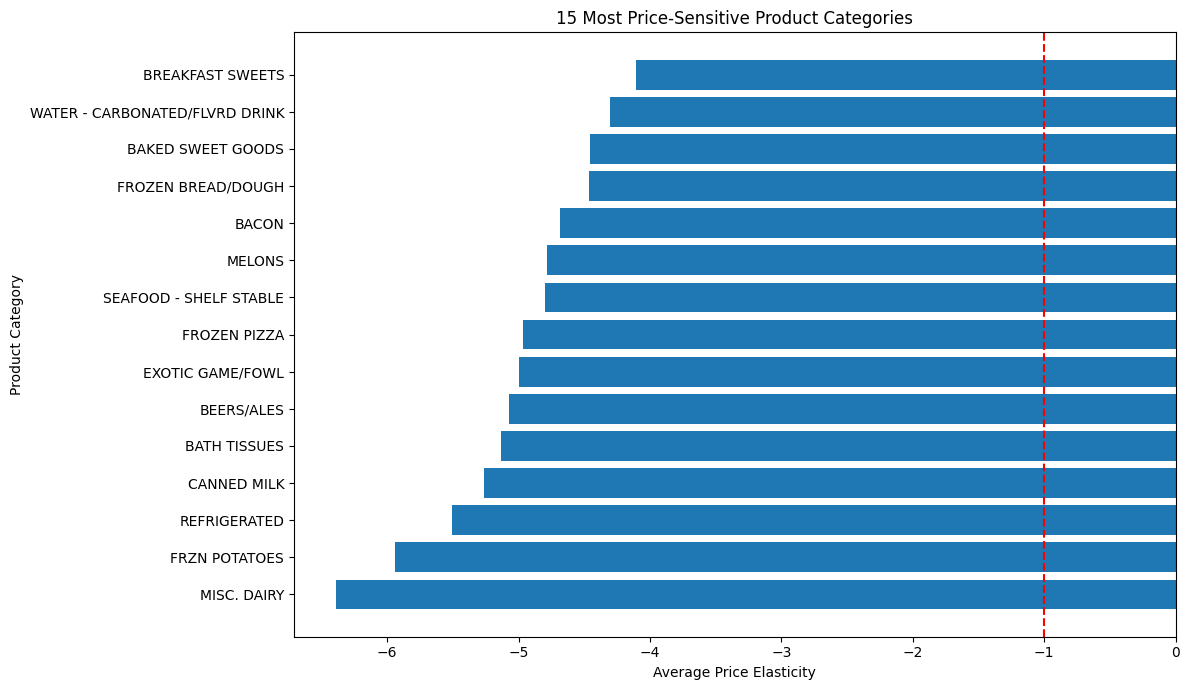

In [95]:
# Top 15 most price-sensitive categories
most_sensitive = commodity_analysis.nsmallest(
    15, "average_elasticity"
).sort_values("average_elasticity")

plt.figure(figsize=(12, 7))

plt.barh(
    most_sensitive["COMMODITY_DESC"],
    most_sensitive["average_elasticity"]
)

plt.xlabel("Average Price Elasticity")
plt.ylabel("Product Category")
plt.title("15 Most Price-Sensitive Product Categories")
plt.axvline(x=-1, linestyle="--", color="red")

plt.tight_layout()
plt.show()

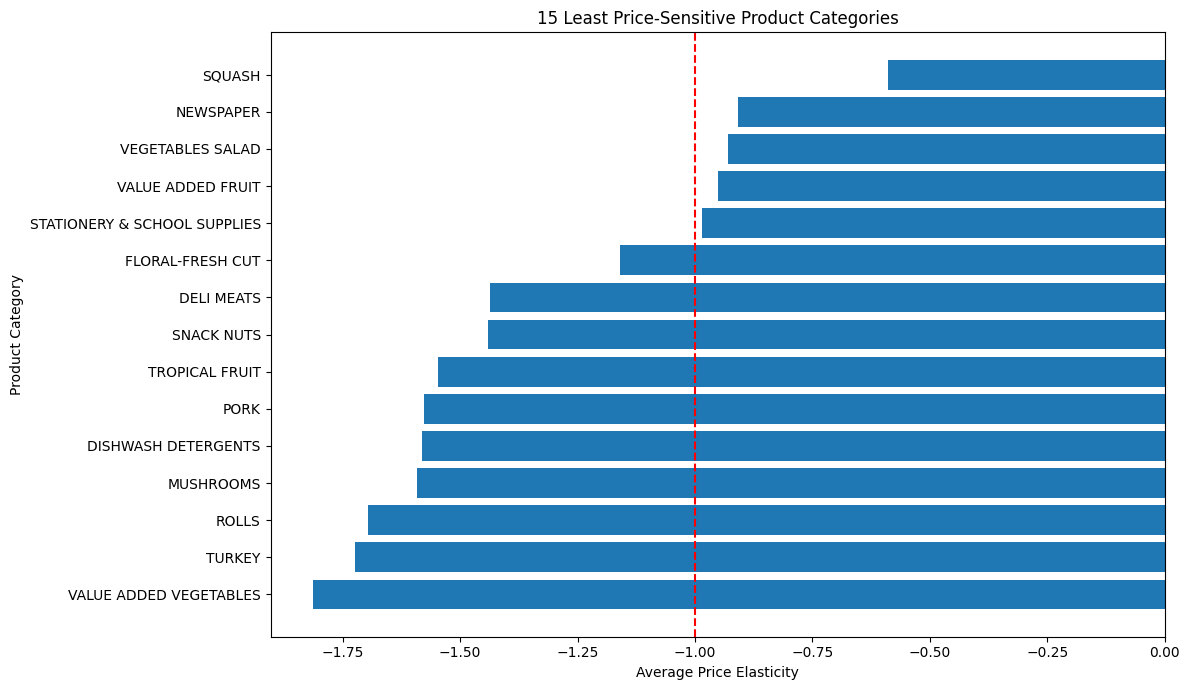

In [96]:
least_sensitive = commodity_analysis.nlargest(
    15, "average_elasticity"
).sort_values("average_elasticity")

plt.figure(figsize=(12, 7))

plt.barh(
    least_sensitive["COMMODITY_DESC"],
    least_sensitive["average_elasticity"]
)

plt.xlabel("Average Price Elasticity")
plt.ylabel("Product Category")
plt.title("15 Least Price-Sensitive Product Categories")
plt.axvline(x=-1, linestyle="--", color="red")

plt.tight_layout()
plt.show()

# Customer Segment Price Elasticity

In [97]:
# Examine the available customer segments

print("Total households:",
      grocery_df["household_key"].nunique())

print("\nHouseholds with demographic information:",
      grocery_df.dropna(subset=["INCOME_DESC"])
      ["household_key"].nunique())

print("\nIncome distribution:")

print(
    grocery_df.groupby("INCOME_DESC")["household_key"]
    .nunique()
    .sort_values(ascending=False)
)

Total households: 2500

Households with demographic information: 801

Income distribution:
INCOME_DESC
50-74K       192
35-49K       172
75-99K        96
25-34K        77
15-24K        74
Under 15K     61
125-149K      38
100-124K      34
150-174K      30
175-199K      11
250K+         11
200-249K       5
Name: household_key, dtype: int64


In [98]:
# Preserve households without demographic information
grocery_df["INCOME_DESC"] = (
    grocery_df["INCOME_DESC"].fillna("Unknown")
)

# Aggregate purchases by income group, product and week
segment_week = (
    grocery_df
    .groupby(["INCOME_DESC", "PRODUCT_ID", "WEEK_NO"])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

# Calculate average price
segment_week["average_price"] = (
    segment_week["total_sales"] /
    segment_week["total_quantity"]
)

# Calculate promotion share
segment_week["promotion_share"] = (
    segment_week["promotional_transactions"] /
    segment_week["transactions"]
)

print("Segment-level records:", len(segment_week))

segment_week.head()

Segment-level records: 1732379


,INCOME_DESC,PRODUCT_ID,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,average_price,promotion_share
0,100-124K,25671,23,1,3.49,1,0,3.49,0.0
1,100-124K,27658,15,1,0.99,1,0,0.99,0.0
2,100-124K,27658,16,1,0.79,1,1,0.79,1.0
3,100-124K,27735,16,1,2.99,1,0,2.99,0.0
4,100-124K,28143,16,1,0.55,1,0,0.55,0.0


In [99]:
# Number of observations per income group
income_summary = (
    segment_week
    .groupby("INCOME_DESC")
    .agg(
        total_records=("PRODUCT_ID", "count"),
        unique_products=("PRODUCT_ID", "nunique"),
        unique_weeks=("WEEK_NO", "nunique"),
        total_quantity=("total_quantity", "sum"),
        total_sales=("total_sales", "sum")
    )
    .reset_index()
)

income_summary.sort_values(
    "total_records",
    ascending=False
)

,INCOME_DESC,total_records,unique_products,unique_weeks,total_quantity,total_sales
12,Unknown,623852,70088,102,1511951,3302299.94
9,50-74K,248960,38760,102,437016,987816.55
8,35-49K,201111,32892,102,358944,753441.64
10,75-99K,134700,27971,102,215573,503853.45
6,25-34K,102316,23159,102,170841,350536.23
11,Under 15K,90465,20332,102,155065,309577.35
2,15-24K,84238,20280,102,136017,280562.98
1,125-149K,75216,21707,102,110293,266633.41
3,150-174K,61338,17574,101,87555,225362.08
0,100-124K,50789,14994,102,75473,174917.46


In [100]:
# Remove invalid values for logarithmic calculations
# without deleting any rows from segment_week

segment_week["log_price"] = np.where(
    segment_week["average_price"] > 0,
    np.log(segment_week["average_price"]),
    np.nan
)

segment_week["log_quantity"] = np.where(
    segment_week["total_quantity"] > 0,
    np.log(segment_week["total_quantity"]),
    np.nan
)

# Create a numerical time trend
segment_week["time_trend"] = (
    segment_week["WEEK_NO"] -
    segment_week["WEEK_NO"].min()
)

print("Total records:", len(segment_week))

print("\nMissing log prices:",
      segment_week["log_price"].isna().sum())

print("\nMissing log quantities:",
      segment_week["log_quantity"].isna().sum())

segment_week.head()

Total records: 1732379

Missing log prices: 0

Missing log quantities: 0


,INCOME_DESC,PRODUCT_ID,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,average_price,promotion_share,log_price,log_quantity,time_trend
0,100-124K,25671,23,1,3.49,1,0,3.49,0.0,1.249902,0.0,22
1,100-124K,27658,15,1,0.99,1,0,0.99,0.0,-0.010050,0.0,14
2,100-124K,27658,16,1,0.79,1,1,0.79,1.0,-0.235722,0.0,15
3,100-124K,27735,16,1,2.99,1,0,2.99,0.0,1.095273,0.0,15
4,100-124K,28143,16,1,0.55,1,0,0.55,0.0,-0.597837,0.0,15


In [101]:
# Create a separate modelling dataset
segment_model_data = segment_week.dropna(
    subset=["log_price", "log_quantity"]
).copy()

print("Original records:", len(segment_week))
print("Records available for modelling:", len(segment_model_data))
print(
    "Income groups:",
    segment_model_data["INCOME_DESC"].nunique()
)

Original records: 1732379
Records available for modelling: 1732379
Income groups: 13


In [102]:
import statsmodels.api as sm

segment_elasticity_results = []

for income in segment_model_data["INCOME_DESC"].unique():

    # Select one income group
    group_data = segment_model_data[
        segment_model_data["INCOME_DESC"] == income
    ].copy()

    # Remove product-specific average differences
    columns = [
        "log_price",
        "log_quantity",
        "promotion_share",
        "time_trend"
    ]

    group_means = group_data.groupby("PRODUCT_ID")[columns].transform("mean")

    for col in columns:
        group_data[col + "_within"] = (
            group_data[col] - group_means[col]
        )

    # Prepare regression variables
    X = group_data[
        [
            "log_price_within",
            "promotion_share_within",
            "time_trend_within"
        ]
    ]

    Y = group_data["log_quantity_within"]

    # Estimate regression with standard errors clustered by product
    model = sm.OLS(Y, X).fit(
        cov_type="cluster",
        cov_kwds={"groups": group_data["PRODUCT_ID"]}
    )

    segment_elasticity_results.append({
        "INCOME_DESC": income,
        "elasticity": model.params["log_price_within"],
        "p_value": model.pvalues["log_price_within"],
        "std_error": model.bse["log_price_within"],
        "lower_ci": model.conf_int().loc["log_price_within", 0],
        "upper_ci": model.conf_int().loc["log_price_within", 1],
        "r_squared": model.rsquared,
        "observations": len(group_data),
        "products": group_data["PRODUCT_ID"].nunique()
    })

print("Income group models completed:",
      len(segment_elasticity_results))

Income group models completed: 13


In [103]:
# Convert results into a DataFrame
segment_elasticity = pd.DataFrame(
    segment_elasticity_results
)

# Sort from most to least price-sensitive
segment_elasticity = segment_elasticity.sort_values(
    "elasticity"
)

# Display important results
segment_elasticity[
    [
        "INCOME_DESC",
        "elasticity",
        "lower_ci",
        "upper_ci",
        "p_value",
        "r_squared",
        "observations",
        "products"
    ]
].round(4)

,INCOME_DESC,elasticity,lower_ci,upper_ci,p_value,r_squared,observations,products
12,Unknown,-0.4453,-0.4719,-0.4187,0.0000,0.0463,623852,70088
8,35-49K,-0.3173,-0.3504,-0.2841,0.0000,0.0363,201111,32892
9,50-74K,-0.2913,-0.3204,-0.2622,0.0000,0.0331,248960,38760
6,25-34K,-0.2847,-0.3226,-0.2468,0.0000,0.0318,102316,23159
11,Under 15K,-0.2740,-0.3157,-0.2323,0.0000,0.0283,90465,20332
10,75-99K,-0.2617,-0.2978,-0.2257,0.0000,0.0301,134700,27971
2,15-24K,-0.2534,-0.2978,-0.2090,0.0000,0.0291,84238,20280
1,125-149K,-0.2236,-0.2634,-0.1838,0.0000,0.0215,75216,21707
0,100-124K,-0.1922,-0.2335,-0.1508,0.0000,0.0201,50789,14994
7,250K+,-0.1531,-0.2032,-0.1031,0.0000,0.0125,28880,10494


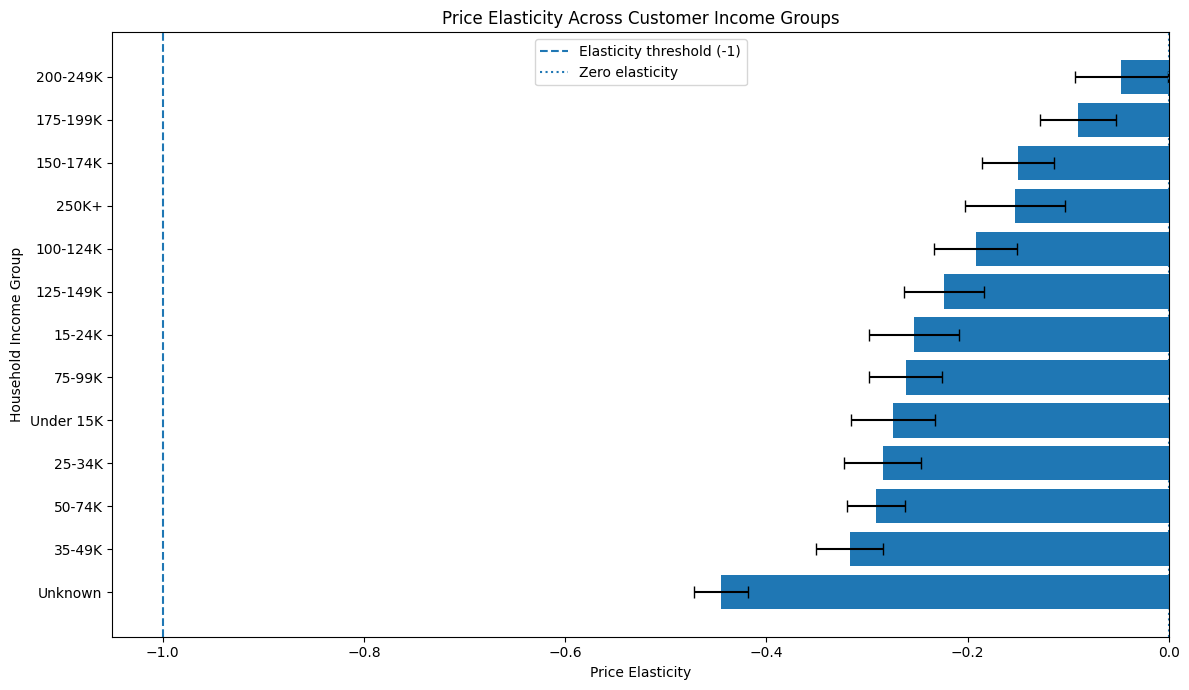

In [104]:
# Sort income groups by estimated elasticity
plot_data = segment_elasticity.sort_values(
    "elasticity"
).copy()

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["INCOME_DESC"],
    plot_data["elasticity"],
    xerr=[
        plot_data["elasticity"] - plot_data["lower_ci"],
        plot_data["upper_ci"] - plot_data["elasticity"]
    ],
    capsize=4
)

plt.axvline(
    x=-1,
    linestyle="--",
    label="Elasticity threshold (-1)"
)

plt.axvline(
    x=0,
    linestyle=":",
    label="Zero elasticity"
)

plt.xlabel("Price Elasticity")
plt.ylabel("Household Income Group")
plt.title("Price Elasticity Across Customer Income Groups")
plt.legend()
plt.tight_layout()
plt.show()

In [105]:
segment_elasticity["significant"] = (
    segment_elasticity["p_value"] < 0.05
)

segment_elasticity[
    [
        "INCOME_DESC",
        "elasticity",
        "p_value",
        "significant"
    ]
].sort_values("elasticity")

,INCOME_DESC,elasticity,p_value,significant
12,Unknown,-0.445290,1.180616e-236,True
8,35-49K,-0.317264,1.502569e-78,True
9,50-74K,-0.291298,1.692516e-85,True
6,25-34K,-0.284672,4.209526e-49,True
11,Under 15K,-0.273980,6.628391e-38,True
10,75-99K,-0.261746,7.046096e-46,True
2,15-24K,-0.253398,4.509266e-29,True
1,125-149K,-0.223580,3.494456e-28,True
0,100-124K,-0.192150,7.601735e-20,True
7,250K+,-0.153133,1.975726e-09,True


In [106]:
# Preserve households with missing age information
grocery_df["AGE_DESC"] = (
    grocery_df["AGE_DESC"].fillna("Unknown")
)

# Aggregate purchases by age, product and week
age_segment_week = (
    grocery_df
    .groupby(["AGE_DESC", "PRODUCT_ID", "WEEK_NO"])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

# Calculate average price
age_segment_week["average_price"] = (
    age_segment_week["total_sales"] /
    age_segment_week["total_quantity"]
)

# Calculate promotion share
age_segment_week["promotion_share"] = (
    age_segment_week["promotional_transactions"] /
    age_segment_week["transactions"]
)

# Create logarithmic variables
age_segment_week["log_price"] = np.log(
    age_segment_week["average_price"]
)

age_segment_week["log_quantity"] = np.log(
    age_segment_week["total_quantity"]
)

print("Age-based records:", len(age_segment_week))
print("Age groups:", age_segment_week["AGE_DESC"].nunique())

age_segment_week.head()

Age-based records: 1648929
Age groups: 7


,AGE_DESC,PRODUCT_ID,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,average_price,promotion_share,log_price,log_quantity
0,19-24,32456,65,1,2.50,1,1,2.500,1.0,0.916291,0.000000
1,19-24,32553,55,1,1.79,1,0,1.790,0.0,0.582216,0.000000
2,19-24,32553,56,2,2.79,2,1,1.395,0.5,0.332894,0.693147
3,19-24,32553,58,1,1.00,1,1,1.000,1.0,0.000000,0.000000
4,19-24,32553,59,1,1.79,1,0,1.790,0.0,0.582216,0.000000


In [107]:
age_summary = (
    age_segment_week
    .groupby("AGE_DESC")
    .agg(
        total_records=("PRODUCT_ID", "count"),
        unique_products=("PRODUCT_ID", "nunique"),
        total_quantity=("total_quantity", "sum"),
        total_sales=("total_sales", "sum")
    )
    .reset_index()
)

age_summary.sort_values(
    "total_records",
    ascending=False
)

,AGE_DESC,total_records,unique_products,total_quantity,total_sales
6,Unknown,623852,70088,1511951,3302299.94
3,45-54,345790,47784,673366,1510457.77
2,35-44,269904,40384,498558,1116033.11
1,25-34,187728,31746,310863,701378.38
5,65+,82633,19717,130252,282152.57
4,55-64,75374,19458,120064,268006.27
0,19-24,63648,16889,96633,202230.75


In [108]:
age_segment_model_data = age_segment_week.copy()

age_elasticity_results = []

for age in age_segment_model_data["AGE_DESC"].unique():

    # Select one age group
    group_data = age_segment_model_data[
        age_segment_model_data["AGE_DESC"] == age
    ].copy()

    columns = [
        "log_price",
        "log_quantity",
        "promotion_share"
    ]

    # Calculate product-specific means
    group_means = group_data.groupby(
        "PRODUCT_ID"
    )[columns].transform("mean")

    # Calculate within-product variations
    for col in columns:
        group_data[col + "_within"] = (
            group_data[col] - group_means[col]
        )

    # Prepare regression variables
    X = group_data[
        [
            "log_price_within",
            "promotion_share_within"
        ]
    ]

    Y = group_data["log_quantity_within"]

    # Estimate regression
    model = sm.OLS(Y, X).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": group_data["PRODUCT_ID"]
        }
    )

    age_elasticity_results.append({
        "AGE_DESC": age,
        "elasticity": model.params["log_price_within"],
        "p_value": model.pvalues["log_price_within"],
        "std_error": model.bse["log_price_within"],
        "lower_ci": model.conf_int().loc["log_price_within", 0],
        "upper_ci": model.conf_int().loc["log_price_within", 1],
        "r_squared": model.rsquared,
        "observations": len(group_data),
        "products": group_data["PRODUCT_ID"].nunique()
    })

print("Age group models completed:",
      len(age_elasticity_results))

Age group models completed: 7


In [109]:
age_elasticity = pd.DataFrame(age_elasticity_results)

age_elasticity.sort_values("elasticity")

,AGE_DESC,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
6,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
3,45-54,-0.343195,7.093920e-127,0.014323,-0.371268,-0.315123,0.035040,345790,47784
2,35-44,-0.338373,3.287621e-118,0.014639,-0.367065,-0.309682,0.035416,269904,40384
1,25-34,-0.250602,6.450722e-67,0.014501,-0.279024,-0.222181,0.021189,187728,31746
4,55-64,-0.233650,6.884408e-26,0.022207,-0.277176,-0.190125,0.033543,75374,19458
0,19-24,-0.209714,4.853466e-21,0.022281,-0.253384,-0.166044,0.016717,63648,16889
5,65+,-0.202354,2.048868e-23,0.020295,-0.242132,-0.162577,0.025948,82633,19717


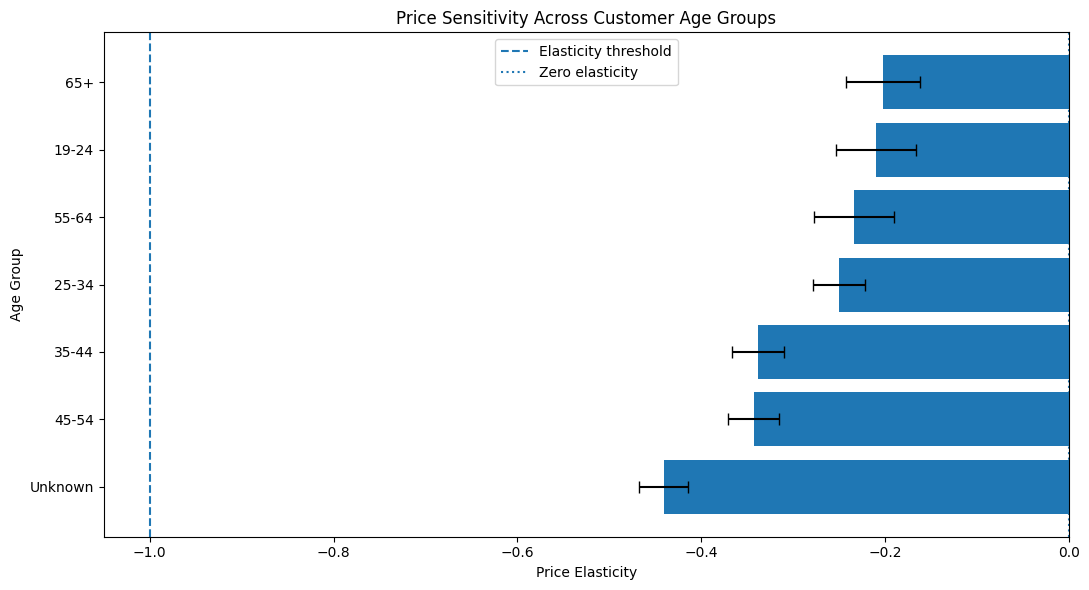

In [110]:
age_plot = age_elasticity.sort_values("elasticity")

plt.figure(figsize=(11, 6))

plt.barh(
    age_plot["AGE_DESC"],
    age_plot["elasticity"],
    xerr=[
        age_plot["elasticity"] - age_plot["lower_ci"],
        age_plot["upper_ci"] - age_plot["elasticity"]
    ],
    capsize=4
)

plt.axvline(x=-1, linestyle="--", label="Elasticity threshold")
plt.axvline(x=0, linestyle=":", label="Zero elasticity")

plt.xlabel("Price Elasticity")
plt.ylabel("Age Group")
plt.title("Price Sensitivity Across Customer Age Groups")

plt.legend()
plt.tight_layout()
plt.show()

In [111]:
grocery_df["HOUSEHOLD_SIZE_DESC"] = (
    grocery_df["HOUSEHOLD_SIZE_DESC"].fillna("Unknown")
)

household_segment_week = (
    grocery_df
    .groupby([
        "HOUSEHOLD_SIZE_DESC",
        "PRODUCT_ID",
        "WEEK_NO"
    ])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

household_segment_week["average_price"] = (
    household_segment_week["total_sales"] /
    household_segment_week["total_quantity"]
)

household_segment_week["promotion_share"] = (
    household_segment_week["promotional_transactions"] /
    household_segment_week["transactions"]
)

household_segment_week["log_price"] = np.log(
    household_segment_week["average_price"]
)

household_segment_week["log_quantity"] = np.log(
    household_segment_week["total_quantity"]
)

print("Records:", len(household_segment_week))

print(
    household_segment_week["HOUSEHOLD_SIZE_DESC"].value_counts()
)

Records: 1633029
HOUSEHOLD_SIZE_DESC
Unknown    623852
2          360167
1          285139
3          163815
5+         107862
4           92194
Name: count, dtype: int64


In [112]:
household_elasticity_results = []

for size in household_segment_week["HOUSEHOLD_SIZE_DESC"].unique():

    # Select one household-size group
    group_data = household_segment_week[
        household_segment_week["HOUSEHOLD_SIZE_DESC"] == size
    ].copy()

    columns = [
        "log_price",
        "log_quantity",
        "promotion_share"
    ]

    # Calculate product-specific means
    group_means = group_data.groupby(
        "PRODUCT_ID"
    )[columns].transform("mean")

    # Calculate within-product variations
    for col in columns:
        group_data[col + "_within"] = (
            group_data[col] - group_means[col]
        )

    # Prepare regression variables
    X = group_data[
        [
            "log_price_within",
            "promotion_share_within"
        ]
    ]

    Y = group_data["log_quantity_within"]

    # Estimate regression
    model = sm.OLS(Y, X).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": group_data["PRODUCT_ID"]
        }
    )

    household_elasticity_results.append({
        "HOUSEHOLD_SIZE_DESC": size,
        "elasticity": model.params["log_price_within"],
        "p_value": model.pvalues["log_price_within"],
        "std_error": model.bse["log_price_within"],
        "lower_ci": model.conf_int().loc["log_price_within", 0],
        "upper_ci": model.conf_int().loc["log_price_within", 1],
        "r_squared": model.rsquared,
        "observations": len(group_data),
        "products": group_data["PRODUCT_ID"].nunique()
    })

print("Household-size models completed:",
      len(household_elasticity_results))

Household-size models completed: 6


In [113]:
household_elasticity = pd.DataFrame(
    household_elasticity_results
)

household_elasticity.sort_values("elasticity")

,HOUSEHOLD_SIZE_DESC,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
5,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
2,3,-0.325613,7.710046e-74,0.017912,-0.360721,-0.290505,0.032756,163815,30354
1,2,-0.323589,1.443189e-124,0.013631,-0.350306,-0.296872,0.032452,360167,48044
0,1,-0.317717,4.901465e-111,0.014190,-0.345528,-0.289905,0.031778,285139,41322
4,5+,-0.293587,9.218498e-53,0.019204,-0.331226,-0.255948,0.030790,107862,23845
3,4,-0.258186,4.429439e-35,0.020893,-0.299135,-0.217237,0.028334,92194,21863


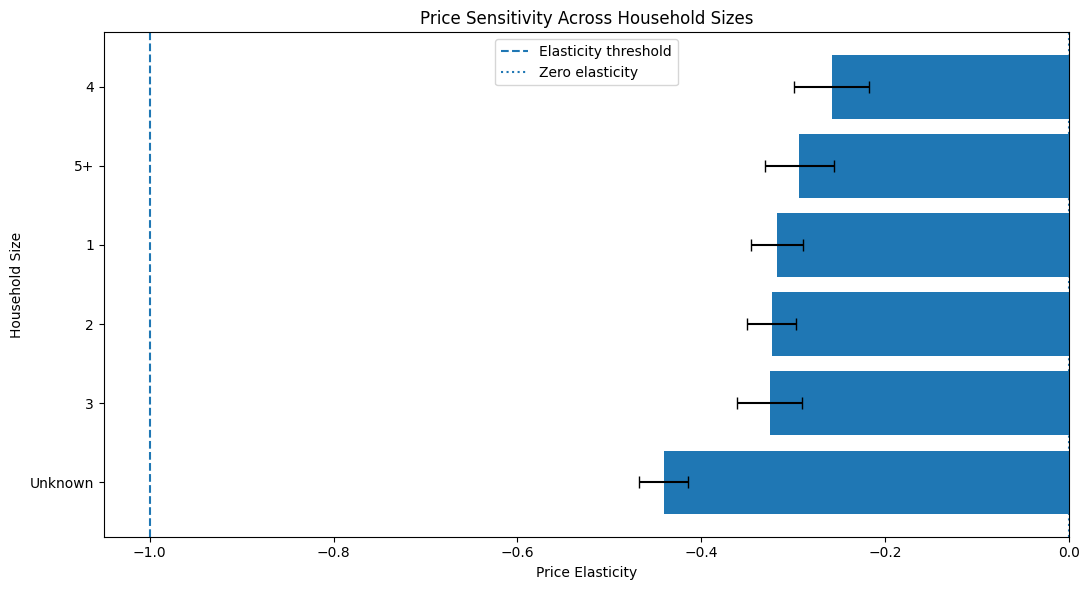

In [114]:
household_plot = household_elasticity.sort_values(
    "elasticity"
)

plt.figure(figsize=(11, 6))

plt.barh(
    household_plot["HOUSEHOLD_SIZE_DESC"],
    household_plot["elasticity"],
    xerr=[
        household_plot["elasticity"] - household_plot["lower_ci"],
        household_plot["upper_ci"] - household_plot["elasticity"]
    ],
    capsize=4
)

plt.axvline(x=-1, linestyle="--", label="Elasticity threshold")
plt.axvline(x=0, linestyle=":", label="Zero elasticity")

plt.xlabel("Price Elasticity")
plt.ylabel("Household Size")
plt.title("Price Sensitivity Across Household Sizes")

plt.legend()
plt.tight_layout()
plt.show()

In [115]:
grocery_df["MARITAL_STATUS_CODE"] = (
    grocery_df["MARITAL_STATUS_CODE"].fillna("Unknown")
)

marital_segment_week = (
    grocery_df
    .groupby([
        "MARITAL_STATUS_CODE",
        "PRODUCT_ID",
        "WEEK_NO"
    ])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

marital_segment_week["average_price"] = (
    marital_segment_week["total_sales"] /
    marital_segment_week["total_quantity"]
)

marital_segment_week["promotion_share"] = (
    marital_segment_week["promotional_transactions"] /
    marital_segment_week["transactions"]
)

marital_segment_week["log_price"] = np.log(
    marital_segment_week["average_price"]
)

marital_segment_week["log_quantity"] = np.log(
    marital_segment_week["total_quantity"]
)

print("Records:", len(marital_segment_week))

print(
    marital_segment_week["MARITAL_STATUS_CODE"].value_counts()
)

Records: 1557120
MARITAL_STATUS_CODE
Unknown    623852
A          408185
U          375153
B          149930
Name: count, dtype: int64


In [116]:
grocery_df["MARITAL_STATUS_CODE"] = (
    grocery_df["MARITAL_STATUS_CODE"].fillna("Unknown")
)

marital_segment_week = (
    grocery_df
    .groupby([
        "MARITAL_STATUS_CODE",
        "PRODUCT_ID",
        "WEEK_NO"
    ])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

marital_segment_week["average_price"] = (
    marital_segment_week["total_sales"] /
    marital_segment_week["total_quantity"]
)

marital_segment_week["promotion_share"] = (
    marital_segment_week["promotional_transactions"] /
    marital_segment_week["transactions"]
)

marital_segment_week["log_price"] = np.log(
    marital_segment_week["average_price"]
)

marital_segment_week["log_quantity"] = np.log(
    marital_segment_week["total_quantity"]
)

print("Records:", len(marital_segment_week))

print(
    marital_segment_week["MARITAL_STATUS_CODE"].value_counts()
)

Records: 1557120
MARITAL_STATUS_CODE
Unknown    623852
A          408185
U          375153
B          149930
Name: count, dtype: int64


In [117]:
marital_segment_week.groupby("MARITAL_STATUS_CODE").agg(
    records=("PRODUCT_ID", "count"),
    products=("PRODUCT_ID", "nunique"),
    total_quantity=("total_quantity", "sum"),
    total_sales=("total_sales", "sum")
).sort_values("records", ascending=False)

,records,products,total_quantity,total_sales
MARITAL_STATUS_CODE,,,,
Unknown,623852,70088,1511951,3302299.94
A,408185,50520,821137,1879175.77
U,375153,47359,764555,1650590.70
B,149930,29521,244044,550492.38


In [118]:
marital_elasticity_results = []

for status in marital_segment_week["MARITAL_STATUS_CODE"].unique():

    group_data = marital_segment_week[
        marital_segment_week["MARITAL_STATUS_CODE"] == status
    ].copy()

    columns = [
        "log_price",
        "log_quantity",
        "promotion_share"
    ]

    group_means = (
        group_data.groupby("PRODUCT_ID")[columns]
        .transform("mean")
    )

    for col in columns:
        group_data[col + "_within"] = (
            group_data[col] - group_means[col]
        )

    X = group_data[
        ["log_price_within", "promotion_share_within"]
    ]

    Y = group_data["log_quantity_within"]

    model = sm.OLS(Y, X).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": group_data["PRODUCT_ID"]
        }
    )

    marital_elasticity_results.append({
        "MARITAL_STATUS_CODE": status,
        "elasticity": model.params["log_price_within"],
        "p_value": model.pvalues["log_price_within"],
        "std_error": model.bse["log_price_within"],
        "lower_ci": model.conf_int().loc["log_price_within", 0],
        "upper_ci": model.conf_int().loc["log_price_within", 1],
        "r_squared": model.rsquared,
        "observations": len(group_data),
        "products": group_data["PRODUCT_ID"].nunique()
    })

marital_elasticity = pd.DataFrame(
    marital_elasticity_results
)

marital_elasticity = marital_elasticity.sort_values(
    "elasticity"
)

marital_elasticity

,MARITAL_STATUS_CODE,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
3,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
2,U,-0.375526,3.784059e-156,0.014106,-0.403173,-0.347879,0.037180,375153,47359
0,A,-0.360644,2.539876e-160,0.013367,-0.386843,-0.334445,0.036185,408185,50520
1,B,-0.228117,1.246278e-44,0.016276,-0.260017,-0.196217,0.024905,149930,29521


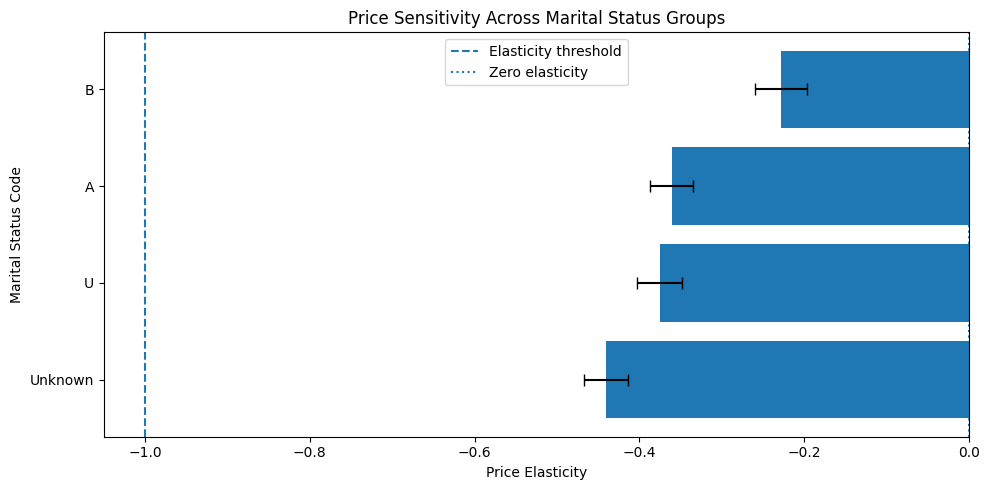

In [119]:
marital_plot = marital_elasticity.sort_values(
    "elasticity"
)

plt.figure(figsize=(10, 5))

plt.barh(
    marital_plot["MARITAL_STATUS_CODE"],
    marital_plot["elasticity"],
    xerr=[
        marital_plot["elasticity"] - marital_plot["lower_ci"],
        marital_plot["upper_ci"] - marital_plot["elasticity"]
    ],
    capsize=4
)

plt.axvline(x=-1, linestyle="--", label="Elasticity threshold")
plt.axvline(x=0, linestyle=":", label="Zero elasticity")

plt.xlabel("Price Elasticity")
plt.ylabel("Marital Status Code")
plt.title("Price Sensitivity Across Marital Status Groups")

plt.legend()
plt.tight_layout()
plt.show()

In [120]:
grocery_df["HOMEOWNER_DESC"] = (
    grocery_df["HOMEOWNER_DESC"].fillna("Unknown")
)

homeowner_segment_week = (
    grocery_df
    .groupby([
        "HOMEOWNER_DESC",
        "PRODUCT_ID",
        "WEEK_NO"
    ])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

homeowner_segment_week["average_price"] = (
    homeowner_segment_week["total_sales"] /
    homeowner_segment_week["total_quantity"]
)

homeowner_segment_week["promotion_share"] = (
    homeowner_segment_week["promotional_transactions"] /
    homeowner_segment_week["transactions"]
)

homeowner_segment_week["log_price"] = np.log(
    homeowner_segment_week["average_price"]
)

homeowner_segment_week["log_quantity"] = np.log(
    homeowner_segment_week["total_quantity"]
)

print("Records:", len(homeowner_segment_week))

print(
    homeowner_segment_week["HOMEOWNER_DESC"].value_counts()
)

Records: 1396944
HOMEOWNER_DESC
Unknown            754581
Homeowner          539375
Renter              69674
Probable Owner      18300
Probable Renter     15014
Name: count, dtype: int64


In [121]:
homeowner_segment_week.groupby("HOMEOWNER_DESC").agg(
    records=("PRODUCT_ID", "count"),
    products=("PRODUCT_ID", "nunique"),
    total_quantity=("total_quantity", "sum"),
    total_sales=("total_sales", "sum")
).sort_values("records", ascending=False)

,records,products,total_quantity,total_sales
HOMEOWNER_DESC,,,,
Unknown,754581,76067,2007876,4344909.17
Homeowner,539375,58288,1183166,2728953.58
Renter,69674,18488,103935,214866.33
Probable Owner,18300,6537,25568,51530.80
Probable Renter,15014,5674,21142,42298.91


In [122]:
homeowner_elasticity_results = []

for status in homeowner_segment_week["HOMEOWNER_DESC"].unique():

    group_data = homeowner_segment_week[
        homeowner_segment_week["HOMEOWNER_DESC"] == status
    ].copy()

    columns = [
        "log_price",
        "log_quantity",
        "promotion_share"
    ]

    group_means = (
        group_data.groupby("PRODUCT_ID")[columns]
        .transform("mean")
    )

    for col in columns:
        group_data[col + "_within"] = (
            group_data[col] - group_means[col]
        )

    X = group_data[
        ["log_price_within", "promotion_share_within"]
    ]

    Y = group_data["log_quantity_within"]

    model = sm.OLS(Y, X).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": group_data["PRODUCT_ID"]
        }
    )

    homeowner_elasticity_results.append({
        "HOMEOWNER_DESC": status,
        "elasticity": model.params["log_price_within"],
        "p_value": model.pvalues["log_price_within"],
        "std_error": model.bse["log_price_within"],
        "lower_ci": model.conf_int().loc["log_price_within", 0],
        "upper_ci": model.conf_int().loc["log_price_within", 1],
        "r_squared": model.rsquared,
        "observations": len(group_data),
        "products": group_data["PRODUCT_ID"].nunique()
    })

homeowner_elasticity = pd.DataFrame(
    homeowner_elasticity_results
)

homeowner_elasticity = homeowner_elasticity.sort_values(
    "elasticity"
)

homeowner_elasticity

,HOMEOWNER_DESC,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
4,Unknown,-0.482902,1.521847e-284,0.013396,-0.509158,-0.456645,0.047211,754581,76067
0,Homeowner,-0.395437,3.053425e-199,0.013131,-0.421172,-0.369701,0.039200,539375,58288
3,Renter,-0.216487,1.255200e-24,0.021132,-0.257905,-0.175068,0.022431,69674,18488
1,Probable Owner,-0.148728,7.698817e-09,0.025754,-0.199205,-0.098251,0.014772,18300,6537
2,Probable Renter,-0.116350,1.768895e-04,0.031027,-0.177163,-0.055538,0.011302,15014,5674


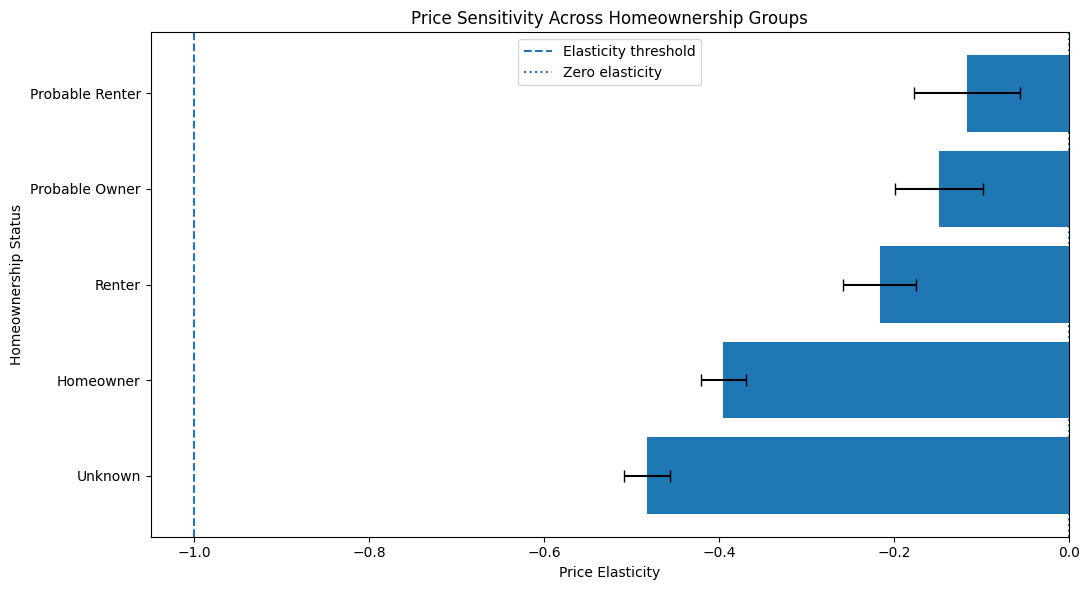

In [123]:
homeowner_plot = homeowner_elasticity.sort_values(
    "elasticity"
)

plt.figure(figsize=(11, 6))

plt.barh(
    homeowner_plot["HOMEOWNER_DESC"],
    homeowner_plot["elasticity"],
    xerr=[
        homeowner_plot["elasticity"] - homeowner_plot["lower_ci"],
        homeowner_plot["upper_ci"] - homeowner_plot["elasticity"]
    ],
    capsize=4
)

plt.axvline(x=-1, linestyle="--", label="Elasticity threshold")
plt.axvline(x=0, linestyle=":", label="Zero elasticity")

plt.xlabel("Price Elasticity")
plt.ylabel("Homeownership Status")
plt.title("Price Sensitivity Across Homeownership Groups")

plt.legend()
plt.tight_layout()
plt.show()

In [124]:
grocery_df["HH_COMP_DESC"] = (
    grocery_df["HH_COMP_DESC"].fillna("Unknown")
)

composition_segment_week = (
    grocery_df
    .groupby([
        "HH_COMP_DESC",
        "PRODUCT_ID",
        "WEEK_NO"
    ])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

composition_segment_week["average_price"] = (
    composition_segment_week["total_sales"] /
    composition_segment_week["total_quantity"]
)

composition_segment_week["promotion_share"] = (
    composition_segment_week["promotional_transactions"] /
    composition_segment_week["transactions"]
)

composition_segment_week["log_price"] = np.log(
    composition_segment_week["average_price"]
)

composition_segment_week["log_quantity"] = np.log(
    composition_segment_week["total_quantity"]
)

print("Records:", len(composition_segment_week))

print(
    composition_segment_week["HH_COMP_DESC"].value_counts()
)

Records: 1612151
HH_COMP_DESC
Unknown             669533
2 Adults No Kids    306772
2 Adults Kids       264155
Single Female       172975
Single Male         117591
1 Adult Kids         81125
Name: count, dtype: int64


In [125]:
composition_segment_week.groupby("HH_COMP_DESC").agg(
    records=("PRODUCT_ID", "count"),
    products=("PRODUCT_ID", "nunique"),
    total_quantity=("total_quantity", "sum"),
    total_sales=("total_sales", "sum")
).sort_values("records", ascending=False)

,records,products,total_quantity,total_sales
HH_COMP_DESC,,,,
Unknown,669533,72175,1668383,3645984.83
2 Adults No Kids,306772,44808,569970,1317478.51
2 Adults Kids,264155,39257,487941,1086658.01
Single Female,172975,31510,298150,645867.00
Single Male,117591,25982,187183,418048.02
1 Adult Kids,81125,19037,130060,268522.42


In [126]:
composition_elasticity_results = []

for composition in composition_segment_week["HH_COMP_DESC"].unique():

    group_data = composition_segment_week[
        composition_segment_week["HH_COMP_DESC"] == composition
    ].copy()

    columns = [
        "log_price",
        "log_quantity",
        "promotion_share"
    ]

    group_means = (
        group_data.groupby("PRODUCT_ID")[columns]
        .transform("mean")
    )

    for col in columns:
        group_data[col + "_within"] = (
            group_data[col] - group_means[col]
        )

    X = group_data[
        ["log_price_within", "promotion_share_within"]
    ]

    Y = group_data["log_quantity_within"]

    model = sm.OLS(Y, X).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": group_data["PRODUCT_ID"]
        }
    )

    composition_elasticity_results.append({
        "HH_COMP_DESC": composition,
        "elasticity": model.params["log_price_within"],
        "p_value": model.pvalues["log_price_within"],
        "std_error": model.bse["log_price_within"],
        "lower_ci": model.conf_int().loc["log_price_within", 0],
        "upper_ci": model.conf_int().loc["log_price_within", 1],
        "r_squared": model.rsquared,
        "observations": len(group_data),
        "products": group_data["PRODUCT_ID"].nunique()
    })

composition_elasticity = pd.DataFrame(
    composition_elasticity_results
)

composition_elasticity = composition_elasticity.sort_values(
    "elasticity"
)

composition_elasticity

,HH_COMP_DESC,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
5,Unknown,-0.456887,8.145176e-261,0.013243,-0.482844,-0.430931,0.044885,669533,72175
1,2 Adults Kids,-0.375829,2.638029e-126,0.015721,-0.406642,-0.345017,0.037733,264155,39257
2,2 Adults No Kids,-0.305327,2.027537e-98,0.014501,-0.333748,-0.276906,0.030848,306772,44808
3,Single Female,-0.273378,3.089594e-61,0.016558,-0.305832,-0.240925,0.029017,172975,31510
0,1 Adult Kids,-0.245227,2.206640e-30,0.021407,-0.287184,-0.203271,0.025030,81125,19037
4,Single Male,-0.185968,1.906387e-35,0.014967,-0.215302,-0.156633,0.019736,117591,25982


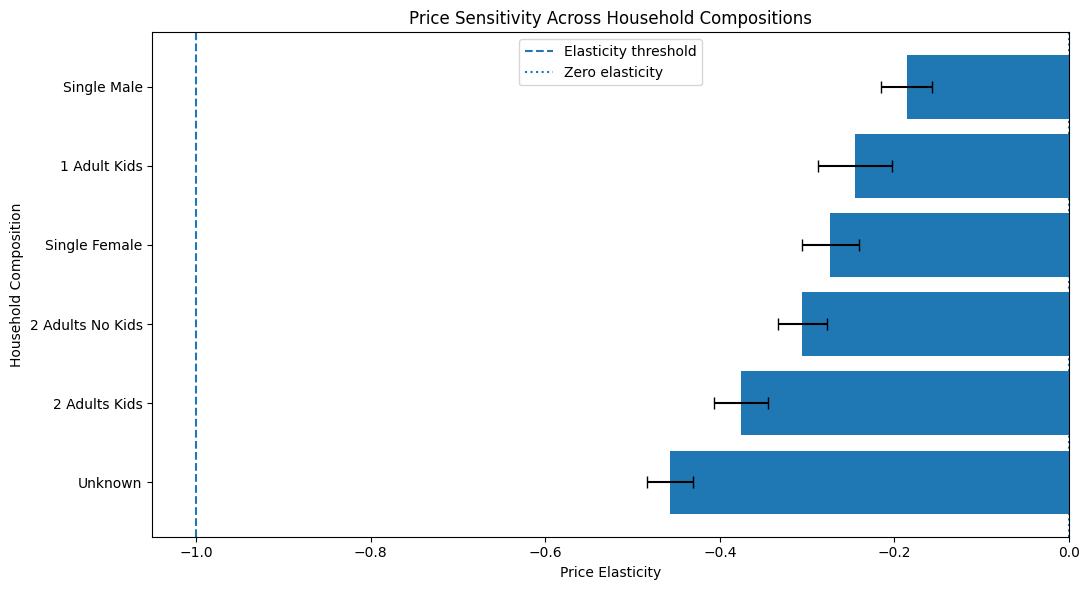

In [127]:
composition_plot = composition_elasticity.sort_values(
    "elasticity"
)

plt.figure(figsize=(11, 6))

plt.barh(
    composition_plot["HH_COMP_DESC"],
    composition_plot["elasticity"],
    xerr=[
        composition_plot["elasticity"] - composition_plot["lower_ci"],
        composition_plot["upper_ci"] - composition_plot["elasticity"]
    ],
    capsize=4
)

plt.axvline(x=-1, linestyle="--", label="Elasticity threshold")
plt.axvline(x=0, linestyle=":", label="Zero elasticity")

plt.xlabel("Price Elasticity")
plt.ylabel("Household Composition")
plt.title("Price Sensitivity Across Household Compositions")

plt.legend()
plt.tight_layout()
plt.show()

In [128]:
# Combine all demographic elasticity results

income_results = segment_elasticity.copy()
income_results["segment_dimension"] = "Income"
income_results = income_results.rename(
    columns={"INCOME_DESC": "segment"}
)

age_results = age_elasticity.copy()
age_results["segment_dimension"] = "Age"
age_results = age_results.rename(
    columns={"AGE_DESC": "segment"}
)

household_results = household_elasticity.copy()
household_results["segment_dimension"] = "Household Size"
household_results = household_results.rename(
    columns={"HOUSEHOLD_SIZE_DESC": "segment"}
)

marital_results = marital_elasticity.copy()
marital_results["segment_dimension"] = "Marital Status"
marital_results = marital_results.rename(
    columns={"MARITAL_STATUS_CODE": "segment"}
)

homeowner_results = homeowner_elasticity.copy()
homeowner_results["segment_dimension"] = "Homeownership"
homeowner_results = homeowner_results.rename(
    columns={"HOMEOWNER_DESC": "segment"}
)

composition_results = composition_elasticity.copy()
composition_results["segment_dimension"] = "Household Composition"
composition_results = composition_results.rename(
    columns={"HH_COMP_DESC": "segment"}
)

# Combine everything
all_segment_results = pd.concat(
    [
        income_results,
        age_results,
        household_results,
        marital_results,
        homeowner_results,
        composition_results
    ],
    ignore_index=True
)

# Arrange the columns
all_segment_results = all_segment_results[
    [
        "segment_dimension",
        "segment",
        "elasticity",
        "p_value",
        "std_error",
        "lower_ci",
        "upper_ci",
        "r_squared",
        "observations",
        "products"
    ]
]

all_segment_results = all_segment_results.sort_values(
    "elasticity"
).reset_index(drop=True)

all_segment_results

,segment_dimension,segment,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
0,Homeownership,Unknown,-0.482902,1.521847e-284,0.013396,-0.509158,-0.456645,0.047211,754581,76067
1,Household Composition,Unknown,-0.456887,8.145176e-261,0.013243,-0.482844,-0.430931,0.044885,669533,72175
2,Income,Unknown,-0.445290,1.180616e-236,0.013556,-0.471858,-0.418721,0.046323,623852,70088
3,Age,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
4,Marital Status,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
5,Household Size,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
6,Homeownership,Homeowner,-0.395437,3.053425e-199,0.013131,-0.421172,-0.369701,0.039200,539375,58288
7,Household Composition,2 Adults Kids,-0.375829,2.638029e-126,0.015721,-0.406642,-0.345017,0.037733,264155,39257
8,Marital Status,U,-0.375526,3.784059e-156,0.014106,-0.403173,-0.347879,0.037180,375153,47359
9,Marital Status,A,-0.360644,2.539876e-160,0.013367,-0.386843,-0.334445,0.036185,408185,50520


In [129]:
print("MOST PRICE-SENSITIVE SEGMENTS")

display(
    all_segment_results
    .sort_values("elasticity")
    .head(10)
)

print("LEAST PRICE-SENSITIVE SEGMENTS")

display(
    all_segment_results
    .sort_values("elasticity", ascending=False)
    .head(10)
)

MOST PRICE-SENSITIVE SEGMENTS


,segment_dimension,segment,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
0,Homeownership,Unknown,-0.482902,1.521847e-284,0.013396,-0.509158,-0.456645,0.047211,754581,76067
1,Household Composition,Unknown,-0.456887,8.145176e-261,0.013243,-0.482844,-0.430931,0.044885,669533,72175
2,Income,Unknown,-0.445290,1.180616e-236,0.013556,-0.471858,-0.418721,0.046323,623852,70088
3,Age,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
4,Marital Status,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
5,Household Size,Unknown,-0.440896,9.503354e-232,0.013565,-0.467483,-0.414310,0.043556,623852,70088
6,Homeownership,Homeowner,-0.395437,3.053425e-199,0.013131,-0.421172,-0.369701,0.039200,539375,58288
7,Household Composition,2 Adults Kids,-0.375829,2.638029e-126,0.015721,-0.406642,-0.345017,0.037733,264155,39257
8,Marital Status,U,-0.375526,3.784059e-156,0.014106,-0.403173,-0.347879,0.037180,375153,47359
9,Marital Status,A,-0.360644,2.539876e-160,0.013367,-0.386843,-0.334445,0.036185,408185,50520


LEAST PRICE-SENSITIVE SEGMENTS


,segment_dimension,segment,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
40,Income,200-249K,-0.047321,4.290925e-02,0.023373,-0.093132,-0.001511,0.007227,7532,3726
39,Income,175-199K,-0.090709,2.891813e-06,0.019389,-0.128711,-0.052707,0.010586,22982,9034
38,Homeownership,Probable Renter,-0.116350,1.768895e-04,0.031027,-0.177163,-0.055538,0.011302,15014,5674
37,Homeownership,Probable Owner,-0.148728,7.698817e-09,0.025754,-0.199205,-0.098251,0.014772,18300,6537
36,Income,150-174K,-0.150042,3.774219e-16,0.018420,-0.186145,-0.113939,0.015801,61338,17574
35,Income,250K+,-0.153133,1.975726e-09,0.025523,-0.203157,-0.103108,0.012468,28880,10494
34,Household Composition,Single Male,-0.185968,1.906387e-35,0.014967,-0.215302,-0.156633,0.019736,117591,25982
33,Income,100-124K,-0.192150,7.601735e-20,0.021072,-0.233451,-0.150850,0.020086,50789,14994
32,Age,65+,-0.202354,2.048868e-23,0.020295,-0.242132,-0.162577,0.025948,82633,19717
31,Age,19-24,-0.209714,4.853466e-21,0.022281,-0.253384,-0.166044,0.016717,63648,16889


In [130]:
# Select the demographic information

demographic_data = grocery_df[
    [
        "PRODUCT_ID",
        "WEEK_NO",
        "household_key",
        "INCOME_DESC",
        "AGE_DESC",
        "HOUSEHOLD_SIZE_DESC",
        "MARITAL_STATUS_CODE",
        "HOMEOWNER_DESC",
        "HH_COMP_DESC"
    ]
].copy()

# Check the dataset

print("Records:", len(demographic_data))

print("\nMissing values:")
print(demographic_data.isnull().sum())

demographic_data.head()

Records: 2546481

Missing values:
PRODUCT_ID             0
WEEK_NO                0
household_key          0
INCOME_DESC            0
AGE_DESC               0
HOUSEHOLD_SIZE_DESC    0
MARITAL_STATUS_CODE    0
HOMEOWNER_DESC         0
HH_COMP_DESC           0
dtype: int64


,PRODUCT_ID,WEEK_NO,household_key,INCOME_DESC,AGE_DESC,HOUSEHOLD_SIZE_DESC,MARITAL_STATUS_CODE,HOMEOWNER_DESC,HH_COMP_DESC
0,1004906,1,2375,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
1,1033142,1,2375,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
2,1036325,1,2375,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
3,1082185,1,2375,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
4,8160430,1,2375,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown


In [131]:
# Get each household's demographic profile
household_segments = (
    grocery_df[
        [
            "household_key",
            "INCOME_DESC",
            "AGE_DESC",
            "HOUSEHOLD_SIZE_DESC"
        ]
    ]
    .drop_duplicates(subset="household_key")
    .copy()
)

# Count households in each combined segment
combined_segment_counts = (
    household_segments
    .groupby(
        ["INCOME_DESC", "AGE_DESC", "HOUSEHOLD_SIZE_DESC"],
        dropna=False
    )
    .agg(
        households=("household_key", "nunique")
    )
    .reset_index()
    .sort_values("households", ascending=False)
)

print("Number of combined segments:", len(combined_segment_counts))

combined_segment_counts.head(20)


Number of combined segments: 204


,INCOME_DESC,AGE_DESC,HOUSEHOLD_SIZE_DESC,households
203,Unknown,Unknown,Unknown,1699
149,50-74K,45-54,1,38
150,50-74K,45-54,2,30
123,35-49K,45-54,1,19
172,75-99K,45-54,2,18
124,35-49K,45-54,2,17
119,35-49K,35-44,2,16
145,50-74K,35-44,2,15
139,50-74K,25-34,1,14
144,50-74K,35-44,1,14


In [132]:
combined_segment_week = (
    grocery_df
    .groupby([
        "INCOME_DESC",
        "AGE_DESC",
        "HOUSEHOLD_SIZE_DESC",
        "PRODUCT_ID",
        "WEEK_NO"
    ])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

# Calculate average price
combined_segment_week["average_price"] = (
    combined_segment_week["total_sales"] /
    combined_segment_week["total_quantity"]
)

# Calculate promotion share
combined_segment_week["promotion_share"] = (
    combined_segment_week["promotional_transactions"] /
    combined_segment_week["transactions"]
)

# Create logarithmic variables
combined_segment_week["log_price"] = np.log(
    combined_segment_week["average_price"]
)

combined_segment_week["log_quantity"] = np.log(
    combined_segment_week["total_quantity"]
)

print("Dataset shape:", combined_segment_week.shape)

combined_segment_week.head()

Dataset shape: (1942327, 13)


,INCOME_DESC,AGE_DESC,HOUSEHOLD_SIZE_DESC,PRODUCT_ID,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,average_price,promotion_share,log_price,log_quantity
0,100-124K,25-34,1,818981,30,1,2.00,1,1,2.00,1.0,0.693147,0.0
1,100-124K,25-34,1,819063,28,1,1.68,1,0,1.68,0.0,0.518794,0.0
2,100-124K,25-34,1,819304,28,1,1.68,1,0,1.68,0.0,0.518794,0.0
3,100-124K,25-34,1,819304,84,1,1.67,1,0,1.67,0.0,0.512824,0.0
4,100-124K,25-34,1,819330,17,1,1.66,1,1,1.66,1.0,0.506818,0.0


In [133]:
combined_segment_week = (
    grocery_df
    .groupby([
        "INCOME_DESC",
        "AGE_DESC",
        "HOUSEHOLD_SIZE_DESC",
        "PRODUCT_ID",
        "WEEK_NO"
    ])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

# Calculate average price
combined_segment_week["average_price"] = (
    combined_segment_week["total_sales"] /
    combined_segment_week["total_quantity"]
)

# Calculate promotion share
combined_segment_week["promotion_share"] = (
    combined_segment_week["promotional_transactions"] /
    combined_segment_week["transactions"]
)

# Create logarithmic variables
combined_segment_week["log_price"] = np.log(
    combined_segment_week["average_price"]
)

combined_segment_week["log_quantity"] = np.log(
    combined_segment_week["total_quantity"]
)

print("Dataset shape:", combined_segment_week.shape)

combined_segment_week.head()

Dataset shape: (1942327, 13)


,INCOME_DESC,AGE_DESC,HOUSEHOLD_SIZE_DESC,PRODUCT_ID,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,average_price,promotion_share,log_price,log_quantity
0,100-124K,25-34,1,818981,30,1,2.00,1,1,2.00,1.0,0.693147,0.0
1,100-124K,25-34,1,819063,28,1,1.68,1,0,1.68,0.0,0.518794,0.0
2,100-124K,25-34,1,819304,28,1,1.68,1,0,1.68,0.0,0.518794,0.0
3,100-124K,25-34,1,819304,84,1,1.67,1,0,1.67,0.0,0.512824,0.0
4,100-124K,25-34,1,819330,17,1,1.66,1,1,1.66,1.0,0.506818,0.0


In [134]:
# Calculate average price and quantity for each segment-product
combined_segment_week["mean_log_price"] = (
    combined_segment_week
    .groupby([
        "INCOME_DESC",
        "AGE_DESC",
        "HOUSEHOLD_SIZE_DESC",
        "PRODUCT_ID"
    ])["log_price"]
    .transform("mean")
)

combined_segment_week["mean_log_quantity"] = (
    combined_segment_week
    .groupby([
        "INCOME_DESC",
        "AGE_DESC",
        "HOUSEHOLD_SIZE_DESC",
        "PRODUCT_ID"
    ])["log_quantity"]
    .transform("mean")
)

# Calculate within-group variations
combined_segment_week["log_price_within"] = (
    combined_segment_week["log_price"] -
    combined_segment_week["mean_log_price"]
)

combined_segment_week["log_quantity_within"] = (
    combined_segment_week["log_quantity"] -
    combined_segment_week["mean_log_quantity"]
)

print("Within-group variables created successfully.")

combined_segment_week[
    [
        "INCOME_DESC",
        "AGE_DESC",
        "HOUSEHOLD_SIZE_DESC",
        "PRODUCT_ID",
        "WEEK_NO",
        "log_price_within",
        "log_quantity_within"
    ]
].head()

Within-group variables created successfully.


,INCOME_DESC,AGE_DESC,HOUSEHOLD_SIZE_DESC,PRODUCT_ID,WEEK_NO,log_price_within,log_quantity_within
0,100-124K,25-34,1,818981,30,0.000000,0.000000
1,100-124K,25-34,1,819063,28,0.000000,0.000000
2,100-124K,25-34,1,819304,28,0.002985,0.000000
3,100-124K,25-34,1,819304,84,-0.002985,0.000000
4,100-124K,25-34,1,819330,17,-0.039668,-0.219722


In [135]:
combined_elasticity_results = []

segment_columns = [
    "INCOME_DESC",
    "AGE_DESC",
    "HOUSEHOLD_SIZE_DESC"
]

for segment_values, group in combined_segment_week.groupby(segment_columns):

    # Skip groups with insufficient observations for regression
    if len(group) < 10:
        continue

    X = group[[
        "log_price_within",
        "promotion_share"
    ]]

    y = group["log_quantity_within"]

    model = sm.OLS(y, X).fit(
        cov_type="cluster",
        cov_kwds={"groups": group["PRODUCT_ID"]}
    )

    combined_elasticity_results.append({
        "INCOME_DESC": segment_values[0],
        "AGE_DESC": segment_values[1],
        "HOUSEHOLD_SIZE_DESC": segment_values[2],
        "elasticity": model.params["log_price_within"],
        "p_value": model.pvalues["log_price_within"],
        "std_error": model.bse["log_price_within"],
        "lower_ci": model.conf_int().loc["log_price_within", 0],
        "upper_ci": model.conf_int().loc["log_price_within", 1],
        "r_squared": model.rsquared,
        "observations": len(group),
        "products": group["PRODUCT_ID"].nunique()
    })

combined_elasticity = pd.DataFrame(combined_elasticity_results)

print("Combined segments analyzed:", len(combined_elasticity))
combined_elasticity.head()

Combined segments analyzed: 204


,INCOME_DESC,AGE_DESC,HOUSEHOLD_SIZE_DESC,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products
0,100-124K,25-34,1,-0.113556,0.002557,0.037645,-0.187338,-0.039774,0.004104,5674,1962
1,100-124K,25-34,2,0.061388,0.680269,0.148964,-0.230577,0.353353,0.001378,661,497
2,100-124K,25-34,3,-0.077256,0.036741,0.036989,-0.149753,-0.004759,0.002974,2587,979
3,100-124K,25-34,4,-0.078980,0.021551,0.034366,-0.146337,-0.011623,0.004127,2416,1233
4,100-124K,25-34,5+,-0.140903,0.000026,0.033534,-0.206627,-0.075178,0.008061,3921,1849


In [136]:
combined_elasticity["demand_category"] = np.select(
    [
        combined_elasticity["elasticity"] < -1,
        combined_elasticity["elasticity"].between(-1, 0)
    ],
    [
        "Elastic",
        "Inelastic"
    ],
    default="Unusual"
)

combined_elasticity["significance"] = np.where(
    combined_elasticity["p_value"] < 0.05,
    "Significant",
    "Not Significant"
)

print("Demand categories:")
print(combined_elasticity["demand_category"].value_counts())

print("\nStatistical significance:")
print(combined_elasticity["significance"].value_counts())

combined_elasticity.head()

Demand categories:
demand_category
Inelastic    199
Unusual        5
Name: count, dtype: int64

Statistical significance:
significance
Significant        171
Not Significant     33
Name: count, dtype: int64


,INCOME_DESC,AGE_DESC,HOUSEHOLD_SIZE_DESC,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,observations,products,demand_category,significance
0,100-124K,25-34,1,-0.113556,0.002557,0.037645,-0.187338,-0.039774,0.004104,5674,1962,Inelastic,Significant
1,100-124K,25-34,2,0.061388,0.680269,0.148964,-0.230577,0.353353,0.001378,661,497,Unusual,Not Significant
2,100-124K,25-34,3,-0.077256,0.036741,0.036989,-0.149753,-0.004759,0.002974,2587,979,Inelastic,Significant
3,100-124K,25-34,4,-0.078980,0.021551,0.034366,-0.146337,-0.011623,0.004127,2416,1233,Inelastic,Significant
4,100-124K,25-34,5+,-0.140903,0.000026,0.033534,-0.206627,-0.075178,0.008061,3921,1849,Inelastic,Significant


In [137]:
# Check whether high-dimensional fixed-effects tools are installed

import importlib.util

packages = [
    "linearmodels",
    "pyhdfe",
    "statsmodels",
    "scipy"
]

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Available' if available else 'Not installed'}")

linearmodels: Not installed
pyhdfe: Available
statsmodels: Available
scipy: Available


In [138]:
%pip install pyhdfe

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\prosp\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [139]:
import pyhdfe

print("pyhdfe installed successfully")

pyhdfe installed successfully


In [140]:
# Aggregate transactions by income group, product and week

income_panel = (
    grocery_df
    .groupby([
        "INCOME_DESC",
        "PRODUCT_ID",
        "WEEK_NO"
    ])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

# Calculate average price
income_panel["average_price"] = (
    income_panel["total_sales"] /
    income_panel["total_quantity"]
)

# Calculate promotion share
income_panel["promotion_share"] = (
    income_panel["promotional_transactions"] /
    income_panel["transactions"]
)

# Log transformations
income_panel["log_price"] = np.log(
    income_panel["average_price"]
)

income_panel["log_quantity"] = np.log(
    income_panel["total_quantity"]
)

print("Dataset shape:", income_panel.shape)

print("\nIncome groups:")
print(income_panel["INCOME_DESC"].nunique())

print("\nProducts:", income_panel["PRODUCT_ID"].nunique())

print("\nWeeks:", income_panel["WEEK_NO"].nunique())

income_panel.head()

Dataset shape: (1732379, 11)

Income groups:
13

Products: 91336

Weeks: 102


,INCOME_DESC,PRODUCT_ID,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,average_price,promotion_share,log_price,log_quantity
0,100-124K,25671,23,1,3.49,1,0,3.49,0.0,1.249902,0.0
1,100-124K,27658,15,1,0.99,1,0,0.99,0.0,-0.010050,0.0
2,100-124K,27658,16,1,0.79,1,1,0.79,1.0,-0.235722,0.0
3,100-124K,27735,16,1,2.99,1,0,2.99,0.0,1.095273,0.0
4,100-124K,28143,16,1,0.55,1,0,0.55,0.0,-0.597837,0.0


In [141]:
# Create numerical identifiers for products and weeks

income_panel["product_id_code"] = pd.factorize(
    income_panel["PRODUCT_ID"]
)[0]

income_panel["week_code"] = pd.factorize(
    income_panel["WEEK_NO"]
)[0]

# Create a combined product-week identifier
income_panel["product_week_code"] = pd.factorize(
    pd.MultiIndex.from_frame(
        income_panel[["PRODUCT_ID", "WEEK_NO"]]
    )
)[0]

print("Product identifiers:", income_panel["product_id_code"].nunique())
print("Week identifiers:", income_panel["week_code"].nunique())
print("Product-week identifiers:", income_panel["product_week_code"].nunique())

Product identifiers: 91336
Week identifiers: 102
Product-week identifiers: 1070099


In [142]:
import pyhdfe

# Define the fixed effects
fixed_effects = income_panel[
    ["product_id_code", "week_code"]
].to_numpy()

# Create the fixed-effects algorithm
algorithm = pyhdfe.create(
    fixed_effects,
    drop_singletons=False
)

print("Fixed-effects algorithm created successfully.")

Fixed-effects algorithm created successfully.


In [143]:
# Create numerical income group identifiers

income_panel["income_code"] = pd.factorize(
    income_panel["INCOME_DESC"]
)[0]

# Define product-week and income fixed effects
fixed_effects = income_panel[
    ["product_week_code", "income_code"]
].to_numpy()

# Create the improved fixed-effects algorithm
algorithm = pyhdfe.create(
    fixed_effects,
    drop_singletons=False
)

print("Fixed-effects algorithm created successfully.")


print("Product-week effects:",
      income_panel["product_week_code"].nunique())

print("Income effects:",
      income_panel["income_code"].nunique())

Fixed-effects algorithm created successfully.
Product-week effects: 1070099
Income effects: 13


In [144]:
# Select variables for the regression
model_variables = income_panel[
    [
        "log_quantity",
        "log_price",
        "promotion_share"
    ]
].to_numpy()

# Apply the fixed-effects transformation
transformed_variables = algorithm.residualize(
    model_variables
)

# Store transformed variables
income_panel[
    [
        "quantity_residual",
        "price_residual",
        "promotion_residual"
    ]
] = transformed_variables

print("Fixed-effects transformation completed.")

income_panel[
    [
        "quantity_residual",
        "price_residual",
        "promotion_residual"
    ]
].describe()

Fixed-effects transformation completed.


,quantity_residual,price_residual,promotion_residual
count,1.732379e+06,1.732379e+06,1.732379e+06
mean,-5.094117e-18,-7.177701e-20,6.490692e-19
std,3.461169e-01,8.331048e-02,8.165339e-02
min,-2.943883e+00,-4.965680e+00,-9.119656e-01
25%,-9.047256e-02,-8.281026e-04,-1.285517e-03
50%,3.197799e-10,2.809417e-13,-2.473825e-12
75%,6.435862e-02,7.841179e-04,1.031799e-03
max,2.984762e+00,3.989864e+00,9.261848e-01


In [145]:
# Select variables for the regression
model_variables = income_panel[
    [
        "log_quantity",
        "log_price",
        "promotion_share"
    ]
].to_numpy()

# Apply the fixed-effects transformation
transformed_variables = algorithm.residualize(
    model_variables
)

# Store transformed variables
income_panel[
    [
        "quantity_residual",
        "price_residual",
        "promotion_residual"
    ]
] = transformed_variables

print("Fixed-effects transformation completed.")

income_panel[
    [
        "quantity_residual",
        "price_residual",
        "promotion_residual"
    ]
].describe()

Fixed-effects transformation completed.


,quantity_residual,price_residual,promotion_residual
count,1.732379e+06,1.732379e+06,1.732379e+06
mean,-5.094117e-18,-7.177701e-20,6.490692e-19
std,3.461169e-01,8.331048e-02,8.165339e-02
min,-2.943883e+00,-4.965680e+00,-9.119656e-01
25%,-9.047256e-02,-8.281026e-04,-1.285517e-03
50%,3.197799e-10,2.809417e-13,-2.473825e-12
75%,6.435862e-02,7.841179e-04,1.031799e-03
max,2.984762e+00,3.989864e+00,9.261848e-01


In [146]:
# Create price interaction variables for each income group

income_dummies = pd.get_dummies(
    income_panel["INCOME_DESC"],
    prefix="income",
    dtype=float
)

# Interact price residual with income group
price_interactions = income_dummies.mul(
    income_panel["price_residual"],
    axis=0
)

# Add the interaction variables to the dataset
price_interactions.columns = [
    f"price_{col}" for col in income_dummies.columns
]

income_panel = pd.concat(
    [income_panel, price_interactions],
    axis=1
)

print("Income-specific price variables created.")

print("Number of interaction variables:", len(price_interactions.columns))

income_panel[
    price_interactions.columns[:5]
].head()

Income-specific price variables created.
Number of interaction variables: 13


,price_income_100-124K,price_income_125-149K,price_income_15-24K,price_income_150-174K,price_income_175-199K
0,1.589125e-12,0.0,0.0,0.0,0.0
1,1.589125e-12,0.0,0.0,0.0,0.0
2,1.589125e-12,0.0,0.0,0.0,0.0
3,1.589125e-12,0.0,0.0,0.0,0.0
4,1.589125e-12,0.0,0.0,0.0,0.0


In [147]:
# Create income-specific price interactions using the original log price

income_dummies = pd.get_dummies(
    income_panel["INCOME_DESC"],
    dtype=float
)

raw_price_interactions = income_dummies.mul(
    income_panel["log_price"],
    axis=0
)

# Combine the dependent variable, promotion control,
# and all income-specific price interactions

variables_for_model = np.column_stack([
    income_panel["log_quantity"].to_numpy(),
    income_panel["promotion_share"].to_numpy(),
    raw_price_interactions.to_numpy()
])

# Apply fixed-effects transformation to every variable
transformed_model = algorithm.residualize(
    variables_for_model
)

print("Transformation completed.")
print("Observations:", transformed_model.shape[0])
print("Variables:", transformed_model.shape[1])
print("Income groups:", len(income_dummies.columns))

Transformation completed.
Observations: 1732379
Variables: 15
Income groups: 13


In [148]:
# Separate the transformed dependent variable and predictors

y = transformed_model[:, 0]

promotion_resid = transformed_model[:, 1]

price_interactions_resid = transformed_model[:, 2:]

# Combine predictors
X = np.column_stack([
    promotion_resid,
    price_interactions_resid
])

# Fit the regression with standard errors clustered by product
income_model = sm.OLS(y, X).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": income_panel["product_id_code"].to_numpy()
    }
)

print(income_model.summary())

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.007
Model:                            OLS   Adj. R-squared (uncentered):              0.007
Method:                 Least Squares   F-statistic:                              30.87
Date:                Fri, 20 Nov 2026   Prob (F-statistic):                    3.42e-83
Time:                        06:00:17   Log-Likelihood:                     -6.1396e+05
No. Observations:             1732379   AIC:                                  1.228e+06
Df Residuals:                 1732365   BIC:                                  1.228e+06
Df Model:                          14                                                  
Covariance Type:              cluster                                                  
                 coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------

In [149]:
income_coefficient_table = pd.DataFrame({
    "INCOME_DESC": income_dummies.columns,
    "elasticity": income_model.params[1:],
    "std_error": income_model.bse[1:],
    "p_value": income_model.pvalues[1:],
    "lower_ci": income_model.conf_int()[1:, 0],
    "upper_ci": income_model.conf_int()[1:, 1]
})

income_coefficient_table = income_coefficient_table.sort_values(
    by="elasticity"
)

income_coefficient_table

,INCOME_DESC,elasticity,std_error,p_value,lower_ci,upper_ci
12,Unknown,-0.077026,0.012887,2.273823e-09,-0.102284,-0.051767
8,35-49K,0.001409,0.010791,8.960870e-01,-0.019742,0.022560
9,50-74K,0.011959,0.011344,2.917914e-01,-0.010275,0.034193
6,25-34K,0.013466,0.011287,2.328652e-01,-0.008657,0.035589
11,Under 15K,0.018182,0.010570,8.541641e-02,-0.002536,0.038899
2,15-24K,0.029054,0.010757,6.913652e-03,0.007971,0.050137
0,100-124K,0.038381,0.014048,6.290488e-03,0.010849,0.065914
10,75-99K,0.039911,0.010452,1.343710e-04,0.019424,0.060397
1,125-149K,0.052251,0.013483,1.064097e-04,0.025826,0.078677
3,150-174K,0.081372,0.012479,6.987011e-11,0.056914,0.105829


In [150]:
# Create a unique identifier for each income group and product

income_panel["income_product_code"] = pd.factorize(
    pd.MultiIndex.from_frame(
        income_panel[["INCOME_DESC", "PRODUCT_ID"]]
    )
)[0]

# Create the new fixed-effects structure

improved_fixed_effects = income_panel[
    ["income_product_code", "week_code"]
].to_numpy()

# Initialize the fixed-effects algorithm

improved_algorithm = pyhdfe.create(
    improved_fixed_effects,
    drop_singletons=False
)

print("Improved fixed effects created.")
print("Income-product combinations:",
      income_panel["income_product_code"].nunique())
print("Weeks:", income_panel["week_code"].nunique())

Improved fixed effects created.
Income-product combinations: 311011
Weeks: 102


In [151]:
# Create the original income-specific price interactions

income_dummies = pd.get_dummies(
    income_panel["INCOME_DESC"],
    dtype=float
)

raw_price_interactions = income_dummies.mul(
    income_panel["log_price"],
    axis=0
)

# Combine all variables for transformation

improved_variables = np.column_stack([
    income_panel["log_quantity"].to_numpy(),
    income_panel["promotion_share"].to_numpy(),
    raw_price_interactions.to_numpy()
])

# Apply the improved fixed-effects transformation

improved_transformed = improved_algorithm.residualize(
    improved_variables
)

print("Transformation completed.")
print("Observations:", improved_transformed.shape[0])
print("Variables:", improved_transformed.shape[1])

Transformation completed.
Observations: 1732379
Variables: 15


In [152]:
# Separate dependent variable and predictors

y_improved = improved_transformed[:, 0]

promotion_improved = improved_transformed[:, 1]

price_interactions_improved = improved_transformed[:, 2:]

# Combine predictors

X_improved = np.column_stack([
    promotion_improved,
    price_interactions_improved
])

# Fit the regression model

improved_income_model = sm.OLS(
    y_improved,
    X_improved
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": income_panel["product_id_code"].to_numpy()
    }
)

# Display results

print(improved_income_model.summary())

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.037
Model:                            OLS   Adj. R-squared (uncentered):              0.037
Method:                 Least Squares   F-statistic:                              277.6
Date:                Fri, 20 Nov 2026   Prob (F-statistic):                        0.00
Time:                        06:00:45   Log-Likelihood:                     -9.4206e+05
No. Observations:             1732379   AIC:                                  1.884e+06
Df Residuals:                 1732365   BIC:                                  1.884e+06
Df Model:                          14                                                  
Covariance Type:              cluster                                                  
                 coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------

In [153]:
improved_income_results = pd.DataFrame({
    "INCOME_DESC": income_dummies.columns,
    "elasticity": improved_income_model.params[1:],
    "std_error": improved_income_model.bse[1:],
    "p_value": improved_income_model.pvalues[1:],
    "lower_ci": improved_income_model.conf_int()[1:, 0],
    "upper_ci": improved_income_model.conf_int()[1:, 1]
})

# Sort from most price-sensitive to least price-sensitive

improved_income_results = improved_income_results.sort_values(
    by="elasticity"
)

improved_income_results

,INCOME_DESC,elasticity,std_error,p_value,lower_ci,upper_ci
12,Unknown,-0.464175,0.013144,3.561918e-273,-0.489937,-0.438413
8,35-49K,-0.313730,0.015711,1.035999e-88,-0.344523,-0.282936
6,25-34K,-0.275900,0.018418,9.922792e-51,-0.311999,-0.239802
9,50-74K,-0.273489,0.013819,3.592979e-87,-0.300574,-0.246404
11,Under 15K,-0.270824,0.020043,1.323575e-41,-0.310108,-0.231541
2,15-24K,-0.245868,0.020943,7.967532e-32,-0.286916,-0.204821
10,75-99K,-0.240216,0.016968,1.681754e-45,-0.273472,-0.206960
1,125-149K,-0.167677,0.018222,3.509931e-20,-0.203390,-0.131963
0,100-124K,-0.160435,0.019148,5.361042e-17,-0.197966,-0.122905
3,150-174K,-0.102651,0.017085,1.875485e-09,-0.136137,-0.069165


In [154]:
def classify_income_elasticity(row):

    if row["p_value"] >= 0.05:
        return "No clear price response"

    elif abs(row["elasticity"]) > 1:
        return "Elastic"

    else:
        return "Inelastic"


improved_income_results["demand_category"] = (
    improved_income_results.apply(
        classify_income_elasticity,
        axis=1
    )
)

# Separate unknown demographic information from known income groups

improved_income_results["segment_status"] = np.where(
    improved_income_results["INCOME_DESC"] == "Unknown",
    "Unknown income",
    "Known income"
)

improved_income_results[
    [
        "INCOME_DESC",
        "elasticity",
        "p_value",
        "demand_category",
        "segment_status"
    ]
]

,INCOME_DESC,elasticity,p_value,demand_category,segment_status
12,Unknown,-0.464175,3.561918e-273,Inelastic,Unknown income
8,35-49K,-0.313730,1.035999e-88,Inelastic,Known income
6,25-34K,-0.275900,9.922792e-51,Inelastic,Known income
9,50-74K,-0.273489,3.592979e-87,Inelastic,Known income
11,Under 15K,-0.270824,1.323575e-41,Inelastic,Known income
2,15-24K,-0.245868,7.967532e-32,Inelastic,Known income
10,75-99K,-0.240216,1.681754e-45,Inelastic,Known income
1,125-149K,-0.167677,3.509931e-20,Inelastic,Known income
0,100-124K,-0.160435,5.361042e-17,Inelastic,Known income
3,150-174K,-0.102651,1.875485e-09,Inelastic,Known income


In [155]:
# Identify known income groups
known_income_indices = [
    i for i, income in enumerate(income_dummies.columns)
    if income != "Unknown"
]

# Construct restrictions:
# Each known income group's elasticity is compared
# against the first known income group.

reference_index = known_income_indices[0]

R = np.zeros((len(known_income_indices) - 1, len(income_dummies.columns) + 1))

for row, income_index in enumerate(known_income_indices[1:]):

    R[row, income_index + 1] = 1
    R[row, reference_index + 1] = -1

# Conduct the joint Wald test

wald_result = improved_income_model.wald_test(R)

print("Wald Test: Equality of Known Income Elasticities")
print("-----------------------------------------------")
print("Test statistic:", float(wald_result.statistic))
print("Degrees of freedom:", wald_result.df_denom)
print("P-value:", float(wald_result.pvalue))


Wald Test: Equality of Known Income Elasticities
-----------------------------------------------
Test statistic: 390.7561525651963
Degrees of freedom: 11.0
P-value: 5.604421105487873e-77


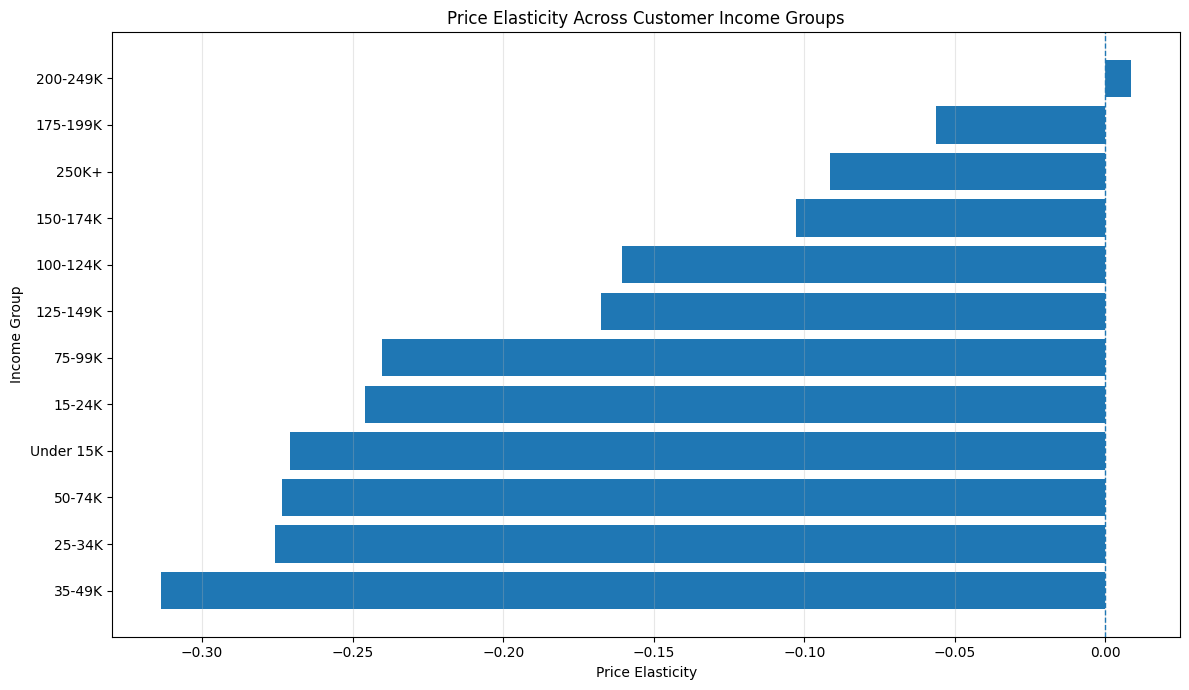

In [156]:
# Prepare data for visualization

plot_data = improved_income_results[
    improved_income_results["INCOME_DESC"] != "Unknown"
].sort_values("elasticity")

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["INCOME_DESC"],
    plot_data["elasticity"]
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Price Elasticity")
plt.ylabel("Income Group")

plt.title(
    "Price Elasticity Across Customer Income Groups"
)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [157]:
# Define price reduction scenarios
price_reductions = [0.05, 0.10, 0.15]

# Copy the income elasticity results
demand_scenarios = improved_income_results.copy()

# Calculate expected percentage change in quantity
for reduction in price_reductions:

    demand_scenarios[f"quantity_increase_{int(reduction*100)}pct"] = (
        ((1 - reduction) ** demand_scenarios["elasticity"]) - 1
    ) * 100

# Display results for known income groups
demand_scenarios[
    demand_scenarios["INCOME_DESC"] != "Unknown"
][
    [
        "INCOME_DESC",
        "elasticity",
        "quantity_increase_5pct",
        "quantity_increase_10pct",
        "quantity_increase_15pct"
    ]
]

,INCOME_DESC,elasticity,quantity_increase_5pct,quantity_increase_10pct,quantity_increase_15pct
8,35-49K,-0.313730,1.622242,3.360712,5.230926
6,25-34K,-0.275900,1.425244,2.949562,4.585947
9,50-74K,-0.273489,1.412699,2.923407,4.544966
11,Under 15K,-0.270824,1.398841,2.894519,4.499707
2,15-24K,-0.245868,1.269126,2.624326,4.076734
10,75-99K,-0.240216,1.239771,2.563232,3.981176
1,125-149K,-0.167677,0.863778,1.782347,2.762532
0,100-124K,-0.160435,0.826322,1.704724,2.641670
3,150-174K,-0.102651,0.527919,1.087404,1.682264
7,250K+,-0.091598,0.470943,0.969756,1.499781


In [158]:
# Calculate historical quantity sold by income group

baseline_quantity = (
    income_panel
    .groupby("INCOME_DESC")
    ["total_quantity"]
    .sum()
    .reset_index()
    .rename(columns={
        "total_quantity": "baseline_quantity"
    })
)

# Combine baseline quantities with pricing scenarios

volume_impact = demand_scenarios.merge(
    baseline_quantity,
    on="INCOME_DESC",
    how="left"
)

# Calculate additional units under each scenario

for reduction in [5, 10, 15]:

    column = f"quantity_increase_{reduction}pct"

    volume_column = f"additional_units_{reduction}pct"

    volume_impact[volume_column] = (
        volume_impact["baseline_quantity"]
        * volume_impact[column] / 100
    )

# Display results, retaining all income groups

volume_impact[
    [
        "INCOME_DESC",
        "baseline_quantity",
        "elasticity",
        "additional_units_5pct",
        "additional_units_10pct",
        "additional_units_15pct",
        "p_value"
    ]
]

,INCOME_DESC,baseline_quantity,elasticity,additional_units_5pct,additional_units_10pct,additional_units_15pct,p_value
0,Unknown,1511951,-0.464175,36430.128198,75781.062213,118469.810856,3.561918e-273
1,35-49K,358944,-0.313730,5822.938691,12063.073045,18776.093669,1.035999e-88
2,25-34K,170841,-0.275900,2434.901568,5039.060704,7834.678187,9.922792e-51
3,50-74K,437016,-0.273489,6173.721339,12775.758330,19862.227936,3.592979e-87
4,Under 15K,155065,-0.270824,2169.112498,4488.386408,6977.471017,1.323575e-41
5,15-24K,136017,-0.245868,1726.226836,3569.530135,5545.050866,7.967532e-32
6,75-99K,215573,-0.240216,2672.611256,5525.635112,8582.341094,1.681754e-45
7,125-149K,110293,-0.167677,952.686398,1965.803859,3046.878989,3.509931e-20
8,100-124K,75473,-0.160435,623.649842,1286.606249,1993.747451,5.361042e-17
9,150-174K,87555,-0.102651,462.219148,952.076880,1472.906183,1.875485e-09


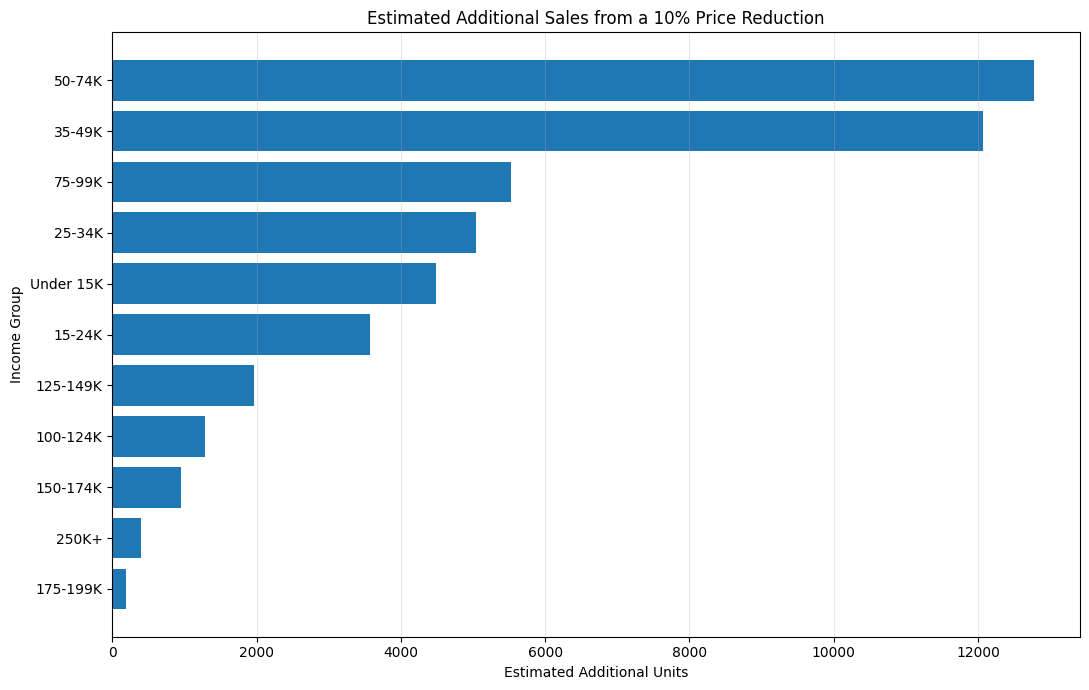

In [159]:
# Select statistically significant known income groups

scenario_plot = volume_impact[
    (volume_impact["INCOME_DESC"] != "Unknown") &
    (volume_impact["p_value"] < 0.05)
].copy()

# Sort by estimated additional units

scenario_plot = scenario_plot.sort_values(
    "additional_units_10pct"
)

# Create horizontal bar chart

plt.figure(figsize=(11, 7))

plt.barh(
    scenario_plot["INCOME_DESC"],
    scenario_plot["additional_units_10pct"]
)

plt.xlabel("Estimated Additional Units")
plt.ylabel("Income Group")

plt.title(
    "Estimated Additional Sales from a 10% Price Reduction"
)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [160]:
# Examine the product-level elasticity results

print("Number of products:", len(elasticity_results))

print("\nAvailable columns:")
print(elasticity_results.columns.tolist())

print("\nElasticity summary:")
print(elasticity_results["elasticity"].describe())

elasticity_results.head()

Number of products: 11484

Available columns:
['PRODUCT_ID', 'elasticity', 'p_value', 'std_error', 'lower_ci', 'upper_ci', 'r_squared', 'weeks_observed', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT', 'elasticity_category', 'adjusted_p_value']

Elasticity summary:
count    11484.000000
mean        -0.972330
std          1.511463
min        -16.661366
25%         -1.623361
50%         -0.863980
75%         -0.228435
max         13.591437
Name: elasticity, dtype: float64


,PRODUCT_ID,elasticity,p_value,std_error,lower_ci,upper_ci,r_squared,weeks_observed,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT,elasticity_category,adjusted_p_value
0,28897,-0.970061,0.037017,0.465129,-1.881698,-0.058425,0.153278,33,69,GROCERY,Private,EGGS,EGGS - X-LARGE,A D 1 DZ,Inelastic,0.098055
1,29629,-0.234378,0.731312,0.682559,-1.572169,1.103413,0.002983,30,69,GROCERY,Private,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHEAT/MULTIGRAIN BR,20 OZ,Inelastic,0.843042
2,42346,0.113377,0.931053,1.310408,-2.454976,2.681729,0.000522,32,69,GROCERY,Private,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,1 GA,Positive Elasticity,0.965786
3,43871,-0.302920,0.791344,1.144969,-2.547018,1.941179,0.004872,33,69,GROCERY,Private,EGGS,EGGS - LARGE,ALL 1 DZ,Inelastic,0.882824
4,108646,-0.180439,0.594445,0.338913,-0.844697,0.483818,0.013604,30,450,NUTRITION,National,REFRIGERATED,SOY/RICE MILK,64 OZ,Inelastic,0.745182


In [161]:
# Identify products with statistically reliable negative elasticity

reliable_products = elasticity_results[
    (elasticity_results["elasticity"] < 0) &
    (elasticity_results["adjusted_p_value"] < 0.05) &
    (elasticity_results["upper_ci"] < 0)
].copy()

# Summarize the results

print("Total estimated products:", len(elasticity_results))

print("Reliable negative-elasticity products:",
      len(reliable_products))

print("\nElasticity distribution:")

print(
    reliable_products["elasticity_category"].value_counts()
)

print("\nReliable product elasticity summary:")

print(
    reliable_products["elasticity"].describe()
)

Total estimated products: 11484
Reliable negative-elasticity products: 3522

Elasticity distribution:
elasticity_category
Elastic      3221
Inelastic     301
Name: count, dtype: int64

Reliable product elasticity summary:
count    3522.000000
mean       -2.157516
std         1.274738
min       -14.537818
25%        -2.600018
50%        -1.848694
75%        -1.347446
max        -0.256209
Name: elasticity, dtype: float64


In [162]:
# Identify statistically reliable inelastic products

inelastic_products = reliable_products[
    (reliable_products["elasticity"] > -1) &
    (reliable_products["elasticity"] < 0)
].copy()

# Rank products from least price-sensitive to most price-sensitive

inelastic_products = inelastic_products.sort_values(
    by="elasticity",
    ascending=False
)

# Display the top 20 candidates

top_price_increase_candidates = inelastic_products.head(20)

top_price_increase_candidates[
    [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC",
        "BRAND",
        "elasticity",
        "adjusted_p_value",
        "lower_ci",
        "upper_ci",
        "weeks_observed"
    ]
]

,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,elasticity,adjusted_p_value,lower_ci,upper_ci,weeks_observed
11190,12810369,PORK,ENHANCED,National,-0.256209,0.034871,-0.451726,-0.060692,37
547,837969,DELI MEATS,MEAT: SAUS DRY BULK,National,-0.308465,0.049325,-0.558855,-0.058075,73
9367,6533182,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.402658,0.044637,-0.723279,-0.082037,31
10471,9655175,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.446084,0.035102,-0.786887,-0.105281,32
9928,8064946,CHEESES,CHEESE:CHEESEBALLS/SPREADS,National,-0.471565,0.040484,-0.840460,-0.102671,33
2631,912503,SQUASH,HARD SQUASH,National,-0.484911,0.001598,-0.744991,-0.224831,57
6587,1059473,PORK,RIBS,National,-0.523235,0.008778,-0.853563,-0.192907,61
3641,948793,SNACK NUTS,VAC PAC NUTS(CANS),National,-0.538398,0.000719,-0.810163,-0.266633,30
944,851952,BREAD,BREAD:PITA/POCKET BREADS,National,-0.543495,0.041583,-0.970733,-0.116257,48
2131,895268,VEGETABLES SALAD,SPINACH BULK,National,-0.546873,0.043499,-0.980288,-0.113457,90


In [163]:
# Summarise reliable inelastic products by commodity category

category_opportunities = (
    inelastic_products
    .groupby("COMMODITY_DESC")
    .agg(
        number_of_products=("PRODUCT_ID", "count"),
        average_elasticity=("elasticity", "mean"),
        least_sensitive_elasticity=("elasticity", "max"),
        most_sensitive_elasticity=("elasticity", "min")
    )
    .reset_index()
    .sort_values(
        by="number_of_products",
        ascending=False
    )
)

category_opportunities.head(20)

,COMMODITY_DESC,number_of_products,average_elasticity,least_sensitive_elasticity,most_sensitive_elasticity
60,ICE CREAM/MILK/SHERBTS,26,-0.761106,-0.402658,-0.988941
52,FRZN MEAT/MEAT DINNERS,13,-0.886633,-0.736312,-0.999502
18,CHEESE,9,-0.834594,-0.728063,-0.940999
28,CONVENIENT BRKFST/WHLSM SNACKS,9,-0.880659,-0.683398,-0.990789
71,POPCORN,9,-0.730528,-0.597202,-0.915579
15,CANDY - CHECKLANE,8,-0.914823,-0.813692,-0.987015
32,CRACKERS/MISC BKD FD,7,-0.768077,-0.662309,-0.947787
40,DRY MIX DESSERTS,7,-0.756192,-0.627588,-0.965669
6,BAKED BREAD/BUNS/ROLLS,7,-0.831461,-0.746166,-0.939324
77,SALD DRSNG/SNDWCH SPRD,7,-0.798164,-0.717640,-0.850956


In [164]:
# Calculate historical sales performance for each product

product_performance = (
    grocery_df
    .groupby("PRODUCT_ID")
    .agg(
        baseline_quantity=("QUANTITY", "sum"),
        baseline_sales=("SALES_VALUE", "sum"),
        weeks_sold=("WEEK_NO", "nunique")
    )
    .reset_index()
)

# Attach sales performance to reliable inelastic products

inelastic_performance = inelastic_products.merge(
    product_performance,
    on="PRODUCT_ID",
    how="left"
)

# Summarise opportunities by product category

category_commercial_opportunities = (
    inelastic_performance
    .groupby("COMMODITY_DESC")
    .apply(
        lambda group: pd.Series({
            "number_of_products": group["PRODUCT_ID"].nunique(),
            "total_quantity": group["baseline_quantity"].sum(),
            "total_sales": group["baseline_sales"].sum(),
            "average_elasticity": group["elasticity"].mean(),
            "sales_weighted_elasticity": np.average(
                group["elasticity"],
                weights=group["baseline_sales"]
            )
        }),
        include_groups=False
    )
    .reset_index()
    .sort_values(
        by="total_sales",
        ascending=False
    )
)

category_commercial_opportunities.head(20)

,COMMODITY_DESC,number_of_products,total_quantity,total_sales,average_elasticity,sales_weighted_elasticity
90,TOMATOES,1.0,4095.0,10671.96,-0.739287,-0.739287
60,ICE CREAM/MILK/SHERBTS,26.0,2159.0,6650.26,-0.761106,-0.800421
6,BAKED BREAD/BUNS/ROLLS,7.0,1998.0,4529.99,-0.831461,-0.827744
74,REFRGRATD JUICES/DRNKS,2.0,1487.0,4073.41,-0.907258,-0.894881
21,CIGARETTES,1.0,116.0,3183.99,-0.769760,-0.769760
18,CHEESE,9.0,1591.0,3116.65,-0.834594,-0.847392
52,FRZN MEAT/MEAT DINNERS,13.0,1301.0,2965.53,-0.886633,-0.895638
10,BEEF,1.0,1449.0,2633.49,-0.930551,-0.930551
67,NEWSPAPER,1.0,1853.0,2536.76,-0.989639,-0.989639
28,CONVENIENT BRKFST/WHLSM SNACKS,9.0,860.0,1840.36,-0.880659,-0.872339


In [165]:
# Simulate price increases for each inelastic product

price_increases = [0.05, 0.10]

price_increase_scenarios = inelastic_performance.copy()

for increase in price_increases:

    # Expected quantity change
    quantity_change = (
        ((1 + increase) ** price_increase_scenarios["elasticity"]) - 1
    )

    # Expected revenue change
    revenue_change = (
        (1 + increase) * (1 + quantity_change) - 1
    )

    price_increase_scenarios[
        f"quantity_change_{int(increase * 100)}pct"
    ] = quantity_change * 100

    price_increase_scenarios[
        f"revenue_change_{int(increase * 100)}pct"
    ] = revenue_change * 100

    price_increase_scenarios[
        f"additional_revenue_{int(increase * 100)}pct"
    ] = (
        price_increase_scenarios["baseline_sales"] * revenue_change
    )

# Display the top 20 products by potential additional revenue
# under a 5% price increase

price_increase_scenarios = price_increase_scenarios.sort_values(
    by="additional_revenue_5pct",
    ascending=False
)

price_increase_scenarios[
    [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "elasticity",
        "baseline_sales",
        "quantity_change_5pct",
        "revenue_change_5pct",
        "additional_revenue_5pct",
        "revenue_change_10pct",
        "additional_revenue_10pct"
    ]
].head(20)

,PRODUCT_ID,COMMODITY_DESC,elasticity,baseline_sales,quantity_change_5pct,revenue_change_5pct,additional_revenue_5pct,revenue_change_10pct,additional_revenue_10pct
81,854852,TOMATOES,-0.739287,10671.96,-3.542718,1.280146,136.616704,2.515988,268.505199
100,1008288,CIGARETTES,-0.769760,3183.99,-3.686022,1.129677,35.968811,2.218675,70.642383
193,1122358,REFRGRATD JUICES/DRNKS,-0.892765,3775.99,-4.262311,0.524573,19.807835,1.027301,38.790794
0,12810369,PORK,-0.256209,426.45,-1.242267,3.695620,15.759971,7.346407,31.328751
143,1082212,BAKED BREAD/BUNS/ROLLS,-0.833386,1819.50,-3.984548,0.816224,14.851201,1.600674,29.124268
6,1059473,PORK,-0.523235,625.24,-2.520563,2.353409,14.714455,4.648878,29.066643
1,837969,DELI MEATS,-0.308465,326.42,-1.493738,3.431576,11.201349,6.813092,22.239295
9,895268,VEGETABLES SALAD,-0.546873,500.41,-2.632918,2.235436,11.186344,4.413382,22.085003
38,874149,VEGETABLES SALAD,-0.670394,667.08,-3.217948,1.621154,10.814397,3.191348,21.288843
68,906262,WATER - CARBONATED/FLVRD DRINK,-0.727378,762.58,-3.486657,1.339010,10.211026,2.632412,20.074251


In [166]:
# Identify products whose entire confidence interval
# indicates inelastic demand

robust_inelastic_products = inelastic_performance[
    (inelastic_performance["lower_ci"] > -1) &
    (inelastic_performance["upper_ci"] < 0)
].copy()

# Rank by estimated price sensitivity

robust_inelastic_products = robust_inelastic_products.sort_values(
    by="elasticity",
    ascending=False
)

print(
    "Products with confidence intervals entirely between -1 and 0:",
    len(robust_inelastic_products)
)

robust_inelastic_products[
    [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "elasticity",
        "lower_ci",
        "upper_ci",
        "baseline_sales",
        "adjusted_p_value"
    ]
].head(20)

Products with confidence intervals entirely between -1 and 0: 15


,PRODUCT_ID,COMMODITY_DESC,elasticity,lower_ci,upper_ci,baseline_sales,adjusted_p_value
0,12810369,PORK,-0.256209,-0.451726,-0.060692,426.45,0.034871
1,837969,DELI MEATS,-0.308465,-0.558855,-0.058075,326.42,0.049325
2,6533182,ICE CREAM/MILK/SHERBTS,-0.402658,-0.723279,-0.082037,130.37,0.044637
3,9655175,ICE CREAM/MILK/SHERBTS,-0.446084,-0.786887,-0.105281,139.37,0.035102
4,8064946,CHEESES,-0.471565,-0.840460,-0.102671,152.29,0.040484
5,912503,SQUASH,-0.484911,-0.744991,-0.224831,242.37,0.001598
6,1059473,PORK,-0.523235,-0.853563,-0.192907,625.24,0.008778
7,948793,SNACK NUTS,-0.538398,-0.810163,-0.266633,139.12,0.000719
8,851952,BREAD,-0.543495,-0.970733,-0.116257,115.69,0.041583
9,895268,VEGETABLES SALAD,-0.546873,-0.980288,-0.113457,500.41,0.043499


In [167]:
# Create scenarios using only robust inelastic products

robust_price_scenarios = robust_inelastic_products.copy()

for increase in [0.05, 0.10, 0.15]:

    quantity_change = (
        (1 + increase) ** robust_price_scenarios["elasticity"] - 1
    )

    revenue_change = (
        (1 + increase) * (1 + quantity_change) - 1
    )

    robust_price_scenarios[
        f"quantity_change_{int(increase * 100)}pct"
    ] = quantity_change * 100

    robust_price_scenarios[
        f"revenue_change_{int(increase * 100)}pct"
    ] = revenue_change * 100

    robust_price_scenarios[
        f"additional_revenue_{int(increase * 100)}pct"
    ] = (
        robust_price_scenarios["baseline_sales"] * revenue_change
    )

print("Total robust inelastic products:", len(robust_price_scenarios))

print(
    "\nPotential additional revenue from a 5% price increase:",
    round(
        robust_price_scenarios["additional_revenue_5pct"].sum(),
        2
    )
)

print(
    "Potential additional revenue from a 10% price increase:",
    round(
        robust_price_scenarios["additional_revenue_10pct"].sum(),
        2
    )
)

print(
    "Potential additional revenue from a 15% price increase:",
    round(
        robust_price_scenarios["additional_revenue_15pct"].sum(),
        2
    )
)


Total robust inelastic products: 15

Potential additional revenue from a 5% price increase: 89.28
Potential additional revenue from a 10% price increase: 176.64
Potential additional revenue from a 15% price increase: 262.23


In [168]:
# Create the final product pricing opportunity table

final_product_opportunities = robust_price_scenarios[
    [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC",
        "BRAND",
        "elasticity",
        "lower_ci",
        "upper_ci",
        "adjusted_p_value",
        "baseline_sales",
        "baseline_quantity",
        "additional_revenue_5pct",
        "additional_revenue_10pct",
        "additional_revenue_15pct"
    ]
].copy()

# Rank products by potential additional revenue at 10%

final_product_opportunities = (
    final_product_opportunities
    .sort_values(
        by="additional_revenue_10pct",
        ascending=False
    )
    .reset_index(drop=True)
)

final_product_opportunities

,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,elasticity,lower_ci,upper_ci,adjusted_p_value,baseline_sales,baseline_quantity,additional_revenue_5pct,additional_revenue_10pct,additional_revenue_15pct
0,12810369,PORK,ENHANCED,National,-0.256209,-0.451726,-0.060692,0.034871,426.45,53,15.759971,31.328751,46.717201
1,1059473,PORK,RIBS,National,-0.523235,-0.853563,-0.192907,0.008778,625.24,178,14.714455,29.066643,43.081370
2,837969,DELI MEATS,MEAT: SAUS DRY BULK,National,-0.308465,-0.558855,-0.058075,0.049325,326.42,107,11.201349,22.239295,33.123496
3,895268,VEGETABLES SALAD,SPINACH BULK,National,-0.546873,-0.980288,-0.113457,0.043499,500.41,417,11.186344,22.085003,32.715967
4,912503,SQUASH,HARD SQUASH,National,-0.484911,-0.744991,-0.224831,0.001598,242.37,112,6.168249,12.195633,18.091563
5,844175,PICKLE/RELISH/PKLD VEG,PICKLES,Private,-0.588685,-0.998192,-0.179178,0.019065,213.32,121,4.324178,8.528764,12.622285
6,8064946,CHEESES,CHEESE:CHEESEBALLS/SPREADS,National,-0.471565,-0.840460,-0.102671,0.040484,152.29,49,3.977459,7.866556,11.673144
7,6533182,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.402658,-0.723279,-0.082037,0.044637,130.37,41,3.855467,7.637681,11.351271
8,9655175,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.446084,-0.786887,-0.105281,0.035102,139.37,41,3.817924,7.555566,11.218154
9,948793,SNACK NUTS,VAC PAC NUTS(CANS),National,-0.538398,-0.810163,-0.266633,0.000719,139.12,45,3.168762,6.257278,9.271095


In [169]:
# Identify our 15 robust products

priority_product_ids = final_product_opportunities["PRODUCT_ID"].unique()

# Retrieve all available income-group observations
# for these products

priority_income_panel = income_panel[
    income_panel["PRODUCT_ID"].isin(priority_product_ids)
].copy()

# Check the resulting dataset

print("Panel dimensions:", priority_income_panel.shape)

print("Products:", priority_income_panel["PRODUCT_ID"].nunique())

print("Income groups:", priority_income_panel["INCOME_DESC"].nunique())

print("Weeks:", priority_income_panel["WEEK_NO"].nunique())

print(
    "Product-income combinations:",
    priority_income_panel[
        ["PRODUCT_ID", "INCOME_DESC"]
    ].drop_duplicates().shape[0]
)


Panel dimensions: (1074, 32)
Products: 15
Income groups: 13
Weeks: 99
Product-income combinations: 137


In [170]:
# Check the required variables

required_columns = [
    "PRODUCT_ID",
    "INCOME_DESC",
    "WEEK_NO",
    "total_quantity",
    "average_price",
    "promotion_share"
]

print(
    priority_income_panel[required_columns].isna().sum()
)

print("\nNumber of observations per product-income group:")

print(
    priority_income_panel
    .groupby(["PRODUCT_ID", "INCOME_DESC"])
    .size()
    .describe()
)

PRODUCT_ID         0
INCOME_DESC        0
WEEK_NO            0
total_quantity     0
average_price      0
promotion_share    0
dtype: int64

Number of observations per product-income group:
count    137.000000
mean       7.839416
std       10.771172
min        1.000000
25%        2.000000
50%        4.000000
75%        9.000000
max       79.000000
dtype: float64


In [171]:
# Create product-income identifiers

priority_income_panel["product_income_code"] = pd.factorize(
    pd.MultiIndex.from_frame(
        priority_income_panel[
            ["PRODUCT_ID", "INCOME_DESC"]
        ]
    )
)[0]

# Create week identifiers

priority_income_panel["week_code"] = pd.factorize(
    priority_income_panel["WEEK_NO"]
)[0]

# Check the identifiers

print(
    "Product-income groups:",
    priority_income_panel["product_income_code"].nunique()
)

print(
    "Weeks:",
    priority_income_panel["week_code"].nunique()
)

print(
    "Observations:",
    len(priority_income_panel)
)

Product-income groups: 137
Weeks: 99
Observations: 1074


In [172]:
# Create income-group dummy variables

priority_income_dummies = pd.get_dummies(
    priority_income_panel["INCOME_DESC"],
    dtype=float
)

# Create price interactions for each income group

priority_price_interactions = priority_income_dummies.mul(
    priority_income_panel["log_price"],
    axis=0
)

# Prepare the variables for fixed-effects transformation

priority_raw_variables = np.column_stack([
    priority_income_panel["log_quantity"].to_numpy(),
    priority_income_panel["promotion_share"].to_numpy(),
    priority_price_interactions.to_numpy()
])

# Create fixed-effects structure

priority_fixed_effects = priority_income_panel[
    ["product_income_code", "week_code"]
].to_numpy()

priority_algorithm = pyhdfe.create(
    priority_fixed_effects,
    drop_singletons=False
)

# Remove fixed effects

priority_transformed = priority_algorithm.residualize(
    priority_raw_variables
)

# Separate dependent and independent variables

y_priority = priority_transformed[:, 0]

X_priority = priority_transformed[:, 1:]

# Estimate regression with product-clustered standard errors

priority_income_model = sm.OLS(
    y_priority,
    X_priority
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": priority_income_panel["product_id_code"].to_numpy()
    }
)

print(priority_income_model.summary())

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.051
Model:                            OLS   Adj. R-squared (uncentered):              0.038
Method:                 Least Squares   F-statistic:                              1905.
Date:                Fri, 20 Nov 2026   Prob (F-statistic):                    1.87e-20
Time:                        06:00:47   Log-Likelihood:                         -236.48
No. Observations:                1074   AIC:                                      501.0
Df Residuals:                    1060   BIC:                                      570.7
Df Model:                          14                                                  
Covariance Type:              cluster                                                  
                 coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------

In [173]:
# Build income-specific elasticity results

priority_income_results = pd.DataFrame({
    "INCOME_DESC": priority_income_dummies.columns,
    "elasticity": priority_income_model.params[1:],
    "std_error": priority_income_model.bse[1:],
    "p_value": priority_income_model.pvalues[1:],
    "lower_ci": priority_income_model.conf_int()[1:, 0],
    "upper_ci": priority_income_model.conf_int()[1:, 1]
})

# Classify the estimated price responses

def classify_priority_elasticity(row):

    if row["p_value"] >= 0.05:
        return "No clear price response"

    elif row["elasticity"] >= 0:
        return "Positive estimated response"

    elif abs(row["elasticity"]) > 1:
        return "Elastic"

    else:
        return "Inelastic"


priority_income_results["classification"] = (
    priority_income_results.apply(
        classify_priority_elasticity,
        axis=1
    )
)

# Sort by estimated price sensitivity

priority_income_results = (
    priority_income_results
    .sort_values("elasticity")
    .reset_index(drop=True)
)

priority_income_results

,INCOME_DESC,elasticity,std_error,p_value,lower_ci,upper_ci,classification
0,125-149K,-0.433060,0.119148,0.000278,-0.666585,-0.199535,Inelastic
1,15-24K,-0.369182,0.181018,0.041403,-0.723971,-0.014393,Inelastic
2,100-124K,-0.357992,0.086205,0.000033,-0.526950,-0.189033,Inelastic
3,35-49K,-0.124083,0.062283,0.046345,-0.246156,-0.002010,Inelastic
4,Under 15K,-0.106967,0.108097,0.322396,-0.318834,0.104900,No clear price response
5,50-74K,-0.074757,0.051277,0.144870,-0.175259,0.025745,No clear price response
6,Unknown,-0.041628,0.086491,0.630303,-0.211147,0.127891,No clear price response
7,175-199K,-0.006024,0.144381,0.966720,-0.289006,0.276958,No clear price response
8,250K+,0.034503,0.083818,0.680602,-0.129777,0.198784,No clear price response
9,25-34K,0.044851,0.103638,0.665183,-0.158276,0.247979,No clear price response


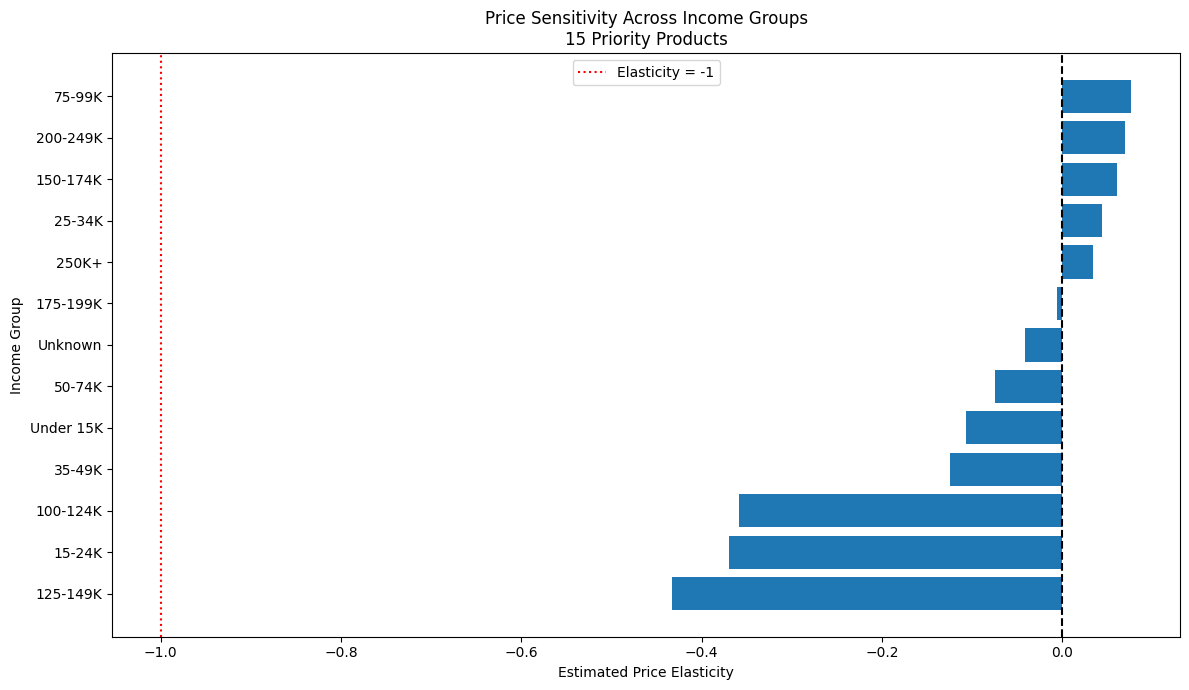

In [174]:
# Visualize product-specific income elasticities

plt.figure(figsize=(12, 7))

plot_data = priority_income_results.sort_values(
    "elasticity"
)

plt.barh(
    plot_data["INCOME_DESC"],
    plot_data["elasticity"]
)

plt.axvline(
    x=0,
    linestyle="--",
    color="black"
)

plt.axvline(
    x=-1,
    linestyle=":",
    color="red",
    label="Elasticity = -1"
)

plt.xlabel("Estimated Price Elasticity")
plt.ylabel("Income Group")

plt.title(
    "Price Sensitivity Across Income Groups\n"
    "15 Priority Products"
)

plt.legend()
plt.tight_layout()
plt.show()

In [175]:
# Compare the two income elasticity models

income_model_comparison = improved_income_results[
    ["INCOME_DESC", "elasticity"]
].merge(
    priority_income_results[
        ["INCOME_DESC", "elasticity", "p_value", "classification"]
    ],
    on="INCOME_DESC",
    suffixes=("_broad", "_priority")
)

# Calculate the difference between the estimates

income_model_comparison["elasticity_difference"] = (
    income_model_comparison["elasticity_priority"]
    - income_model_comparison["elasticity_broad"]
)

# Sort by broad-model elasticity

income_model_comparison = (
    income_model_comparison
    .sort_values("elasticity_broad")
    .reset_index(drop=True)
)

income_model_comparison

,INCOME_DESC,elasticity_broad,elasticity_priority,p_value,classification,elasticity_difference
0,Unknown,-0.464175,-0.041628,0.630303,No clear price response,0.422547
1,35-49K,-0.313730,-0.124083,0.046345,Inelastic,0.189647
2,25-34K,-0.275900,0.044851,0.665183,No clear price response,0.320752
3,50-74K,-0.273489,-0.074757,0.144870,No clear price response,0.198732
4,Under 15K,-0.270824,-0.106967,0.322396,No clear price response,0.163857
5,15-24K,-0.245868,-0.369182,0.041403,Inelastic,-0.123314
6,75-99K,-0.240216,0.077014,0.235893,No clear price response,0.317231
7,125-149K,-0.167677,-0.433060,0.000278,Inelastic,-0.265383
8,100-124K,-0.160435,-0.357992,0.000033,Inelastic,-0.197556
9,150-174K,-0.102651,0.060941,0.115425,No clear price response,0.163592


In [176]:
# Calculate correlation between the two elasticity estimates

elasticity_correlation = (
    income_model_comparison[
        [
            "elasticity_broad",
            "elasticity_priority"
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Correlation between broad and priority-product elasticities:",
    round(elasticity_correlation, 4)
)

Correlation between broad and priority-product elasticities: 0.1427


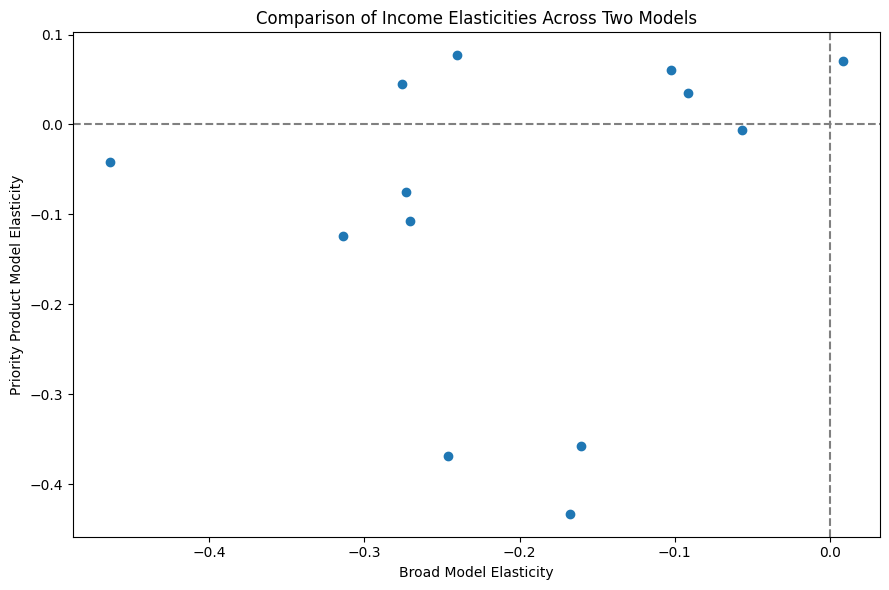

In [177]:
plt.figure(figsize=(9, 6))

plt.scatter(
    income_model_comparison["elasticity_broad"],
    income_model_comparison["elasticity_priority"]
)

plt.axhline(y=0, linestyle="--", color="gray")
plt.axvline(x=0, linestyle="--", color="gray")

plt.xlabel("Broad Model Elasticity")
plt.ylabel("Priority Product Model Elasticity")

plt.title(
    "Comparison of Income Elasticities Across Two Models"
)

plt.tight_layout()
plt.show()

In [178]:
# Create the final customer segment strategy table

final_segment_strategy = improved_income_results[
    [
        "INCOME_DESC",
        "elasticity",
        "p_value",
        "lower_ci",
        "upper_ci"
    ]
].copy()

# Assign practical sensitivity categories
# These are descriptive business categories, not statistical tests.

def assign_segment_strategy(row):

    if row["INCOME_DESC"] == "Unknown":
        return "Separate analysis - unknown income"

    elif row["p_value"] >= 0.05:
        return "Insufficient evidence of price response"

    elif row["elasticity"] <= -0.25:
        return "Relatively more price-sensitive"

    elif row["elasticity"] <= -0.15:
        return "Moderately price-sensitive"

    else:
        return "Relatively less price-sensitive"


final_segment_strategy["customer_strategy"] = (
    final_segment_strategy.apply(
        assign_segment_strategy,
        axis=1
    )
)

# Add priority-product model estimates

final_segment_strategy = final_segment_strategy.merge(
    priority_income_results[
        ["INCOME_DESC", "elasticity", "p_value"]
    ],
    on="INCOME_DESC",
    how="left",
    suffixes=("_broad", "_priority")
)

# Display the final table

final_segment_strategy = final_segment_strategy.sort_values(
    "elasticity_broad"
).reset_index(drop=True)

final_segment_strategy

,INCOME_DESC,elasticity_broad,p_value_broad,lower_ci,upper_ci,customer_strategy,elasticity_priority,p_value_priority
0,Unknown,-0.464175,3.561918e-273,-0.489937,-0.438413,Separate analysis - unknown income,-0.041628,0.630303
1,35-49K,-0.313730,1.035999e-88,-0.344523,-0.282936,Relatively more price-sensitive,-0.124083,0.046345
2,25-34K,-0.275900,9.922792e-51,-0.311999,-0.239802,Relatively more price-sensitive,0.044851,0.665183
3,50-74K,-0.273489,3.592979e-87,-0.300574,-0.246404,Relatively more price-sensitive,-0.074757,0.144870
4,Under 15K,-0.270824,1.323575e-41,-0.310108,-0.231541,Relatively more price-sensitive,-0.106967,0.322396
5,15-24K,-0.245868,7.967532e-32,-0.286916,-0.204821,Moderately price-sensitive,-0.369182,0.041403
6,75-99K,-0.240216,1.681754e-45,-0.273472,-0.206960,Moderately price-sensitive,0.077014,0.235893
7,125-149K,-0.167677,3.509931e-20,-0.203390,-0.131963,Moderately price-sensitive,-0.433060,0.000278
8,100-124K,-0.160435,5.361042e-17,-0.197966,-0.122905,Moderately price-sensitive,-0.357992,0.000033
9,150-174K,-0.102651,1.875485e-09,-0.136137,-0.069165,Relatively less price-sensitive,0.060941,0.115425


In [179]:
# Create practical pricing recommendations

segment_recommendations = {
    "Relatively more price-sensitive":
        "Prioritize targeted discounts, competitive pricing and promotions.",

    "Moderately price-sensitive":
        "Use selective promotions and moderate price adjustments.",

    "Relatively less price-sensitive":
        "Protect margins and cautiously test small price increases.",

    "Insufficient evidence of price response":
        "Gather more evidence before making segment-specific pricing decisions.",

    "Separate analysis - unknown income":
        "Analyse separately and avoid assuming income-based behaviour."
}

final_segment_strategy["business_recommendation"] = (
    final_segment_strategy["customer_strategy"].map(
        segment_recommendations
    )
)

# Display final recommendations

final_customer_recommendations = final_segment_strategy[
    [
        "INCOME_DESC",
        "elasticity_broad",
        "customer_strategy",
        "business_recommendation"
    ]
].copy()

final_customer_recommendations

,INCOME_DESC,elasticity_broad,customer_strategy,business_recommendation
0,Unknown,-0.464175,Separate analysis - unknown income,Analyse separately and avoid assuming income-b...
1,35-49K,-0.313730,Relatively more price-sensitive,"Prioritize targeted discounts, competitive pri..."
2,25-34K,-0.275900,Relatively more price-sensitive,"Prioritize targeted discounts, competitive pri..."
3,50-74K,-0.273489,Relatively more price-sensitive,"Prioritize targeted discounts, competitive pri..."
4,Under 15K,-0.270824,Relatively more price-sensitive,"Prioritize targeted discounts, competitive pri..."
5,15-24K,-0.245868,Moderately price-sensitive,Use selective promotions and moderate price ad...
6,75-99K,-0.240216,Moderately price-sensitive,Use selective promotions and moderate price ad...
7,125-149K,-0.167677,Moderately price-sensitive,Use selective promotions and moderate price ad...
8,100-124K,-0.160435,Moderately price-sensitive,Use selective promotions and moderate price ad...
9,150-174K,-0.102651,Relatively less price-sensitive,Protect margins and cautiously test small pric...


In [180]:
# Build the final product pricing recommendation matrix

final_product_strategy = robust_price_scenarios[
    [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC",
        "elasticity",
        "lower_ci",
        "upper_ci",
        "baseline_sales",
        "baseline_quantity",
        "quantity_change_5pct",
        "revenue_change_5pct",
        "additional_revenue_5pct",
        "quantity_change_10pct",
        "revenue_change_10pct",
        "additional_revenue_10pct"
    ]
].copy()

# Assign a conservative pricing recommendation

final_product_strategy["pricing_recommendation"] = (
    "Consider a controlled 5% price-increase test"
)

# Rank products by potential additional revenue

final_product_strategy = (
    final_product_strategy
    .sort_values(
        "additional_revenue_5pct",
        ascending=False
    )
    .reset_index(drop=True)
)

final_product_strategy

,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,elasticity,lower_ci,upper_ci,baseline_sales,baseline_quantity,quantity_change_5pct,revenue_change_5pct,additional_revenue_5pct,quantity_change_10pct,revenue_change_10pct,additional_revenue_10pct,pricing_recommendation
0,12810369,PORK,ENHANCED,-0.256209,-0.451726,-0.060692,426.45,53,-1.242267,3.695620,15.759971,-2.412358,7.346407,31.328751,Consider a controlled 5% price-increase test
1,1059473,PORK,RIBS,-0.523235,-0.853563,-0.192907,625.24,178,-2.520563,2.353409,14.714455,-4.864657,4.648878,29.066643,Consider a controlled 5% price-increase test
2,837969,DELI MEATS,MEAT: SAUS DRY BULK,-0.308465,-0.558855,-0.058075,326.42,107,-1.493738,3.431576,11.201349,-2.897189,6.813092,22.239295,Consider a controlled 5% price-increase test
3,895268,VEGETABLES SALAD,SPINACH BULK,-0.546873,-0.980288,-0.113457,500.41,417,-2.632918,2.235436,11.186344,-5.078744,4.413382,22.085003,Consider a controlled 5% price-increase test
4,912503,SQUASH,HARD SQUASH,-0.484911,-0.744991,-0.224831,242.37,112,-2.338122,2.544972,6.168249,-4.516523,5.031825,12.195633,Consider a controlled 5% price-increase test
5,844175,PICKLE/RELISH/PKLD VEG,PICKLES,-0.588685,-0.998192,-0.179178,213.32,121,-2.831347,2.027085,4.324178,-5.456265,3.998108,8.528764,Consider a controlled 5% price-increase test
6,8064946,CHEESES,CHEESE:CHEESEBALLS/SPREADS,-0.471565,-0.840460,-0.102671,152.29,49,-2.274508,2.611766,3.977459,-4.394990,5.165511,7.866556,Consider a controlled 5% price-increase test
7,6533182,ICE CREAM/MILK/SHERBTS,PREMIUM,-0.402658,-0.723279,-0.082037,130.37,41,-1.945403,2.957327,3.855467,-3.765032,5.858465,7.637681,Consider a controlled 5% price-increase test
8,9655175,ICE CREAM/MILK/SHERBTS,PREMIUM,-0.446084,-0.786887,-0.105281,139.37,41,-2.152937,2.739416,3.817924,-4.162520,5.421228,7.555566,Consider a controlled 5% price-increase test
9,948793,SNACK NUTS,VAC PAC NUTS(CANS),-0.538398,-0.810163,-0.266633,139.12,45,-2.592649,2.277718,3.168762,-5.002040,4.497756,6.257278,Consider a controlled 5% price-increase test


In [181]:
# Final model evaluation summary

model_evaluation = pd.DataFrame({
    "Evaluation Area": [
        "Product-level elasticity",
        "Reliable negative-elasticity products",
        "Robust inelastic product opportunities",
        "Known income segments",
        "Income segments with significant price responses",
        "Income segments with insufficient evidence",
        "Product-income exploratory analysis",
        "Potential revenue from 5% price increases"
    ],

    "Result": [
        "11,484 products estimated",
        "3,522 products",
        "15 products",
        "12 segments",
        "11 segments",
        "1 segment",
        "1,074 observations across 15 products",
        "89.28 additional revenue units"
    ],

    "Interpretation": [
        "Product-level price responses were estimated.",
        "Negative estimates passed the statistical reliability criteria.",
        "Confidence intervals were entirely between -1 and 0.",
        "Income groups were compared using the pooled fixed-effects model.",
        "Their estimated price responses were statistically significant.",
        "The 200-249K group had no clear price response.",
        "Results are exploratory because the sample is limited.",
        "This is a historical-period revenue simulation, not a forecast."
    ]
})

model_evaluation

,Evaluation Area,Result,Interpretation
0,Product-level elasticity,"11,484 products estimated",Product-level price responses were estimated.
1,Reliable negative-elasticity products,"3,522 products",Negative estimates passed the statistical reli...
2,Robust inelastic product opportunities,15 products,Confidence intervals were entirely between -1 ...
3,Known income segments,12 segments,Income groups were compared using the pooled f...
4,Income segments with significant price responses,11 segments,Their estimated price responses were statistic...
5,Income segments with insufficient evidence,1 segment,The 200-249K group had no clear price response.
6,Product-income exploratory analysis,"1,074 observations across 15 products",Results are exploratory because the sample is ...
7,Potential revenue from 5% price increases,89.28 additional revenue units,This is a historical-period revenue simulation...


In [182]:
# Model limitations

model_limitations = pd.DataFrame({
    "Limitation": [
        "Observational data",
        "Promotional effects",
        "Missing zero-sales observations",
        "Demographic coverage",
        "Product-income sample size",
        "Revenue simulation",
        "Profitability not measured"
    ],

    "Explanation": [
        "The analysis uses historical transactions and cannot establish causal effects of price changes.",

        "Promotions may be associated with other business decisions, making their independent effects difficult to isolate.",

        "The log-log models use observed positive sales and do not capture weeks when a product had zero sales.",

        "Household demographic information is available for only a subset of households.",

        "The product-income analysis has limited observations and only 15 product clusters, so its estimates are exploratory.",

        "Price scenarios assume historical elasticities remain constant after price changes.",

        "Additional revenue does not necessarily mean additional profit because product costs and margins are unavailable."
    ]
})

model_limitations

,Limitation,Explanation
0,Observational data,The analysis uses historical transactions and ...
1,Promotional effects,Promotions may be associated with other busine...
2,Missing zero-sales observations,The log-log models use observed positive sales...
3,Demographic coverage,Household demographic information is available...
4,Product-income sample size,The product-income analysis has limited observ...
5,Revenue simulation,Price scenarios assume historical elasticities...
6,Profitability not measured,Additional revenue does not necessarily mean a...


In [183]:
# Final project conclusions

project_conclusions = pd.DataFrame({
    "Project Objective": [
        "Identify price-sensitive customer segments",

        "Identify customers who continue buying despite price increases",

        "Estimate additional demand from price reductions",

        "Identify products that may sustain price increases",

        "Develop differentiated pricing strategies"
    ],

    "Key Finding": [
        "The 35-49K income group had the strongest estimated price sensitivity among known income groups, with an elasticity of -0.314.",

        "All statistically significant known income groups had inelastic estimates, meaning their estimated quantity responses were proportionally smaller than price changes.",

        "A 10% price reduction was estimated to increase demand by approximately 0.6% to 3.4% across the known income groups with significant price responses.",

        "15 products had statistically reliable elasticity estimates with confidence intervals entirely between -1 and 0.",

        "More price-sensitive groups should receive targeted promotions, while less price-sensitive groups may be suitable for cautious price testing."
    ],

    "Business Implication": [
        "Use income segmentation to guide promotional targeting.",

        "Consider protecting margins in segments with relatively low price sensitivity.",

        "Use selective discounts where the expected additional volume justifies the cost.",

        "Test small price increases on shortlisted products while monitoring actual sales and profit.",

        "Avoid applying one pricing strategy across all customer segments."
    ]
})

project_conclusions

,Project Objective,Key Finding,Business Implication
0,Identify price-sensitive customer segments,The 35-49K income group had the strongest esti...,Use income segmentation to guide promotional t...
1,Identify customers who continue buying despite...,All statistically significant known income gro...,Consider protecting margins in segments with r...
2,Estimate additional demand from price reductions,A 10% price reduction was estimated to increas...,Use selective discounts where the expected add...
3,Identify products that may sustain price incre...,15 products had statistically reliable elastic...,Test small price increases on shortlisted prod...
4,Develop differentiated pricing strategies,More price-sensitive groups should receive tar...,Avoid applying one pricing strategy across all...


In [184]:
# Prepare product-week data for temporal validation

validation_panel = (
    grocery_df
    .groupby(["PRODUCT_ID", "WEEK_NO"])
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum")
    )
    .reset_index()
)

# Calculate weekly product metrics

validation_panel["average_price"] = (
    validation_panel["total_sales"] /
    validation_panel["total_quantity"]
)

validation_panel["promotion_share"] = (
    validation_panel["promotional_transactions"] /
    validation_panel["transactions"]
)

validation_panel["log_price"] = np.log(
    validation_panel["average_price"]
)

validation_panel["log_quantity"] = np.log(
    validation_panel["total_quantity"]
)

# Establish chronological training and validation periods

all_weeks = sorted(validation_panel["WEEK_NO"].unique())

split_position = int(len(all_weeks) * 0.70)

training_weeks = all_weeks[:split_position]
validation_weeks = all_weeks[split_position:]

print("TOTAL WEEKS:", len(all_weeks))
print("TRAINING WEEKS:", len(training_weeks))
print("VALIDATION WEEKS:", len(validation_weeks))

print("\nTRAINING PERIOD:")
print(min(training_weeks), "to", max(training_weeks))

print("\nVALIDATION PERIOD:")
print(min(validation_weeks), "to", max(validation_weeks))

print("\nPRODUCT-WEEK PANEL SHAPE:")
print(validation_panel.shape)

TOTAL WEEKS: 102
TRAINING WEEKS: 71
VALIDATION WEEKS: 31

TRAINING PERIOD:
1 to 71

VALIDATION PERIOD:
72 to 102

PRODUCT-WEEK PANEL SHAPE:
(1070099, 10)


In [185]:
# Split the weekly panel chronologically

training_panel = validation_panel[
    validation_panel["WEEK_NO"].isin(training_weeks)
].copy()

validation_test_panel = validation_panel[
    validation_panel["WEEK_NO"].isin(validation_weeks)
].copy()


# Function to estimate product-level elasticities

def estimate_period_elasticities(data, period_name):

    results = []

    for product_id, group in data.groupby("PRODUCT_ID"):

        if len(group) < 8:
            continue

        if group["log_price"].nunique() < 3:
            continue

        X = sm.add_constant(
            group[["log_price", "promotion_share"]]
        )

        y = group["log_quantity"]

        try:
            model = sm.OLS(y, X).fit(cov_type="HC3")

            results.append({
                "PRODUCT_ID": product_id,
                "elasticity": model.params["log_price"],
                "p_value": model.pvalues["log_price"],
                "std_error": model.bse["log_price"],
                "observations": len(group),
                "r_squared": model.rsquared,
                "period": period_name
            })

        except Exception:
            continue

    return pd.DataFrame(results)


# Estimate training-period elasticities

training_elasticities = estimate_period_elasticities(
    training_panel,
    "Training"
)

# Estimate validation-period elasticities

validation_elasticities = estimate_period_elasticities(
    validation_test_panel,
    "Validation"
)


print("Training estimates:", len(training_elasticities))
print("Validation estimates:", len(validation_elasticities))

C:\Users\prosp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3969706515.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X).fit(cov_type="HC3")
C:\Users\prosp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3969706515.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X).fit(cov_

Training estimates: 17917
Validation estimates: 11165


C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3969706515.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X).fit(cov_type="HC3")
C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3969706515.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X).fit(cov_type="HC3")


In [186]:
# Match products estimated in both periods

elasticity_comparison = training_elasticities[
    ["PRODUCT_ID", "elasticity", "p_value"]
].merge(
    validation_elasticities[
        ["PRODUCT_ID", "elasticity", "p_value"]
    ],
    on="PRODUCT_ID",
    how="inner",
    suffixes=("_training", "_validation")
)

# Calculate elasticity differences

elasticity_comparison["elasticity_difference"] = (
    elasticity_comparison["elasticity_validation"] -
    elasticity_comparison["elasticity_training"]
)

elasticity_comparison["absolute_difference"] = (
    elasticity_comparison["elasticity_difference"].abs()
)

# Calculate correlation between periods

elasticity_correlation = elasticity_comparison[
    ["elasticity_training", "elasticity_validation"]
].corr().iloc[0, 1]

print("Products estimated in both periods:",
      len(elasticity_comparison))

print("\nElasticity correlation:",
      round(elasticity_correlation, 4))

print("\nAverage absolute elasticity difference:",
      round(elasticity_comparison["absolute_difference"].mean(), 4))

print("\nMedian absolute elasticity difference:",
      round(elasticity_comparison["absolute_difference"].median(), 4))

print("\nElasticity comparison summary:")

elasticity_comparison[
    ["elasticity_training", "elasticity_validation",
     "elasticity_difference"]
].describe()

Products estimated in both periods: 9357

Elasticity correlation: 0.0787

Average absolute elasticity difference: 13.2161

Median absolute elasticity difference: 1.7001

Elasticity comparison summary:


,elasticity_training,elasticity_validation,elasticity_difference
count,9357.000000,9357.000000,9357.000000
mean,0.604628,2.232503,1.627875
std,43.874616,83.657684,91.355190
min,-874.609902,-1348.183988,-2573.739546
25%,-1.901050,-2.273574,-1.683408
50%,-0.734265,-0.659907,0.016298
75%,0.183533,0.488895,1.722414
max,2568.298736,3359.399966,3361.302284


In [187]:
# Diagnose extreme elasticity estimates

print("TRAINING ELASTICITY DISTRIBUTION")
print(
    training_elasticities["elasticity"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("\nVALIDATION ELASTICITY DISTRIBUTION")
print(
    validation_elasticities["elasticity"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("\nTRAINING EXTREME ESTIMATES")
display(
    training_elasticities
    .assign(
        absolute_elasticity=lambda x: x["elasticity"].abs()
    )
    .nlargest(10, "absolute_elasticity")
)

print("\nVALIDATION EXTREME ESTIMATES")
display(
    validation_elasticities
    .assign(
        absolute_elasticity=lambda x: x["elasticity"].abs()
    )
    .nlargest(10, "absolute_elasticity")
)

TRAINING ELASTICITY DISTRIBUTION
count    17917.000000
mean         1.323443
std         58.892200
min      -1794.446959
1%         -18.232281
5%          -4.930400
25%         -1.650985
50%         -0.446747
75%          0.289481
95%          3.601388
99%         28.455123
max       3791.692442
Name: elasticity, dtype: float64

VALIDATION ELASTICITY DISTRIBUTION
count    11165.000000
mean         2.302319
std         82.284148
min      -1348.183988
1%         -52.580266
5%          -7.886955
25%         -2.220654
50%         -0.573653
75%          0.528534
95%          7.439169
99%         92.402719
max       3359.399966
Name: elasticity, dtype: float64

TRAINING EXTREME ESTIMATES


,PRODUCT_ID,elasticity,p_value,std_error,observations,r_squared,period,absolute_elasticity
17676,13158807,3791.692442,3.832866e-16,465.596589,8,0.637374,Training,3791.692442
13467,5592990,2568.298736,2.829931e-01,2392.186259,35,0.234416,Training,2568.298736
3942,914821,1946.726387,1.190173e-149,74.716907,25,0.324382,Training,1946.726387
14824,8014465,1860.481985,6.231693e-80,98.272516,24,0.198077,Training,1860.481985
1973,866328,-1794.446959,0.000000e+00,4.030435,18,0.481443,Training,1794.446959
10468,1080267,1737.101842,2.677786e-103,80.490158,30,0.166667,Training,1737.101842
1883,864279,1273.491616,1.694722e-67,73.363240,51,0.023664,Training,1273.491616
14669,7410336,1271.429962,9.204725e-05,325.119675,49,0.078386,Training,1271.429962
5714,959455,1135.317272,1.103070e-99,53.569851,32,0.190567,Training,1135.317272
11719,1111207,1106.647955,2.884436e-94,53.727060,38,0.173264,Training,1106.647955



VALIDATION EXTREME ESTIMATES


,PRODUCT_ID,elasticity,p_value,std_error,observations,r_squared,period,absolute_elasticity
1410,876042,3359.399966,1.984942e-258,97.827554,17,0.565957,Validation,3359.399966
7054,1116549,2815.677166,1.437434e-75,153.066532,13,0.582888,Validation,2815.677166
6320,1084591,2606.492210,4.088702e-27,241.695894,25,0.069790,Validation,2606.492210
6785,1104649,2249.758559,2.418654e-41,167.046830,29,0.081386,Validation,2249.758559
9027,9553399,1576.904680,6.376101e-03,578.089643,13,0.131182,Validation,1576.904680
3770,974156,1540.567357,1.258901e-18,174.878956,23,0.060957,Validation,1540.567357
3694,970861,1522.897889,7.594958e-06,340.213935,23,0.051364,Validation,1522.897889
6504,1092424,1435.962142,1.562745e-24,140.462601,25,0.029295,Validation,1435.962142
3131,947211,-1348.183988,5.465743e-21,143.426603,19,0.428267,Validation,1348.183988
2198,908493,1302.562577,4.143489e-30,114.251972,11,0.287037,Validation,1302.562577


In [188]:
# Examine price variation in the training and validation periods

price_variation = (
    validation_panel
    .groupby("PRODUCT_ID")
    .agg(
        total_weeks=("WEEK_NO", "nunique"),
        price_mean=("average_price", "mean"),
        price_std=("average_price", "std"),
        price_min=("average_price", "min"),
        price_max=("average_price", "max")
    )
    .reset_index()
)

price_variation["price_cv"] = (
    price_variation["price_std"] /
    price_variation["price_mean"]
)

print("PRODUCT PRICE VARIATION")

display(
    price_variation["price_cv"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("\nProducts with the lowest price variation")

display(
    price_variation
    .sort_values("price_cv")
    .head(15)
)

print("\nProducts with the highest price variation")

display(
    price_variation
    .sort_values("price_cv", ascending=False)
    .head(15)
)

PRODUCT PRICE VARIATION


count    57454.000000
mean         0.128728
std          0.143069
min          0.000000
1%           0.000000
5%           0.000000
25%          0.012462
50%          0.099028
75%          0.182070
95%          0.393606
99%          0.667440
max          2.401145
Name: price_cv, dtype: float64


Products with the lowest price variation


,PRODUCT_ID,total_weeks,price_mean,price_std,price_min,price_max,price_cv
12,27021,2,1.80,0.0,1.80,1.80,0.0
64851,9296869,3,1.99,0.0,1.99,1.99,0.0
64850,9296867,2,1.99,0.0,1.99,1.99,0.0
64849,9296866,3,1.99,0.0,1.99,1.99,0.0
91312,18205871,2,6.79,0.0,6.79,6.79,0.0
51,27951,2,2.99,0.0,2.99,2.99,0.0
176,32384,3,0.99,0.0,0.99,0.99,0.0
159,31693,3,1.69,0.0,1.69,1.69,0.0
91265,18148533,4,0.99,0.0,0.99,0.99,0.0
156,31534,2,1.92,0.0,1.92,1.92,0.0



Products with the highest price variation


,PRODUCT_ID,total_weeks,price_mean,price_std,price_min,price_max,price_cv
73152,10456565,6,0.506667,1.216580,0.010,2.990000,2.401145
24205,982914,5,1.200000,2.124265,0.250,5.000000,1.770220
14209,893947,8,10.937500,18.815718,1.000,57.000000,1.720294
64119,8380222,7,3.350476,5.722966,0.250,16.253333,1.708105
84438,13986782,3,0.676667,1.137380,0.020,1.990000,1.680857
3178,301126,6,7.175000,11.708926,1.090,30.990000,1.631906
37014,1097524,4,13.050000,21.243330,1.060,44.820000,1.627841
34474,1075007,71,8.038150,12.472662,0.290,107.525000,1.551683
10041,856146,13,6.397692,9.527455,1.500,37.650000,1.489202
44959,1465296,4,4.665000,6.898993,1.090,15.010000,1.478884


In [189]:
# Create the initial business pricing decision table

business_decisions = robust_price_scenarios.copy()

# Select the important business fields
decision_columns = [
    "PRODUCT_ID",
    "COMMODITY_DESC",
    "SUB_COMMODITY_DESC",
    "BRAND",
    "elasticity",
    "lower_ci",
    "upper_ci",
    "baseline_sales",
    "baseline_quantity",
    "revenue_change_5pct",
    "revenue_change_10pct",
    "revenue_change_15pct",
    "additional_revenue_5pct",
    "additional_revenue_10pct",
    "additional_revenue_15pct"
]

# Keep only columns available in the dataset
decision_columns = [
    col for col in decision_columns
    if col in business_decisions.columns
]

business_decisions = business_decisions[decision_columns].copy()

# Add business decision fields
business_decisions["decision_status"] = (
    "Candidate - Requires business review"
)

business_decisions["suggested_action"] = (
    "Consider a controlled price increase test"
)

business_decisions["approval_requirement"] = (
    "Verify product costs, margins, competition and stock availability"
)

# Sort by potential additional revenue from a 5% increase
business_decisions = business_decisions.sort_values(
    "additional_revenue_5pct",
    ascending=False
)

print("PRODUCT PRICING DECISION ENGINE")
print("Products evaluated:", len(business_decisions))

display(business_decisions)

PRODUCT PRICING DECISION ENGINE
Products evaluated: 15


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,elasticity,lower_ci,upper_ci,baseline_sales,baseline_quantity,revenue_change_5pct,revenue_change_10pct,revenue_change_15pct,additional_revenue_5pct,additional_revenue_10pct,additional_revenue_15pct,decision_status,suggested_action,approval_requirement
0,12810369,PORK,ENHANCED,National,-0.256209,-0.451726,-0.060692,426.45,53,3.695620,7.346407,10.954907,15.759971,31.328751,46.717201,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
6,1059473,PORK,RIBS,National,-0.523235,-0.853563,-0.192907,625.24,178,2.353409,4.648878,6.890373,14.714455,29.066643,43.081370,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
1,837969,DELI MEATS,MEAT: SAUS DRY BULK,National,-0.308465,-0.558855,-0.058075,326.42,107,3.431576,6.813092,10.147508,11.201349,22.239295,33.123496,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
9,895268,VEGETABLES SALAD,SPINACH BULK,National,-0.546873,-0.980288,-0.113457,500.41,417,2.235436,4.413382,6.537832,11.186344,22.085003,32.715967,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
5,912503,SQUASH,HARD SQUASH,National,-0.484911,-0.744991,-0.224831,242.37,112,2.544972,5.031825,7.464440,6.168249,12.195633,18.091563,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
13,844175,PICKLE/RELISH/PKLD VEG,PICKLES,Private,-0.588685,-0.998192,-0.179178,213.32,121,2.027085,3.998108,5.917066,4.324178,8.528764,12.622285,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
4,8064946,CHEESES,CHEESE:CHEESEBALLS/SPREADS,National,-0.471565,-0.840460,-0.102671,152.29,49,2.611766,5.165511,7.665076,3.977459,7.866556,11.673144,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
2,6533182,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.402658,-0.723279,-0.082037,130.37,41,2.957327,5.858465,8.706965,3.855467,7.637681,11.351271,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
3,9655175,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.446084,-0.786887,-0.105281,139.37,41,2.739416,5.421228,8.049188,3.817924,7.555566,11.218154,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."
7,948793,SNACK NUTS,VAC PAC NUTS(CANS),National,-0.538398,-0.810163,-0.266633,139.12,45,2.277718,4.497756,6.664099,3.168762,6.257278,9.271095,Candidate - Requires business review,Consider a controlled price increase test,"Verify product costs, margins, competition and..."


In [190]:
# Calculate revenue impact ranges using elasticity confidence intervals

for increase in [5, 10, 15]:

    price_change = increase / 100

    # Revenue impact using the estimated elasticity
    business_decisions[f"revenue_estimate_{increase}pct"] = (
        (1 + price_change) ** (1 + business_decisions["elasticity"]) - 1
    ) * 100

    # Lower and upper revenue impact estimates
    business_decisions[f"revenue_lower_{increase}pct"] = (
        (1 + price_change) ** (1 + business_decisions["lower_ci"]) - 1
    ) * 100

    business_decisions[f"revenue_upper_{increase}pct"] = (
        (1 + price_change) ** (1 + business_decisions["upper_ci"]) - 1
    ) * 100

# Display the 10% price increase scenario
display(
    business_decisions[
        [
            "PRODUCT_ID",
            "COMMODITY_DESC",
            "elasticity",
            "revenue_lower_10pct",
            "revenue_estimate_10pct",
            "revenue_upper_10pct"
        ]
    ].sort_values(
        "revenue_estimate_10pct",
        ascending=False
    )
)

,PRODUCT_ID,COMMODITY_DESC,elasticity,revenue_lower_10pct,revenue_estimate_10pct,revenue_upper_10pct
0,12810369,PORK,-0.256209,5.364558,7.346407,9.365533
1,837969,DELI MEATS,-0.308465,4.294207,6.813092,9.392813
2,6533182,ICE CREAM/MILK/SHERBTS,-0.402658,2.672523,5.858465,9.143267
3,9655175,ICE CREAM/MILK/SHERBTS,-0.446084,2.051949,5.421228,8.901746
4,8064946,CHEESES,-0.471565,1.532200,5.165511,8.928839
5,912503,SQUASH,-0.484911,2.460268,5.031825,7.667922
6,1059473,PORK,-0.523235,1.405480,4.648878,7.996014
7,948793,SNACK NUTS,-0.538398,1.825811,4.497756,7.239813
8,851952,BREAD,-0.543495,0.279329,4.446995,8.787872
9,895268,VEGETABLES SALAD,-0.546873,0.188048,4.413382,8.816914


In [191]:
# Inspect available financial fields

print("TRANSACTION DATA COLUMNS:")
print(grocery_df.columns.tolist())

print("\nPRODUCT DATA COLUMNS:")
print(prod.columns.tolist())

# Check for possible product cost and margin fields
possible_cost_fields = [
    col for col in grocery_df.columns
    if any(word in col.lower() for word in
           ["cost", "margin", "profit", "cogs"])
]

print("\nPossible cost/profit fields:")
print(possible_cost_fields if possible_cost_fields else "None found")

TRANSACTION DATA COLUMNS:
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT', 'AGE_DESC', 'MARITAL_STATUS_CODE', 'INCOME_DESC', 'HOMEOWNER_DESC', 'HH_COMP_DESC', 'HOUSEHOLD_SIZE_DESC', 'KID_CATEGORY_DESC', 'valid_for_price', 'unit_price_raw', 'valid_quantity', 'valid_sales', 'high_quantity', 'special_transaction', 'discount_amount', 'is_promotion']

PRODUCT DATA COLUMNS:
['PRODUCT_ID', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT']

Possible cost/profit fields:
None found


In [192]:
# Create a product cost integration table

product_costs = business_decisions[
    [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC",
        "BRAND"
    ]
].copy()

# Add fields that a retailer will populate
product_costs["current_unit_cost"] = np.nan
product_costs["current_unit_price"] = np.nan
product_costs["current_gross_margin_pct"] = np.nan

product_costs["supplier"] = "Not provided"
product_costs["cost_last_updated"] = pd.NaT

# Calculate historical average selling price
historical_prices = (
    grocery_df.groupby("PRODUCT_ID")
    .agg(
        historical_unit_price=(
            "SALES_VALUE",
            lambda x: x.sum() / grocery_df.loc[x.index, "QUANTITY"].sum()
        )
    )
    .reset_index()
)

product_costs = product_costs.merge(
    historical_prices,
    on="PRODUCT_ID",
    how="left"
)

print("PRODUCT COST INTEGRATION TABLE")
display(product_costs)

PRODUCT COST INTEGRATION TABLE


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,current_unit_cost,current_unit_price,current_gross_margin_pct,supplier,cost_last_updated,historical_unit_price
0,12810369,PORK,ENHANCED,National,NaN,NaN,NaN,Not provided,NaT,8.046226
1,1059473,PORK,RIBS,National,NaN,NaN,NaN,Not provided,NaT,3.512584
2,837969,DELI MEATS,MEAT: SAUS DRY BULK,National,NaN,NaN,NaN,Not provided,NaT,3.050654
3,895268,VEGETABLES SALAD,SPINACH BULK,National,NaN,NaN,NaN,Not provided,NaT,1.200024
4,912503,SQUASH,HARD SQUASH,National,NaN,NaN,NaN,Not provided,NaT,2.164018
5,844175,PICKLE/RELISH/PKLD VEG,PICKLES,Private,NaN,NaN,NaN,Not provided,NaT,1.762975
6,8064946,CHEESES,CHEESE:CHEESEBALLS/SPREADS,National,NaN,NaN,NaN,Not provided,NaT,3.107959
7,6533182,ICE CREAM/MILK/SHERBTS,PREMIUM,National,NaN,NaN,NaN,Not provided,NaT,3.179756
8,9655175,ICE CREAM/MILK/SHERBTS,PREMIUM,National,NaN,NaN,NaN,Not provided,NaT,3.399268
9,948793,SNACK NUTS,VAC PAC NUTS(CANS),National,NaN,NaN,NaN,Not provided,NaT,3.091556


In [193]:
# Build product pricing risk classification

pricing_risk = business_decisions.copy()

# 1. Calculate confidence interval width
pricing_risk["confidence_interval_width"] = (
    pricing_risk["upper_ci"] - pricing_risk["lower_ci"]
)

# 2. Check statistical significance
pricing_risk["statistically_significant"] = (
    pricing_risk["upper_ci"] < 0
)

# 3. Classify elasticity risk
pricing_risk["elasticity_risk"] = np.where(
    pricing_risk["upper_ci"] < -1,
    "High demand sensitivity risk",
    "Lower estimated demand sensitivity"
)

# 4. Classify confidence risk
pricing_risk["confidence_risk"] = np.where(
    pricing_risk["confidence_interval_width"] > 0.30,
    "Higher uncertainty",
    "Lower uncertainty"
)

# 5. Assign overall evidence rating
pricing_risk["evidence_rating"] = np.select(
    [
        (~pricing_risk["statistically_significant"]),
        (pricing_risk["confidence_interval_width"] > 0.30),
        (pricing_risk["upper_ci"] < -1)
    ],
    [
        "Weak evidence",
        "Moderate evidence",
        "High demand sensitivity risk"
    ],
    default="Stronger evidence"
)

# 6. Rank products by potential additional revenue
pricing_risk["opportunity_rank"] = (
    pricing_risk["additional_revenue_5pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

pricing_risk = pricing_risk.sort_values(
    "opportunity_rank"
)

# 7. Display results
display(
    pricing_risk[
        [
            "PRODUCT_ID",
            "COMMODITY_DESC",
            "elasticity",
            "confidence_interval_width",
            "elasticity_risk",
            "confidence_risk",
            "evidence_rating",
            "additional_revenue_5pct",
            "opportunity_rank"
        ]
    ]
)

,PRODUCT_ID,COMMODITY_DESC,elasticity,confidence_interval_width,elasticity_risk,confidence_risk,evidence_rating,additional_revenue_5pct,opportunity_rank
0,12810369,PORK,-0.256209,0.391033,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,15.759971,1
6,1059473,PORK,-0.523235,0.660655,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,14.714455,2
1,837969,DELI MEATS,-0.308465,0.500779,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,11.201349,3
9,895268,VEGETABLES SALAD,-0.546873,0.866832,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,11.186344,4
5,912503,SQUASH,-0.484911,0.520161,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,6.168249,5
13,844175,PICKLE/RELISH/PKLD VEG,-0.588685,0.819014,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,4.324178,6
4,8064946,CHEESES,-0.471565,0.737789,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,3.977459,7
2,6533182,ICE CREAM/MILK/SHERBTS,-0.402658,0.641242,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,3.855467,8
3,9655175,ICE CREAM/MILK/SHERBTS,-0.446084,0.681607,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,3.817924,9
7,948793,SNACK NUTS,-0.538398,0.543530,Lower estimated demand sensitivity,Higher uncertainty,Moderate evidence,3.168762,10


In [194]:
# Generate preliminary business pricing recommendations

pricing_risk["recommended_action"] = np.select(
    [
        (~pricing_risk["statistically_significant"]),

        (pricing_risk["upper_ci"] >= 0),

        (pricing_risk["lower_ci"] <= -1),

        (pricing_risk["additional_revenue_5pct"] <= 0)
    ],
    [
        "Do not recommend - insufficient evidence",
        "Do not recommend - price response uncertain",
        "Investigate - demand sensitivity risk",
        "Investigate - no positive revenue scenario"
    ],
    default="Candidate for controlled 5% price test"
)

# Add management approval requirements
pricing_risk["management_review"] = (
    "Verify costs, margins, competitor prices and stock availability"
)

# Add confidence-based test status
pricing_risk["test_status"] = np.where(
    pricing_risk["recommended_action"] ==
    "Candidate for controlled 5% price test",
    "Eligible for further business review",
    "Further analysis required"
)

# Display recommendations
display(
    pricing_risk[
        [
            "PRODUCT_ID",
            "COMMODITY_DESC",
            "elasticity",
            "lower_ci",
            "upper_ci",
            "additional_revenue_5pct",
            "evidence_rating",
            "recommended_action",
            "test_status",
            "management_review"
        ]
    ]
)

print("\nRECOMMENDATION SUMMARY")

display(
    pricing_risk["recommended_action"]
    .value_counts()
    .reset_index()
)

,PRODUCT_ID,COMMODITY_DESC,elasticity,lower_ci,upper_ci,additional_revenue_5pct,evidence_rating,recommended_action,test_status,management_review
0,12810369,PORK,-0.256209,-0.451726,-0.060692,15.759971,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
6,1059473,PORK,-0.523235,-0.853563,-0.192907,14.714455,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
1,837969,DELI MEATS,-0.308465,-0.558855,-0.058075,11.201349,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
9,895268,VEGETABLES SALAD,-0.546873,-0.980288,-0.113457,11.186344,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
5,912503,SQUASH,-0.484911,-0.744991,-0.224831,6.168249,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
13,844175,PICKLE/RELISH/PKLD VEG,-0.588685,-0.998192,-0.179178,4.324178,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
4,8064946,CHEESES,-0.471565,-0.840460,-0.102671,3.977459,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
2,6533182,ICE CREAM/MILK/SHERBTS,-0.402658,-0.723279,-0.082037,3.855467,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
3,9655175,ICE CREAM/MILK/SHERBTS,-0.446084,-0.786887,-0.105281,3.817924,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."
7,948793,SNACK NUTS,-0.538398,-0.810163,-0.266633,3.168762,Moderate evidence,Candidate for controlled 5% price test,Eligible for further business review,"Verify costs, margins, competitor prices and s..."



RECOMMENDATION SUMMARY


,recommended_action,count
0,Candidate for controlled 5% price test,15


In [195]:
# Pricing simulation engine

def simulate_price_change(elasticity, current_price, baseline_quantity, price_change_pct):

    price_change = price_change_pct / 100

    # New price
    new_price = current_price * (1 + price_change)

    # Estimated demand response
    quantity_change = ((1 + price_change) ** elasticity) - 1

    # Expected new quantity
    new_quantity = baseline_quantity * (1 + quantity_change)

    # Revenue before and after
    baseline_revenue = current_price * baseline_quantity
    new_revenue = new_price * new_quantity

    revenue_change = new_revenue - baseline_revenue

    revenue_change_pct = (
        (new_revenue / baseline_revenue) - 1
    ) * 100 if baseline_revenue != 0 else 0

    return {
        "new_price": new_price,
        "quantity_change_pct": quantity_change * 100,
        "expected_quantity": new_quantity,
        "expected_revenue": new_revenue,
        "additional_revenue": revenue_change,
        "revenue_change_pct": revenue_change_pct
    }


In [196]:
# Select the highest-ranked pricing opportunity

selected_product = pricing_risk.iloc[0]

product_id = selected_product["PRODUCT_ID"]
elasticity = selected_product["elasticity"]

# Retrieve historical performance
product_data = product_performance[
    product_performance["PRODUCT_ID"] == product_id
].iloc[0]

current_price = (
    product_data["baseline_sales"] /
    product_data["baseline_quantity"]
)

baseline_quantity = product_data["baseline_quantity"]

print("Selected Product:", selected_product["COMMODITY_DESC"])
print("Product ID:", product_id)
print("Estimated Elasticity:", round(elasticity, 4))
print("Historical Average Price:", round(current_price, 2))
print("Historical Quantity:", round(baseline_quantity, 2))

# Simulate three pricing scenarios

simulation_results = []

for price_change in [5, 10, 15]:

    result = simulate_price_change(
        elasticity=elasticity,
        current_price=current_price,
        baseline_quantity=baselineeline_quantity if False else baseline_quantity,
        price_change_pct=price_change
    )

    result["price_change_pct"] = price_change

    simulation_results.append(result)

simulation_results = pd.DataFrame(simulation_results)

display(simulation_results)

Selected Product: PORK
Product ID: 12810369
Estimated Elasticity: -0.2562
Historical Average Price: 8.05
Historical Quantity: 53.0


,new_price,quantity_change_pct,expected_quantity,expected_revenue,additional_revenue,revenue_change_pct,price_change_pct
0,8.448538,-1.242267,52.341599,442.209971,15.759971,3.695620,5
1,8.850849,-2.412358,51.721450,457.778751,31.328751,7.346407,10
2,9.253160,-3.517472,51.135740,473.167201,46.717201,10.954907,15


In [197]:
baseline_quantity=baseline_quantity

In [198]:
# Simulate pricing scenarios across all shortlisted products

all_product_simulations = []

price_increases = [3, 5, 7, 10, 15]

for _, product in pricing_risk.iterrows():

    product_id = product["PRODUCT_ID"]

    historical_product = product_performance[
        product_performance["PRODUCT_ID"] == product_id
    ]

    if historical_product.empty:
        continue

    historical_product = historical_product.iloc[0]

    current_price = (
        historical_product["baseline_sales"] /
        historical_product["baseline_quantity"]
    )

    baseline_quantity = historical_product["baseline_quantity"]

    elasticity = product["elasticity"]

    for increase in price_increases:

        result = simulate_price_change(
            elasticity=elasticity,
            current_price=current_price,
            baseline_quantity=baseline_quantity,
            price_change_pct=increase
        )

        result["PRODUCT_ID"] = product_id
        result["COMMODITY_DESC"] = product["COMMODITY_DESC"]
        result["elasticity"] = elasticity
        result["price_change_pct"] = increase

        all_product_simulations.append(result)

# Convert results to DataFrame

all_product_simulations = pd.DataFrame(all_product_simulations)

# Sort by potential additional revenue at 5% price increase

display(
    all_product_simulations[
        all_product_simulations["price_change_pct"] == 5
    ].sort_values(
        "additional_revenue",
        ascending=False
    )
)

,new_price,quantity_change_pct,expected_quantity,expected_revenue,additional_revenue,revenue_change_pct,PRODUCT_ID,COMMODITY_DESC,elasticity,price_change_pct
1,8.448538,-1.242267,52.341599,442.209971,15.759971,3.695620,12810369,PORK,-0.256209,5
6,3.688213,-2.520563,173.513398,639.954455,14.714455,2.353409,1059473,PORK,-0.523235,5
11,3.203187,-1.493738,105.401701,337.621349,11.201349,3.431576,837969,DELI MEATS,-0.308465,5
16,1.260025,-2.632918,406.020731,511.596344,11.186344,2.235436,895268,VEGETABLES SALAD,-0.546873,5
21,2.272219,-2.338122,109.381304,248.538249,6.168249,2.544972,912503,SQUASH,-0.484911,5
26,1.851124,-2.831347,117.574070,217.644178,4.324178,2.027085,844175,PICKLE/RELISH/PKLD VEG,-0.588685,5
31,3.263357,-2.274508,47.885491,156.267459,3.977459,2.611766,8064946,CHEESES,-0.471565,5
36,3.338744,-1.945403,40.202385,134.225467,3.855467,2.957327,6533182,ICE CREAM/MILK/SHERBTS,-0.402658,5
41,3.569232,-2.152937,40.117296,143.187924,3.817924,2.739416,9655175,ICE CREAM/MILK/SHERBTS,-0.446084,5
46,3.246133,-2.592649,43.833308,142.288762,3.168762,2.277718,948793,SNACK NUTS,-0.538398,5


In [199]:
# Portfolio-level pricing simulation

portfolio_summary = (
    all_product_simulations
    .groupby("price_change_pct")
    .agg(
        baseline_revenue=("expected_revenue", "sum"),
        projected_revenue=("expected_revenue", "sum"),
        additional_revenue=("additional_revenue", "sum"),
        avg_quantity_change=("quantity_change_pct", "mean"),
        avg_revenue_change=("revenue_change_pct", "mean")
    )
    .reset_index()
)

# Calculate portfolio revenue growth
portfolio_summary["portfolio_revenue_growth_pct"] = (
    portfolio_summary["additional_revenue"] /
    portfolio_summary["baseline_revenue"] * 100
)

# Display summary
display(
    portfolio_summary.sort_values("price_change_pct")
)

,price_change_pct,baseline_revenue,projected_revenue,additional_revenue,avg_quantity_change,avg_revenue_change,portfolio_revenue_growth_pct
0,3,3550.132173,3550.132173,53.802173,-1.502473,1.452452,1.515498
1,5,3585.605713,3585.605713,89.275713,-2.467221,2.409418,2.489836
2,7,3620.774010,3620.774010,124.444010,-3.404096,3.357618,3.436945
3,10,3672.972530,3672.972530,176.642530,-4.759981,4.764020,4.809253
4,15,3758.558370,3758.558370,262.228370,-6.897791,7.067541,6.976834


In [200]:
# Create product-level pricing strategy categories

pricing_strategy = pricing_risk.copy()

pricing_strategy["pricing_strategy"] = np.select(
    [
        pricing_strategy["elasticity"] <= -1,
        pricing_strategy["elasticity"] > -1,
        pricing_strategy["upper_ci"] >= 0
    ],
    [
        "Protect price competitiveness",
        "Potential price increase candidate",
        "Insufficient evidence"
    ],
    default="Review manually"
)

pricing_strategy["suggested_test"] = np.select(
    [
        pricing_strategy["pricing_strategy"] ==
        "Potential price increase candidate",

        pricing_strategy["pricing_strategy"] ==
        "Protect price competitiveness",

        pricing_strategy["pricing_strategy"] ==
        "Insufficient evidence"
    ],
    [
        "Test 3%-5% increase",
        "Avoid increases; investigate promotions",
        "Collect more evidence"
    ],
    default="Manual review"
)

display(
    pricing_strategy[
        [
            "PRODUCT_ID",
            "COMMODITY_DESC",
            "elasticity",
            "lower_ci",
            "upper_ci",
            "evidence_rating",
            "pricing_strategy",
            "suggested_test",
            "additional_revenue_5pct"
        ]
    ].sort_values(
        "additional_revenue_5pct",
        ascending=False
    )
)

,PRODUCT_ID,COMMODITY_DESC,elasticity,lower_ci,upper_ci,evidence_rating,pricing_strategy,suggested_test,additional_revenue_5pct
0,12810369,PORK,-0.256209,-0.451726,-0.060692,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,15.759971
6,1059473,PORK,-0.523235,-0.853563,-0.192907,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,14.714455
1,837969,DELI MEATS,-0.308465,-0.558855,-0.058075,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,11.201349
9,895268,VEGETABLES SALAD,-0.546873,-0.980288,-0.113457,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,11.186344
5,912503,SQUASH,-0.484911,-0.744991,-0.224831,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,6.168249
13,844175,PICKLE/RELISH/PKLD VEG,-0.588685,-0.998192,-0.179178,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,4.324178
4,8064946,CHEESES,-0.471565,-0.840460,-0.102671,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,3.977459
2,6533182,ICE CREAM/MILK/SHERBTS,-0.402658,-0.723279,-0.082037,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,3.855467
3,9655175,ICE CREAM/MILK/SHERBTS,-0.446084,-0.786887,-0.105281,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,3.817924
7,948793,SNACK NUTS,-0.538398,-0.810163,-0.266633,Moderate evidence,Potential price increase candidate,Test 3%-5% increase,3.168762


In [202]:
# Create custom pricing scenarios

custom_pricing = pricing_strategy.copy()

# 1. Assign different price increases based on elasticity
custom_pricing["proposed_price_increase_pct"] = np.select(
    [
        (
            (custom_pricing["elasticity"] >= -0.5) &
            (custom_pricing["elasticity"] < 0) &
            (custom_pricing["upper_ci"] < 0)
        ),
        (
            (custom_pricing["elasticity"] >= -1) &
            (custom_pricing["elasticity"] < -0.5) &
            (custom_pricing["upper_ci"] < 0)
        )
    ],
    [5, 3],
    default=0
)

# 2. Retrieve historical product performance without merging
sales_lookup = product_performance.set_index("PRODUCT_ID")["baseline_sales"]
quantity_lookup = product_performance.set_index("PRODUCT_ID")["baseline_quantity"]

custom_pricing["baseline_sales"] = (
    custom_pricing["PRODUCT_ID"].map(sales_lookup)
)

custom_pricing["baseline_quantity"] = (
    custom_pricing["PRODUCT_ID"].map(quantity_lookup)
)

# 3. Calculate historical average selling price
custom_pricing["current_price"] = (
    custom_pricing["baseline_sales"] /
    custom_pricing["baseline_quantity"]
)

# 4. Calculate projected demand change
custom_pricing["projected_quantity_change_pct"] = (
    (
        (1 + custom_pricing["proposed_price_increase_pct"] / 100)
        ** custom_pricing["elasticity"]
    ) - 1
) * 100

# 5. Calculate projected quantity
custom_pricing["projected_quantity"] = (
    custom_pricing["baseline_quantity"] *
    (
        1 + custom_pricing["projected_quantity_change_pct"] / 100
    )
)

# 6. Calculate projected revenue
custom_pricing["projected_revenue"] = (
    custom_pricing["baseline_sales"] *
    (1 + custom_pricing["proposed_price_increase_pct"] / 100) *
    (
        1 + custom_pricing["projected_quantity_change_pct"] / 100
    )
)

# 7. Calculate additional revenue
custom_pricing["additional_revenue"] = (
    custom_pricing["projected_revenue"] -
    custom_pricing["baseline_sales"]
)

# 8. Display results
display(
    custom_pricing[
        [
            "PRODUCT_ID",
            "COMMODITY_DESC",
            "elasticity",
            "proposed_price_increase_pct",
            "projected_quantity_change_pct",
            "additional_revenue"
        ]
    ].sort_values(
        "additional_revenue",
        ascending=False
    )
)

print("\nTotal projected additional revenue:",
      round(custom_pricing["additional_revenue"].sum(), 2))

,PRODUCT_ID,COMMODITY_DESC,elasticity,proposed_price_increase_pct,projected_quantity_change_pct,additional_revenue
0,12810369,PORK,-0.256209,5,-1.242267,15.759971
1,837969,DELI MEATS,-0.308465,5,-1.493738,11.201349
6,1059473,PORK,-0.523235,3,-1.534722,8.873634
9,895268,VEGETABLES SALAD,-0.546873,3,-1.603495,6.747531
5,912503,SQUASH,-0.484911,5,-2.338122,6.168249
4,8064946,CHEESES,-0.471565,5,-2.274508,3.977459
2,6533182,ICE CREAM/MILK/SHERBTS,-0.402658,5,-1.945403,3.855467
3,9655175,ICE CREAM/MILK/SHERBTS,-0.446084,5,-2.152937,3.817924
13,844175,PICKLE/RELISH/PKLD VEG,-0.588685,3,-1.725030,2.609371
7,948793,SNACK NUTS,-0.538398,3,-1.578842,1.911220



Total projected additional revenue: 71.62


In [203]:
# Compare the three pricing strategies

strategy_comparison = pd.DataFrame({
    "strategy": [
        "Blanket 5% Increase",
        "Blanket 10% Increase",
        "Custom Product Strategy"
    ],
    "additional_revenue": [
        all_product_simulations.loc[
            all_product_simulations["price_change_pct"] == 5,
            "additional_revenue"
        ].sum(),

        all_product_simulations.loc[
            all_product_simulations["price_change_pct"] == 10,
            "additional_revenue"
        ].sum(),

        custom_pricing["additional_revenue"].sum()
    ]
})

strategy_comparison["revenue_growth_pct"] = (
    strategy_comparison["additional_revenue"] /
    custom_pricing["baseline_sales"].sum()
) * 100

display(strategy_comparison)

print("\nRecommended strategy for further evaluation:")
print("Custom Product Strategy")

,strategy,additional_revenue,revenue_growth_pct
0,Blanket 5% Increase,89.275713,2.553412
1,Blanket 10% Increase,176.642530,5.052227
2,Custom Product Strategy,71.623128,2.048523



Recommended strategy for further evaluation:
Custom Product Strategy


In [204]:
management_report = custom_pricing.copy()

management_report["management_recommendation"] = np.select(
    [
        management_report["proposed_price_increase_pct"] == 5,
        management_report["proposed_price_increase_pct"] == 3
    ],
    [
        "Candidate for 5% controlled price test",
        "Candidate for 3% controlled price test"
    ],
    default="No price increase - further review required"
)

management_report["approval_status"] = "Pending management approval"

management_columns = [
    "PRODUCT_ID",
    "COMMODITY_DESC",
    "SUB_COMMODITY_DESC",
    "BRAND",
    "elasticity",
    "lower_ci",
    "upper_ci",
    "current_price",
    "proposed_price_increase_pct",
    "projected_quantity_change_pct",
    "additional_revenue",
    "management_recommendation",
    "approval_status"
]

management_report = management_report[management_columns].copy()

management_report = management_report.sort_values(
    "additional_revenue",
    ascending=False
)

display(management_report)

,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,elasticity,lower_ci,upper_ci,current_price,proposed_price_increase_pct,projected_quantity_change_pct,additional_revenue,management_recommendation,approval_status
0,12810369,PORK,ENHANCED,National,-0.256209,-0.451726,-0.060692,8.046226,5,-1.242267,15.759971,Candidate for 5% controlled price test,Pending management approval
1,837969,DELI MEATS,MEAT: SAUS DRY BULK,National,-0.308465,-0.558855,-0.058075,3.050654,5,-1.493738,11.201349,Candidate for 5% controlled price test,Pending management approval
6,1059473,PORK,RIBS,National,-0.523235,-0.853563,-0.192907,3.512584,3,-1.534722,8.873634,Candidate for 3% controlled price test,Pending management approval
9,895268,VEGETABLES SALAD,SPINACH BULK,National,-0.546873,-0.980288,-0.113457,1.200024,3,-1.603495,6.747531,Candidate for 3% controlled price test,Pending management approval
5,912503,SQUASH,HARD SQUASH,National,-0.484911,-0.744991,-0.224831,2.164018,5,-2.338122,6.168249,Candidate for 5% controlled price test,Pending management approval
4,8064946,CHEESES,CHEESE:CHEESEBALLS/SPREADS,National,-0.471565,-0.840460,-0.102671,3.107959,5,-2.274508,3.977459,Candidate for 5% controlled price test,Pending management approval
2,6533182,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.402658,-0.723279,-0.082037,3.179756,5,-1.945403,3.855467,Candidate for 5% controlled price test,Pending management approval
3,9655175,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.446084,-0.786887,-0.105281,3.399268,5,-2.152937,3.817924,Candidate for 5% controlled price test,Pending management approval
13,844175,PICKLE/RELISH/PKLD VEG,PICKLES,Private,-0.588685,-0.998192,-0.179178,1.762975,3,-1.725030,2.609371,Candidate for 3% controlled price test,Pending management approval
7,948793,SNACK NUTS,VAC PAC NUTS(CANS),National,-0.538398,-0.810163,-0.266633,3.091556,3,-1.578842,1.911220,Candidate for 3% controlled price test,Pending management approval


In [207]:
# Export the pricing intelligence results

output_file = "pricing_intelligence_report.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    management_report.to_excel(
        writer,
        sheet_name="Management Recommendations",
        index=False
    )

    strategy_comparison.to_excel(
        writer,
        sheet_name="Strategy Comparison",
        index=False
    )

    product_costs.to_excel(
        writer,
        sheet_name="Cost & Margin Inputs",
        index=False
    )

    # Format each worksheet
    for worksheet in writer.book.worksheets:
        worksheet.freeze_panes = "A2"
        worksheet.auto_filter.ref = worksheet.dimensions

        for column in worksheet.columns:
            max_length = max(
                len(str(cell.value)) if cell.value is not None else 0
                for cell in column
            )

            worksheet.column_dimensions[
                column[0].column_letter
            ].width = min(max_length + 3, 35)

print("Report exported successfully!")
print("File:", output_file)

Report exported successfully!
File: pricing_intelligence_report.xlsx


In [206]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\prosp\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [208]:
# Build Department × Income × Week analysis panel

segment_panel = (
    grocery_df.groupby(
        ["DEPARTMENT", "INCOME_DESC", "WEEK_NO"]
    )
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum"),
        households=("household_key", "nunique"),
        products=("PRODUCT_ID", "nunique")
    )
    .reset_index()
)

# Calculate weighted average selling price
segment_panel["average_price"] = (
    segment_panel["total_sales"] /
    segment_panel["total_quantity"]
)

# Calculate promotion share
segment_panel["promotion_share"] = (
    segment_panel["promotional_transactions"] /
    segment_panel["transactions"]
)

# Log variables for elasticity modelling
segment_panel["log_price"] = np.log(
    segment_panel["average_price"]
)

segment_panel["log_quantity"] = np.log(
    segment_panel["total_quantity"]
)

print("Segment panel shape:", segment_panel.shape)

print("\nDepartments:")
print(segment_panel["DEPARTMENT"].nunique())

print("\nIncome groups:")
print(segment_panel["INCOME_DESC"].nunique())

print("\nWeeks:")
print(segment_panel["WEEK_NO"].nunique())

display(segment_panel.head(10))

Segment panel shape: (17829, 13)

Departments:
40

Income groups:
13

Weeks:
102


,DEPARTMENT,INCOME_DESC,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,households,products,average_price,promotion_share,log_price,log_quantity
0,AUTOMOTIVE,100-124K,77,1,1.99,1,0,1,1,1.99,0.0,0.688135,0.0
1,AUTOMOTIVE,100-124K,85,1,5.99,1,0,1,1,5.99,0.0,1.790091,0.0
2,AUTOMOTIVE,100-124K,93,1,20.96,1,0,1,1,20.96,0.0,3.042616,0.0
3,AUTOMOTIVE,125-149K,83,1,4.49,1,0,1,1,4.49,0.0,1.501853,0.0
4,AUTOMOTIVE,125-149K,96,1,2.25,1,0,1,1,2.25,0.0,0.810930,0.0
5,AUTOMOTIVE,15-24K,62,1,2.49,1,0,1,1,2.49,0.0,0.912283,0.0
6,AUTOMOTIVE,150-174K,44,1,0.99,1,0,1,1,0.99,0.0,-0.010050,0.0
7,AUTOMOTIVE,150-174K,81,1,22.50,1,0,1,1,22.50,0.0,3.113515,0.0
8,AUTOMOTIVE,25-34K,27,1,10.95,1,0,1,1,10.95,0.0,2.393339,0.0
9,AUTOMOTIVE,25-34K,31,1,0.25,1,0,1,1,0.25,0.0,-1.386294,0.0


In [209]:
# Examine observation coverage by department and income group

segment_coverage = (
    segment_panel.groupby(["DEPARTMENT", "INCOME_DESC"])
    .agg(
        weeks_observed=("WEEK_NO", "nunique"),
        total_quantity=("total_quantity", "sum"),
        total_sales=("total_sales", "sum"),
        average_households=("households", "mean"),
        average_products=("products", "mean")
    )
    .reset_index()
)

print("Department-income combinations:", len(segment_coverage))

print("\nWeeks observed per combination:")
display(
    segment_coverage["weeks_observed"].describe()
)

print("\nCoverage sample:")
display(
    segment_coverage.sort_values(
        "weeks_observed",
        ascending=False
    ).head(20)
)

Department-income combinations: 343

Weeks observed per combination:


count    343.000000
mean      51.979592
std       42.765677
min        1.000000
25%        5.000000
50%       54.000000
75%      100.000000
max      102.000000
Name: weeks_observed, dtype: float64


Coverage sample:


,DEPARTMENT,INCOME_DESC,weeks_observed,total_quantity,total_sales,average_households,average_products
309,SEAFOOD-PCKGD,Unknown,102,6695,30286.51,38.950980,39.088235
203,NUTRITION,Unknown,102,17314,37380.14,61.205882,106.911765
296,SEAFOOD,Unknown,102,1910,12482.76,13.147059,11.411765
280,SALAD BAR,50-74K,102,1281,4083.20,8.862745,4.803922
283,SALAD BAR,Unknown,102,4781,14067.92,29.676471,10.696078
251,PRODUCE,Unknown,102,132199,229995.30,312.549020,276.303922
247,PRODUCE,35-49K,102,31867,53733.11,68.911765,109.833333
248,PRODUCE,50-74K,102,43163,72899.43,85.901961,142.549020
250,PRODUCE,Under 15K,102,14185,23941.04,25.745098,64.343137
245,PRODUCE,25-34K,102,13319,22778.11,29.568627,61.333333


In [210]:
# Prepare department-income elasticity modelling data

department_income_panel = segment_panel.copy()

# Create department-income identifier
department_income_panel["department_income"] = (
    department_income_panel["DEPARTMENT"].astype(str)
    + "_"
    + department_income_panel["INCOME_DESC"].astype(str)
)

# Retain observations with valid positive values
department_income_panel = department_income_panel.replace(
    [np.inf, -np.inf], np.nan
)

department_income_panel = department_income_panel.dropna(
    subset=["log_price", "log_quantity", "department_income", "WEEK_NO"]
)

print("Modelling observations:", len(department_income_panel))
print("Department-income groups:",
      department_income_panel["department_income"].nunique())
print("Income groups:",
      department_income_panel["INCOME_DESC"].nunique())

display(department_income_panel.head())

Modelling observations: 17829
Department-income groups: 343
Income groups: 13


,DEPARTMENT,INCOME_DESC,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,households,products,average_price,promotion_share,log_price,log_quantity,department_income
0,AUTOMOTIVE,100-124K,77,1,1.99,1,0,1,1,1.99,0.0,0.688135,0.0,AUTOMOTIVE_100-124K
1,AUTOMOTIVE,100-124K,85,1,5.99,1,0,1,1,5.99,0.0,1.790091,0.0,AUTOMOTIVE_100-124K
2,AUTOMOTIVE,100-124K,93,1,20.96,1,0,1,1,20.96,0.0,3.042616,0.0,AUTOMOTIVE_100-124K
3,AUTOMOTIVE,125-149K,83,1,4.49,1,0,1,1,4.49,0.0,1.501853,0.0,AUTOMOTIVE_125-149K
4,AUTOMOTIVE,125-149K,96,1,2.25,1,0,1,1,2.25,0.0,0.810930,0.0,AUTOMOTIVE_125-149K


In [211]:
# Identify department-income groups suitable for elasticity estimation

department_income_eligibility = (
    department_income_panel.groupby(
        ["DEPARTMENT", "INCOME_DESC", "department_income"]
    )
    .agg(
        weeks_observed=("WEEK_NO", "nunique"),
        price_variation=("average_price", "std"),
        average_price=("average_price", "mean"),
        average_quantity=("total_quantity", "mean")
    )
    .reset_index()
)

department_income_eligibility["price_cv"] = (
    department_income_eligibility["price_variation"] /
    department_income_eligibility["average_price"]
)

department_income_eligibility["eligible"] = (
    (department_income_eligibility["weeks_observed"] >= 30) &
    (department_income_eligibility["price_cv"] > 0.02)
)

print("Total department-income combinations:",
      len(department_income_eligibility))

print("Eligible combinations:",
      department_income_eligibility["eligible"].sum())

print("Combinations requiring more data:",
      (~department_income_eligibility["eligible"]).sum())

display(
    department_income_eligibility.sort_values(
        ["eligible", "weeks_observed"],
        ascending=[False, False]
    ).head(20)
)

Total department-income combinations: 343
Eligible combinations: 194
Combinations requiring more data: 149


,DEPARTMENT,INCOME_DESC,department_income,weeks_observed,price_variation,average_price,average_quantity,price_cv,eligible
42,COSMETICS,Unknown,COSMETICS_Unknown,102,1.069789,4.148448,31.803922,0.257877,True
67,DELI,15-24K,DELI_15-24K,102,0.714404,3.696588,24.019608,0.193260,True
73,DELI,35-49K,DELI_35-49K,102,0.822366,3.753151,70.843137,0.219113,True
74,DELI,50-74K,DELI_50-74K,102,0.359051,3.916744,95.911765,0.091671,True
76,DELI,Under 15K,DELI_Under 15K,102,1.070051,3.977537,22.941176,0.269023,True
77,DELI,Unknown,DELI_Unknown,102,0.455429,3.896212,286.421569,0.116890,True
83,DRUG GM,100-124K,DRUG GM_100-124K,102,0.923864,3.177130,61.215686,0.290786,True
84,DRUG GM,125-149K,DRUG GM_125-149K,102,0.524851,3.219361,122.303922,0.163030,True
85,DRUG GM,15-24K,DRUG GM_15-24K,102,0.716985,2.863000,148.872549,0.250432,True
89,DRUG GM,25-34K,DRUG GM_25-34K,102,0.417808,2.841722,182.039216,0.147026,True


In [212]:
# Build product-level department and income panel

department_segment_panel = (
    grocery_df.groupby(
        ["DEPARTMENT", "PRODUCT_ID", "INCOME_DESC", "WEEK_NO"]
    )
    .agg(
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        transactions=("BASKET_ID", "count"),
        promotional_transactions=("is_promotion", "sum"),
        households=("household_key", "nunique")
    )
    .reset_index()
)

# Calculate weighted average price
department_segment_panel["average_price"] = (
    department_segment_panel["total_sales"] /
    department_segment_panel["total_quantity"]
)

# Calculate promotion share
department_segment_panel["promotion_share"] = (
    department_segment_panel["promotional_transactions"] /
    department_segment_panel["transactions"]
)

# Log transformations
department_segment_panel["log_price"] = np.log(
    department_segment_panel["average_price"]
)

department_segment_panel["log_quantity"] = np.log(
    department_segment_panel["total_quantity"]
)

# Create product-income fixed effect identifier
department_segment_panel["product_income"] = (
    department_segment_panel["PRODUCT_ID"].astype(str)
    + "_"
    + department_segment_panel["INCOME_DESC"].astype(str)
)

print("Panel shape:", department_segment_panel.shape)

print("Departments:",
      department_segment_panel["DEPARTMENT"].nunique())

print("Products:",
      department_segment_panel["PRODUCT_ID"].nunique())

print("Income groups:",
      department_segment_panel["INCOME_DESC"].nunique())

print("Weeks:",
      department_segment_panel["WEEK_NO"].nunique())

display(department_segment_panel.head())

Panel shape: (1732379, 14)
Departments: 40
Products: 91336
Income groups: 13
Weeks: 102


,DEPARTMENT,PRODUCT_ID,INCOME_DESC,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,households,average_price,promotion_share,log_price,log_quantity,product_income
0,AUTOMOTIVE,1081378,Unknown,76,1,0.50,1,0,1,0.50,0.0,-0.693147,0.0,1081378_Unknown
1,AUTOMOTIVE,1081378,Unknown,97,1,0.50,1,0,1,0.50,0.0,-0.693147,0.0,1081378_Unknown
2,AUTOMOTIVE,1133378,100-124K,77,1,1.99,1,0,1,1.99,0.0,0.688135,0.0,1133378_100-124K
3,AUTOMOTIVE,1133378,100-124K,85,1,5.99,1,0,1,5.99,0.0,1.790091,0.0,1133378_100-124K
4,AUTOMOTIVE,1133378,100-124K,93,1,20.96,1,0,1,20.96,0.0,3.042616,0.0,1133378_100-124K


In [213]:
print("Panel shape:", department_segment_panel.shape)

print("\nUnique departments:",
      department_segment_panel["DEPARTMENT"].nunique())

print("Unique products:",
      department_segment_panel["PRODUCT_ID"].nunique())

print("Income groups:",
      department_segment_panel["INCOME_DESC"].nunique())

print("Weeks:",
      department_segment_panel["WEEK_NO"].nunique())

print("\nObservations per product-income combination:")

product_income_coverage = (
    department_segment_panel.groupby(
        ["DEPARTMENT", "PRODUCT_ID", "INCOME_DESC"]
    )
    .agg(
        weeks_observed=("WEEK_NO", "nunique"),
        average_price=("average_price", "mean"),
        price_std=("average_price", "std"),
        total_quantity=("total_quantity", "sum")
    )
    .reset_index()
)

display(product_income_coverage["weeks_observed"].describe())

display(
    product_income_coverage.sort_values(
        "weeks_observed", ascending=False
    ).head(15)
)

Panel shape: (1732379, 14)

Unique departments: 40
Unique products: 91336
Income groups: 13
Weeks: 102

Observations per product-income combination:


count    311011.000000
mean          5.570153
std          10.497746
min           1.000000
25%           1.000000
50%           2.000000
75%           5.000000
max         102.000000
Name: weeks_observed, dtype: float64

,DEPARTMENT,PRODUCT_ID,INCOME_DESC,weeks_observed,average_price,price_std,total_quantity
114731,GROCERY,856772,Unknown,102,1.206883,0.114504,601
299194,PRODUCE,995785,Unknown,102,0.741149,0.144633,3292
185801,GROCERY,1085604,Unknown,102,1.091120,0.126104,1952
157917,GROCERY,995242,50-74K,102,1.472491,0.357474,2963
112458,GROCERY,849843,Unknown,102,0.971034,0.068047,2948
157920,GROCERY,995242,Unknown,102,1.492994,0.338138,10036
154397,GROCERY,983584,Unknown,102,2.438477,0.242002,956
175840,GROCERY,1053690,Unknown,102,1.309591,0.205415,2972
190500,GROCERY,1101173,Unknown,102,1.910696,0.199525,1314
298423,PRODUCE,961554,Unknown,102,1.618389,0.290093,2053


In [214]:
# Analyse product-income observation coverage

product_income_coverage = (
    department_segment_panel.groupby(
        ["DEPARTMENT", "PRODUCT_ID", "INCOME_DESC"]
    )
    .agg(
        weeks_observed=("WEEK_NO", "nunique"),
        average_price=("average_price", "mean"),
        price_std=("average_price", "std"),
        total_quantity=("total_quantity", "sum"),
        total_sales=("total_sales", "sum")
    )
    .reset_index()
)

print("Product-income combinations:",
      len(product_income_coverage))

print("\nWeeks observed per product-income combination:")

display(
    product_income_coverage["weeks_observed"].describe()
)

print("\nCoverage distribution:")

display(
    product_income_coverage["weeks_observed"]
    .value_counts(bins=[0, 5, 10, 20, 30, 50, 75, 102])
    .sort_index()
)

Product-income combinations: 311011

Weeks observed per product-income combination:


count    311011.000000
mean          5.570153
std          10.497746
min           1.000000
25%           1.000000
50%           2.000000
75%           5.000000
max         102.000000
Name: weeks_observed, dtype: float64


Coverage distribution:


(-0.001, 5.0]    239659
(5.0, 10.0]       31191
(10.0, 20.0]      21281
(20.0, 30.0]       8222
(30.0, 50.0]       6482
(50.0, 75.0]       2849
(75.0, 102.0]      1327
Name: count, dtype: int64

In [215]:
# Prepare department-income modelling panel

eligible_groups = department_income_eligibility.loc[
    department_income_eligibility["eligible"],
    ["DEPARTMENT", "INCOME_DESC"]
].copy()

# Retain product-level observations belonging to eligible groups
segment_model_data = department_segment_panel.merge(
    eligible_groups,
    on=["DEPARTMENT", "INCOME_DESC"],
    how="inner"
)

# Ensure all modelling variables are valid
segment_model_data = segment_model_data.replace(
    [np.inf, -np.inf], np.nan
)

segment_model_data = segment_model_data.dropna(
    subset=[
        "log_price",
        "log_quantity",
        "promotion_share",
        "product_income",
        "WEEK_NO"
    ]
)

print("Eligible modelling observations:",
      len(segment_model_data))

print("Departments:",
      segment_model_data["DEPARTMENT"].nunique())

print("Income groups:",
      segment_model_data["INCOME_DESC"].nunique())

print("Products:",
      segment_model_data["PRODUCT_ID"].nunique())

print("Product-income groups:",
      segment_model_data["product_income"].nunique())

display(segment_model_data.head())

Eligible modelling observations: 1730992
Departments: 20
Income groups: 13
Products: 91212
Product-income groups: 310306


,DEPARTMENT,PRODUCT_ID,INCOME_DESC,WEEK_NO,total_quantity,total_sales,transactions,promotional_transactions,households,average_price,promotion_share,log_price,log_quantity,product_income
0,CHEF SHOPPE,893651,125-149K,19,1,3.49,1,0,1,3.490,0.0,1.249902,0.000000,893651_125-149K
1,CHEF SHOPPE,893651,125-149K,69,2,5.00,1,0,1,2.500,0.0,0.916291,0.693147,893651_125-149K
2,CHEF SHOPPE,893651,125-149K,70,2,3.99,2,0,2,1.995,0.0,0.690644,0.693147,893651_125-149K
3,CHEF SHOPPE,893651,125-149K,72,2,5.00,1,0,1,2.500,0.0,0.916291,0.693147,893651_125-149K
4,CHEF SHOPPE,893651,125-149K,73,3,7.50,2,0,2,2.500,0.0,0.916291,1.098612,893651_125-149K


In [217]:
import pyhdfe
import statsmodels.api as sm

department_income_results = []

departments_to_model = segment_model_data["DEPARTMENT"].unique()

for department in departments_to_model:

    data = segment_model_data[
        segment_model_data["DEPARTMENT"] == department
    ].copy()

    income_groups = sorted(data["INCOME_DESC"].unique())

    # Create separate price variables for each income group
    price_variables = []

    for i, income in enumerate(income_groups):

        column = f"price_income_{i}"

        data[column] = (
            data["log_price"] *
            (data["INCOME_DESC"] == income).astype(int)
        )

        price_variables.append(column)

    # Independent variables
    X = data[price_variables + ["promotion_share"]].astype(float)

    y = data["log_quantity"].astype(float)

    # Absorb product-income and weekly fixed effects
    fixed_effects = data[
        ["product_income", "WEEK_NO"]
    ].copy()

    algorithm = pyhdfe.create(
    fixed_effects.astype("category").apply(
        lambda col: col.cat.codes
    ).values,
    drop_singletons=False
)

    # Residualize dependent and independent variables
    residualized = algorithm.residualize(
        np.column_stack([y.to_numpy(), X.to_numpy()])
    )

    y_resid = residualized[:, 0]
    X_resid = residualized[:, 1:]

    # Estimate regression with product-level clustered standard errors
    model = sm.OLS(
        y_resid,
        X_resid
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": data["PRODUCT_ID"].to_numpy()
        }
    )

    # Save income-specific elasticity estimates
    for i, income in enumerate(income_groups):

        department_income_results.append({
            "DEPARTMENT": department,
            "INCOME_DESC": income,
            "elasticity": model.params[i],
            "std_error": model.bse[i],
            "p_value": model.pvalues[i],
            "lower_ci": model.conf_int()[i, 0],
            "upper_ci": model.conf_int()[i, 1],
            "observations": len(data),
            "products": data["PRODUCT_ID"].nunique()
        })

print("Department models completed:",
      len(departments_to_model))

print("Elasticity estimates generated:",
      len(department_income_results))

Department models completed: 20
Elasticity estimates generated: 194


C:\Users\prosp\AppData\Local\Temp\ipykernel_27312\3910222311.py:59: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(


In [218]:
from scipy.linalg import qr

rank_diagnostics = []

for department in departments_to_model:

    data = segment_model_data[
        segment_model_data["DEPARTMENT"] == department
    ].copy()

    income_groups = sorted(data["INCOME_DESC"].unique())

    price_variables = []

    for i, income in enumerate(income_groups):

        column = f"price_income_{i}"

        data[column] = (
            data["log_price"] *
            (data["INCOME_DESC"] == income).astype(int)
        )

        price_variables.append(column)

    X = data[price_variables + ["promotion_share"]].astype(float)

    fixed_effects = data[
        ["product_income", "WEEK_NO"]
    ].astype("category").apply(lambda col: col.cat.codes).values

    algorithm = pyhdfe.create(
        fixed_effects,
        drop_singletons=False
    )

    X_resid = algorithm.residualize(X.to_numpy())

    rank = np.linalg.matrix_rank(X_resid)

    total_columns = X_resid.shape[1]

    # Identify variables with almost no remaining variation
    column_norms = np.linalg.norm(X_resid, axis=0)

    rank_diagnostics.append({
        "DEPARTMENT": department,
        "income_groups": len(income_groups),
        "regressors": total_columns,
        "matrix_rank": rank,
        "rank_deficiency": total_columns - rank,
        "near_zero_columns": int((column_norms < 1e-8).sum())
    })

rank_diagnostics = pd.DataFrame(rank_diagnostics)

display(
    rank_diagnostics.sort_values(
        "rank_deficiency",
        ascending=False
    )
)

,DEPARTMENT,income_groups,regressors,matrix_rank,rank_deficiency,near_zero_columns
18,SPIRITS,8,9,8,1,1
0,CHEF SHOPPE,4,5,5,0,0
2,COUP/STR & MFG,4,5,5,0,0
1,COSMETICS,12,13,13,0,0
3,DELI,13,14,14,0,0
4,DRUG GM,13,14,14,0,0
6,FROZEN GROCERY,2,3,3,0,0
5,FLORAL,12,13,13,0,0
8,GROCERY,13,14,14,0,0
9,MEAT,13,14,14,0,0


In [219]:
data = segment_model_data[
    segment_model_data["DEPARTMENT"] == "SPIRITS"
].copy()

income_groups = sorted(data["INCOME_DESC"].unique())

price_variables = []

for i, income in enumerate(income_groups):

    column = f"price_income_{i}"

    data[column] = (
        data["log_price"] *
        (data["INCOME_DESC"] == income).astype(int)
    )

    price_variables.append(column)

X = data[price_variables + ["promotion_share"]].astype(float)

fixed_effects = data[
    ["product_income", "WEEK_NO"]
].astype("category").apply(lambda col: col.cat.codes).values

algorithm = pyhdfe.create(
    fixed_effects,
    drop_singletons=False
)

X_resid = algorithm.residualize(X.to_numpy())

spirits_variation = pd.DataFrame({
    "variable": X.columns,
    "residual_variation": np.linalg.norm(X_resid, axis=0)
})

display(
    spirits_variation.sort_values("residual_variation")
)

,variable,residual_variation
8,promotion_share,0.000000
5,price_income_5,0.147688
6,price_income_6,0.175747
0,price_income_0,0.232761
1,price_income_1,0.437527
3,price_income_3,0.603203
4,price_income_4,0.684015
2,price_income_2,0.846915
7,price_income_7,1.348410


In [220]:
# Rebuild the SPIRITS dataset
data = segment_model_data[
    segment_model_data["DEPARTMENT"] == "SPIRITS"
].copy()

income_groups = sorted(data["INCOME_DESC"].unique())

price_variables = []

for i, income in enumerate(income_groups):

    column = f"price_income_{i}"

    data[column] = (
        data["log_price"] *
        (data["INCOME_DESC"] == income).astype(int)
    )

    price_variables.append(column)

# Use price interactions only; promotion_share is absorbed by fixed effects
X = data[price_variables].astype(float)
y = data["log_quantity"].astype(float)

fixed_effects = data[
    ["product_income", "WEEK_NO"]
].astype("category").apply(
    lambda col: col.cat.codes
).values

algorithm = pyhdfe.create(
    fixed_effects,
    drop_singletons=False
)

residualized = algorithm.residualize(
    np.column_stack([y.to_numpy(), X.to_numpy()])
)

y_resid = residualized[:, 0]
X_resid = residualized[:, 1:]

model = sm.OLS(
    y_resid,
    X_resid
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": data["PRODUCT_ID"].to_numpy()
    }
)

# Replace the previous SPIRITS estimates
department_income_results = [
    result for result in department_income_results
    if result["DEPARTMENT"] != "SPIRITS"
]

for i, income in enumerate(income_groups):

    department_income_results.append({
        "DEPARTMENT": "SPIRITS",
        "INCOME_DESC": income,
        "elasticity": model.params[i],
        "std_error": model.bse[i],
        "p_value": model.pvalues[i],
        "lower_ci": model.conf_int()[i, 0],
        "upper_ci": model.conf_int()[i, 1],
        "observations": len(data),
        "products": data["PRODUCT_ID"].nunique()
    })

print("SPIRITS model successfully re-estimated.")
print("Income groups:", len(income_groups))
print("Regression rank:", np.linalg.matrix_rank(X_resid))
print("Independent regressors:", X_resid.shape[1])

SPIRITS model successfully re-estimated.
Income groups: 8
Regression rank: 8
Independent regressors: 8


In [221]:
# Convert all department results into a DataFrame
department_income_elasticity = pd.DataFrame(
    department_income_results
)

# Add elasticity classifications
department_income_elasticity["elasticity_category"] = np.select(
    [
        department_income_elasticity["elasticity"] < -1,
        department_income_elasticity["elasticity"] > -1
    ],
    [
        "Elastic",
        "Inelastic"
    ],
    default="Unit Elastic"
)

# Add statistical significance
department_income_elasticity["significance"] = np.where(
    department_income_elasticity["p_value"] < 0.05,
    "Statistically Significant",
    "Not Statistically Significant"
)

# Sort results
department_income_elasticity = (
    department_income_elasticity
    .sort_values(["DEPARTMENT", "elasticity"])
    .reset_index(drop=True)
)

print("Total estimates:",
      len(department_income_elasticity))

print("Departments:",
      department_income_elasticity["DEPARTMENT"].nunique())

print("Income groups:",
      department_income_elasticity["INCOME_DESC"].nunique())

print("\nElasticity classifications:")
display(
    department_income_elasticity[
        "elasticity_category"
    ].value_counts()
)

print("\nFirst 20 estimates:")
display(department_income_elasticity.head(20))

Total estimates: 194
Departments: 20
Income groups: 13

Elasticity classifications:


elasticity_category
Inelastic    193
Elastic        1
Name: count, dtype: int64


First 20 estimates:


,DEPARTMENT,INCOME_DESC,elasticity,std_error,p_value,lower_ci,upper_ci,observations,products,elasticity_category,significance
0,CHEF SHOPPE,Unknown,-0.863411,0.421402,4.047190e-02,-1.689343,-0.037478,313,14,Inelastic,Statistically Significant
1,CHEF SHOPPE,50-74K,-0.516325,0.668217,4.397061e-01,-1.826006,0.793357,313,14,Inelastic,Not Statistically Significant
2,CHEF SHOPPE,125-149K,0.046339,1.057606,9.650520e-01,-2.026530,2.119208,313,14,Inelastic,Not Statistically Significant
3,CHEF SHOPPE,35-49K,0.572155,0.651791,3.800419e-01,-0.705333,1.849643,313,14,Inelastic,Not Statistically Significant
4,COSMETICS,100-124K,-0.329228,0.232045,1.559529e-01,-0.784027,0.125571,7398,2935,Inelastic,Not Statistically Significant
5,COSMETICS,125-149K,-0.238443,0.138253,8.458399e-02,-0.509413,0.032528,7398,2935,Inelastic,Not Statistically Significant
6,COSMETICS,Under 15K,-0.223641,0.088859,1.184206e-02,-0.397801,-0.049481,7398,2935,Inelastic,Statistically Significant
7,COSMETICS,75-99K,-0.133149,0.087762,1.292247e-01,-0.305158,0.038861,7398,2935,Inelastic,Not Statistically Significant
8,COSMETICS,Unknown,-0.130140,0.023502,3.069823e-08,-0.176203,-0.084077,7398,2935,Inelastic,Statistically Significant
9,COSMETICS,175-199K,-0.095960,0.091486,2.942238e-01,-0.275270,0.083350,7398,2935,Inelastic,Not Statistically Significant


In [222]:
from statsmodels.stats.multitest import multipletests

# Adjust p-values across all 194 estimates
department_income_elasticity["adjusted_p_value"] = (
    multipletests(
        department_income_elasticity["p_value"],
        method="fdr_bh"
    )[1]
)

# Identify statistically supported negative price responses
department_income_elasticity["reliable_negative_response"] = (
    (department_income_elasticity["adjusted_p_value"] < 0.05) &
    (department_income_elasticity["upper_ci"] < 0)
)

# Classify elasticity
department_income_elasticity["elasticity_category"] = np.select(
    [
        (
            department_income_elasticity["reliable_negative_response"] &
            (department_income_elasticity["elasticity"] < -1)
        ),
        (
            department_income_elasticity["reliable_negative_response"] &
            (department_income_elasticity["elasticity"] >= -1) &
            (department_income_elasticity["elasticity"] < 0)
        ),
        (department_income_elasticity["upper_ci"] >= 0)
    ],
    [
        "Elastic",
        "Inelastic",
        "Uncertain or non-negative response"
    ],
    default="Negative response - not statistically strong"
)

print("Elasticity classification:")
display(
    department_income_elasticity[
        "elasticity_category"
    ].value_counts()
)

print("\nReliable negative responses:",
      department_income_elasticity[
          "reliable_negative_response"
      ].sum())

print("\nResults by department:")
display(
    department_income_elasticity[
        [
            "DEPARTMENT",
            "INCOME_DESC",
            "elasticity",
            "lower_ci",
            "upper_ci",
            "adjusted_p_value",
            "elasticity_category"
        ]
    ].head(25)
)

Elasticity classification:


elasticity_category
Uncertain or non-negative response              112
Inelastic                                        76
Negative response - not statistically strong      5
Elastic                                           1
Name: count, dtype: int64


Reliable negative responses: 77

Results by department:


,DEPARTMENT,INCOME_DESC,elasticity,lower_ci,upper_ci,adjusted_p_value,elasticity_category
0,CHEF SHOPPE,Unknown,-0.863411,-1.689343,-0.037478,8.442525e-02,Negative response - not statistically strong
1,CHEF SHOPPE,50-74K,-0.516325,-1.826006,0.793357,5.649204e-01,Uncertain or non-negative response
2,CHEF SHOPPE,125-149K,0.046339,-2.026530,2.119208,9.753436e-01,Uncertain or non-negative response
3,CHEF SHOPPE,35-49K,0.572155,-0.705333,1.849643,4.978204e-01,Uncertain or non-negative response
4,COSMETICS,100-124K,-0.329228,-0.784027,0.125571,2.462256e-01,Uncertain or non-negative response
5,COSMETICS,125-149K,-0.238443,-0.509413,0.032528,1.562790e-01,Uncertain or non-negative response
6,COSMETICS,Under 15K,-0.223641,-0.397801,-0.049481,2.734952e-02,Inelastic
7,COSMETICS,75-99K,-0.133149,-0.305158,0.038861,2.161172e-01,Uncertain or non-negative response
8,COSMETICS,Unknown,-0.130140,-0.176203,-0.084077,1.804684e-07,Inelastic
9,COSMETICS,175-199K,-0.095960,-0.275270,0.083350,4.048186e-01,Uncertain or non-negative response


In [223]:
# Keep statistically reliable negative estimates
reliable_segment_results = department_income_elasticity[
    (department_income_elasticity["reliable_negative_response"]) &
    (department_income_elasticity["INCOME_DESC"] != "Unknown")
].copy()

# Most price-sensitive segments: elasticity furthest below -1
most_sensitive_segments = (
    reliable_segment_results
    .sort_values("elasticity")
    .head(15)
)

# Least price-sensitive segments: elasticity closest to zero
least_sensitive_segments = (
    reliable_segment_results
    .sort_values("elasticity", ascending=False)
    .head(15)
)

columns = [
    "DEPARTMENT",
    "INCOME_DESC",
    "elasticity",
    "lower_ci",
    "upper_ci",
    "adjusted_p_value",
    "elasticity_category"
]

print("MOST PRICE-SENSITIVE CUSTOMER SEGMENTS")
display(most_sensitive_segments[columns])

print("\nLEAST PRICE-SENSITIVE CUSTOMER SEGMENTS")
display(least_sensitive_segments[columns])

print("\nNumber of reliable known-income estimates:",
      len(reliable_segment_results))

MOST PRICE-SENSITIVE CUSTOMER SEGMENTS


,DEPARTMENT,INCOME_DESC,elasticity,lower_ci,upper_ci,adjusted_p_value,elasticity_category
89,MEAT-PCKGD,35-49K,-0.927041,-1.040065,-0.814016,1.043877e-56,Inelastic
90,MEAT-PCKGD,50-74K,-0.923818,-1.035612,-0.812024,1.730936e-57,Inelastic
91,MEAT-PCKGD,Under 15K,-0.836084,-0.954637,-0.717532,3.616972e-42,Inelastic
169,SEAFOOD-PCKGD,Under 15K,-0.804071,-1.169509,-0.438633,6.663001e-05,Inelastic
92,MEAT-PCKGD,75-99K,-0.763623,-0.858250,-0.668996,5.797356e-55,Inelastic
93,MEAT-PCKGD,25-34K,-0.722313,-0.854022,-0.590603,6.856962e-26,Inelastic
102,NUTRITION,175-199K,-0.719740,-1.083635,-0.355844,3.806041e-04,Inelastic
94,MEAT-PCKGD,100-124K,-0.695551,-0.840902,-0.550200,6.457479e-20,Inelastic
95,MEAT-PCKGD,15-24K,-0.653133,-0.759211,-0.547055,2.335892e-32,Inelastic
96,MEAT-PCKGD,125-149K,-0.625465,-0.740114,-0.510816,1.188758e-25,Inelastic



LEAST PRICE-SENSITIVE CUSTOMER SEGMENTS


,DEPARTMENT,INCOME_DESC,elasticity,lower_ci,upper_ci,adjusted_p_value,elasticity_category
130,PRODUCE,35-49K,-0.083020,-0.149168,-0.016871,3.172231e-02,Inelastic
128,PRODUCE,25-34K,-0.092128,-0.148668,-0.035587,4.130255e-03,Inelastic
127,PRODUCE,50-74K,-0.103185,-0.169027,-0.037343,5.906074e-03,Inelastic
83,MEAT,15-24K,-0.105722,-0.196111,-0.015333,4.716324e-02,Inelastic
42,DRUG GM,125-149K,-0.112174,-0.183757,-0.040590,5.906074e-03,Inelastic
73,GROCERY,175-199K,-0.120831,-0.188558,-0.053104,1.631593e-03,Inelastic
41,DRUG GM,150-174K,-0.139687,-0.231266,-0.048108,7.424715e-03,Inelastic
189,TRAVEL & LEISUR,50-74K,-0.146824,-0.207025,-0.086623,8.942397e-06,Inelastic
80,MEAT,75-99K,-0.148985,-0.249522,-0.048448,9.390834e-03,Inelastic
110,NUTRITION,50-74K,-0.180862,-0.290341,-0.071384,3.829166e-03,Inelastic



Number of reliable known-income estimates: 66


In [224]:
# Create department-income elasticity matrix
customer_sensitivity_matrix = (
    reliable_segment_results
    .pivot_table(
        index="DEPARTMENT",
        columns="INCOME_DESC",
        values="elasticity",
        aggfunc="mean"
    )
)

# Display the matrix
print("CUSTOMER PRICE SENSITIVITY MATRIX")
display(
    customer_sensitivity_matrix.round(3)
)

# Count reliable estimates per department
department_coverage = (
    reliable_segment_results
    .groupby("DEPARTMENT")
    .agg(
        reliable_income_segments=("INCOME_DESC", "nunique"),
        average_elasticity=("elasticity", "mean"),
        most_sensitive_elasticity=("elasticity", "min"),
        least_sensitive_elasticity=("elasticity", "max")
    )
    .sort_values("reliable_income_segments", ascending=False)
)

print("\nDEPARTMENT COVERAGE")
display(department_coverage)

CUSTOMER PRICE SENSITIVITY MATRIX


INCOME_DESC,100-124K,125-149K,15-24K,150-174K,175-199K,25-34K,250K+,35-49K,50-74K,75-99K,Under 15K
DEPARTMENT,,,,,,,,,,,
COSMETICS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.224
DRUG GM,-0.220,-0.112,-0.267,-0.140,NaN,-0.281,NaN,-0.247,-0.246,-0.204,-0.214
FLORAL,-0.283,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.268
GROCERY,-0.294,-0.320,-0.412,-0.235,-0.121,-0.410,-0.198,-0.473,-0.420,-0.399,-0.411
MEAT,NaN,NaN,-0.106,NaN,NaN,-0.226,NaN,-0.265,-0.197,-0.149,-0.247
MEAT-PCKGD,-0.696,-0.625,-0.653,-0.566,-0.521,-0.722,-0.391,-0.927,-0.924,-0.764,-0.836
NUTRITION,NaN,NaN,-0.374,NaN,-0.720,-0.434,-0.548,-0.409,-0.181,NaN,-0.372
PASTRY,NaN,NaN,-0.227,NaN,NaN,-0.226,NaN,NaN,NaN,NaN,NaN
PRODUCE,NaN,NaN,NaN,NaN,NaN,-0.092,NaN,-0.083,-0.103,NaN,NaN



DEPARTMENT COVERAGE


,reliable_income_segments,average_elasticity,most_sensitive_elasticity,least_sensitive_elasticity
DEPARTMENT,,,,
GROCERY,11,-0.335682,-0.472702,-0.120831
MEAT-PCKGD,11,-0.693195,-0.927041,-0.390938
SEAFOOD-PCKGD,10,-0.520575,-0.804071,-0.368543
DRUG GM,9,-0.214632,-0.281404,-0.112174
NUTRITION,7,-0.433885,-0.719740,-0.180862
MEAT,6,-0.198386,-0.265327,-0.105722
PRODUCE,3,-0.092777,-0.103185,-0.083020
PASTRY,2,-0.226620,-0.227321,-0.225919
FLORAL,2,-0.275252,-0.282810,-0.267694


In [225]:
# Build department-level commercial strategy summary

department_strategy_summary = department_coverage.copy()

# Classify evidence coverage
department_strategy_summary["evidence_coverage"] = np.select(
    [
        department_strategy_summary["reliable_income_segments"] >= 8,
        department_strategy_summary["reliable_income_segments"] >= 4
    ],
    [
        "Strong segment coverage",
        "Moderate segment coverage"
    ],
    default="Limited segment coverage"
)

# Classify average price sensitivity
department_strategy_summary["sensitivity_level"] = np.select(
    [
        department_strategy_summary["average_elasticity"] <= -0.5,
        department_strategy_summary["average_elasticity"] <= -0.3
    ],
    [
        "Higher sensitivity",
        "Moderate sensitivity"
    ],
    default="Lower estimated sensitivity"
)

# Generate commercial guidance
department_strategy_summary["commercial_strategy"] = np.select(
    [
        department_strategy_summary["average_elasticity"] <= -0.5,
        department_strategy_summary["average_elasticity"] <= -0.3
    ],
    [
        "Prioritise promotion effectiveness and value offers",
        "Test targeted promotions and pricing carefully"
    ],
    default="Investigate pricing flexibility and value positioning"
)

department_strategy_summary = (
    department_strategy_summary
    .sort_values(
        ["reliable_income_segments", "average_elasticity"],
        ascending=[False, True]
    )
)

display(department_strategy_summary)

,reliable_income_segments,average_elasticity,most_sensitive_elasticity,least_sensitive_elasticity,evidence_coverage,sensitivity_level,commercial_strategy
DEPARTMENT,,,,,,,
MEAT-PCKGD,11,-0.693195,-0.927041,-0.390938,Strong segment coverage,Higher sensitivity,Prioritise promotion effectiveness and value o...
GROCERY,11,-0.335682,-0.472702,-0.120831,Strong segment coverage,Moderate sensitivity,Test targeted promotions and pricing carefully
SEAFOOD-PCKGD,10,-0.520575,-0.804071,-0.368543,Strong segment coverage,Higher sensitivity,Prioritise promotion effectiveness and value o...
DRUG GM,9,-0.214632,-0.281404,-0.112174,Strong segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...
NUTRITION,7,-0.433885,-0.719740,-0.180862,Moderate segment coverage,Moderate sensitivity,Test targeted promotions and pricing carefully
MEAT,6,-0.198386,-0.265327,-0.105722,Moderate segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...
PRODUCE,3,-0.092777,-0.103185,-0.083020,Limited segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...
FLORAL,2,-0.275252,-0.282810,-0.267694,Limited segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...
PASTRY,2,-0.226620,-0.227321,-0.225919,Limited segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...


In [226]:
# Connect product-level opportunities with customer-segment insights

product_departments = (
    reliable_products[["PRODUCT_ID", "DEPARTMENT"]]
    .drop_duplicates("PRODUCT_ID")
)

integrated_product_opportunities = (
    final_product_opportunities
    .merge(
        product_departments,
        on="PRODUCT_ID",
        how="left"
    )
    .merge(
        department_strategy_summary[
            [
                "average_elasticity",
                "reliable_income_segments",
                "evidence_coverage",
                "sensitivity_level",
                "commercial_strategy"
            ]
        ],
        left_on="DEPARTMENT",
        right_index=True,
        how="left"
    )
)

integrated_product_opportunities = (
    integrated_product_opportunities
    .sort_values("additional_revenue_5pct", ascending=False)
    .reset_index(drop=True)
)

print("INTEGRATED PRODUCT AND CUSTOMER SEGMENT OPPORTUNITIES")
display(integrated_product_opportunities)

INTEGRATED PRODUCT AND CUSTOMER SEGMENT OPPORTUNITIES


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,elasticity,lower_ci,upper_ci,adjusted_p_value,baseline_sales,baseline_quantity,additional_revenue_5pct,additional_revenue_10pct,additional_revenue_15pct,DEPARTMENT,average_elasticity,reliable_income_segments,evidence_coverage,sensitivity_level,commercial_strategy
0,12810369,PORK,ENHANCED,National,-0.256209,-0.451726,-0.060692,0.034871,426.45,53,15.759971,31.328751,46.717201,MEAT,-0.198386,6.0,Moderate segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...
1,1059473,PORK,RIBS,National,-0.523235,-0.853563,-0.192907,0.008778,625.24,178,14.714455,29.066643,43.081370,MEAT,-0.198386,6.0,Moderate segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...
2,837969,DELI MEATS,MEAT: SAUS DRY BULK,National,-0.308465,-0.558855,-0.058075,0.049325,326.42,107,11.201349,22.239295,33.123496,DELI,NaN,NaN,NaN,NaN,NaN
3,895268,VEGETABLES SALAD,SPINACH BULK,National,-0.546873,-0.980288,-0.113457,0.043499,500.41,417,11.186344,22.085003,32.715967,PRODUCE,-0.092777,3.0,Limited segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...
4,912503,SQUASH,HARD SQUASH,National,-0.484911,-0.744991,-0.224831,0.001598,242.37,112,6.168249,12.195633,18.091563,PRODUCE,-0.092777,3.0,Limited segment coverage,Lower estimated sensitivity,Investigate pricing flexibility and value posi...
5,844175,PICKLE/RELISH/PKLD VEG,PICKLES,Private,-0.588685,-0.998192,-0.179178,0.019065,213.32,121,4.324178,8.528764,12.622285,GROCERY,-0.335682,11.0,Strong segment coverage,Moderate sensitivity,Test targeted promotions and pricing carefully
6,8064946,CHEESES,CHEESE:CHEESEBALLS/SPREADS,National,-0.471565,-0.840460,-0.102671,0.040484,152.29,49,3.977459,7.866556,11.673144,DELI,NaN,NaN,NaN,NaN,NaN
7,6533182,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.402658,-0.723279,-0.082037,0.044637,130.37,41,3.855467,7.637681,11.351271,GROCERY,-0.335682,11.0,Strong segment coverage,Moderate sensitivity,Test targeted promotions and pricing carefully
8,9655175,ICE CREAM/MILK/SHERBTS,PREMIUM,National,-0.446084,-0.786887,-0.105281,0.035102,139.37,41,3.817924,7.555566,11.218154,GROCERY,-0.335682,11.0,Strong segment coverage,Moderate sensitivity,Test targeted promotions and pricing carefully
9,948793,SNACK NUTS,VAC PAC NUTS(CANS),National,-0.538398,-0.810163,-0.266633,0.000719,139.12,45,3.168762,6.257278,9.271095,GROCERY,-0.335682,11.0,Strong segment coverage,Moderate sensitivity,Test targeted promotions and pricing carefully


In [227]:
# Integrated evidence and decision classification

integrated_product_opportunities["product_evidence"] = np.select(
    [
        (integrated_product_opportunities["adjusted_p_value"] < 0.05) &
        (integrated_product_opportunities["upper_ci"] < 0),

        integrated_product_opportunities["adjusted_p_value"] < 0.05
    ],
    [
        "Strong negative price-response evidence",
        "Statistically significant - review confidence interval"
    ],
    default="Insufficient statistical evidence"
)

integrated_product_opportunities["segment_evidence"] = np.select(
    [
        integrated_product_opportunities["reliable_income_segments"] >= 8,
        integrated_product_opportunities["reliable_income_segments"] >= 4,
        integrated_product_opportunities["reliable_income_segments"].notna()
    ],
    [
        "Strong segment evidence",
        "Moderate segment evidence",
        "Limited segment evidence"
    ],
    default="No reliable segment evidence"
)

integrated_product_opportunities["business_review_status"] = np.select(
    [
        integrated_product_opportunities["reliable_income_segments"].isna(),
        integrated_product_opportunities["reliable_income_segments"] < 4,
        integrated_product_opportunities["average_elasticity"] <= -0.5
    ],
    [
        "Product-level review only - segment evidence unavailable",
        "Further segment analysis recommended",
        "Prioritise customer price-sensitivity review"
    ],
    default="Candidate for controlled pricing evaluation"
)

display(
    integrated_product_opportunities[
        [
            "PRODUCT_ID",
            "COMMODITY_DESC",
            "DEPARTMENT",
            "elasticity",
            "adjusted_p_value",
            "additional_revenue_5pct",
            "product_evidence",
            "segment_evidence",
            "business_review_status"
        ]
    ]
)

,PRODUCT_ID,COMMODITY_DESC,DEPARTMENT,elasticity,adjusted_p_value,additional_revenue_5pct,product_evidence,segment_evidence,business_review_status
0,12810369,PORK,MEAT,-0.256209,0.034871,15.759971,Strong negative price-response evidence,Moderate segment evidence,Candidate for controlled pricing evaluation
1,1059473,PORK,MEAT,-0.523235,0.008778,14.714455,Strong negative price-response evidence,Moderate segment evidence,Candidate for controlled pricing evaluation
2,837969,DELI MEATS,DELI,-0.308465,0.049325,11.201349,Strong negative price-response evidence,No reliable segment evidence,Product-level review only - segment evidence u...
3,895268,VEGETABLES SALAD,PRODUCE,-0.546873,0.043499,11.186344,Strong negative price-response evidence,Limited segment evidence,Further segment analysis recommended
4,912503,SQUASH,PRODUCE,-0.484911,0.001598,6.168249,Strong negative price-response evidence,Limited segment evidence,Further segment analysis recommended
5,844175,PICKLE/RELISH/PKLD VEG,GROCERY,-0.588685,0.019065,4.324178,Strong negative price-response evidence,Strong segment evidence,Candidate for controlled pricing evaluation
6,8064946,CHEESES,DELI,-0.471565,0.040484,3.977459,Strong negative price-response evidence,No reliable segment evidence,Product-level review only - segment evidence u...
7,6533182,ICE CREAM/MILK/SHERBTS,GROCERY,-0.402658,0.044637,3.855467,Strong negative price-response evidence,Strong segment evidence,Candidate for controlled pricing evaluation
8,9655175,ICE CREAM/MILK/SHERBTS,GROCERY,-0.446084,0.035102,3.817924,Strong negative price-response evidence,Strong segment evidence,Candidate for controlled pricing evaluation
9,948793,SNACK NUTS,GROCERY,-0.538398,0.000719,3.168762,Strong negative price-response evidence,Strong segment evidence,Candidate for controlled pricing evaluation


In [228]:
# Simulate price reductions across shortlisted products

price_reduction_scenarios = []

for _, row in integrated_product_opportunities.iterrows():

    for reduction in [5, 10, 15]:

        price_change = -reduction / 100

        quantity_change = (
            (1 + price_change) ** row["elasticity"] - 1
        )

        expected_quantity = (
            row["baseline_quantity"] * (1 + quantity_change)
        )

        expected_revenue = (
            row["baseline_sales"] *
            (1 + price_change) *
            (1 + quantity_change)
        )

        price_reduction_scenarios.append({
            "PRODUCT_ID": row["PRODUCT_ID"],
            "COMMODITY_DESC": row["COMMODITY_DESC"],
            "DEPARTMENT": row["DEPARTMENT"],
            "elasticity": row["elasticity"],
            "price_reduction_pct": reduction,
            "expected_quantity_change_pct": quantity_change * 100,
            "expected_revenue": expected_revenue,
            "revenue_change": expected_revenue - row["baseline_sales"],
            "revenue_change_pct": (
                (expected_revenue / row["baseline_sales"]) - 1
            ) * 100
        })

price_reduction_results = pd.DataFrame(price_reduction_scenarios)

print("PRICE REDUCTION SIMULATION")
display(
    price_reduction_results.sort_values(
        ["price_reduction_pct", "revenue_change"],
        ascending=[True, False]
    )
)

PRICE REDUCTION SIMULATION


,PRODUCT_ID,COMMODITY_DESC,DEPARTMENT,elasticity,price_reduction_pct,expected_quantity_change_pct,expected_revenue,revenue_change,revenue_change_pct
42,1499569,EGGS,GROCERY,-0.647738,5,3.378273,41.365782,-0.754218,-1.790641
39,10456174,SOUP,GROCERY,-0.674847,5,3.522120,115.133679,-1.936321,-1.653986
36,851952,BREAD,PASTRY,-0.543495,5,2.826989,113.012516,-2.677484,-2.314361
33,9655647,ICE CREAM/MILK/SHERBTS,GROCERY,-0.583500,5,3.038205,134.260842,-2.899158,-2.113705
30,875108,COLD AND FLU,DRUG GM,-0.668784,5,3.489931,185.747351,-3.182649,-1.684565
27,948793,SNACK NUTS,GROCERY,-0.538398,5,2.800105,135.864730,-3.255270,-2.339900
24,9655175,ICE CREAM/MILK/SHERBTS,GROCERY,-0.446084,5,2.314490,135.465919,-3.904081,-2.801235
21,6533182,ICE CREAM/MILK/SHERBTS,GROCERY,-0.402658,5,2.086842,126.436085,-3.933915,-3.017501
18,8064946,CHEESES,DELI,-0.471565,5,2.448304,148.217596,-4.072404,-2.674111
15,844175,PICKLE/RELISH/PKLD VEG,GROCERY,-0.588685,5,3.065610,208.866580,-4.453420,-2.087671


In [229]:
# Compare price increase and price reduction scenarios

increase_summary = (
    all_product_simulations
    .groupby("price_change_pct")
    .agg(
        total_additional_revenue=("additional_revenue", "sum")
    )
    .reset_index()
)

increase_summary["scenario"] = (
    increase_summary["price_change_pct"].astype(str) +
    "% Price Increase"
)

increase_summary = increase_summary.rename(
    columns={"total_additional_revenue": "revenue_change"}
)

reduction_summary = (
    price_reduction_results
    .groupby("price_reduction_pct")
    .agg(
        revenue_change=("revenue_change", "sum")
    )
    .reset_index()
)

reduction_summary["scenario"] = (
    reduction_summary["price_reduction_pct"].astype(str) +
    "% Price Reduction"
)

comparison_summary = pd.concat(
    [
        increase_summary[["scenario", "revenue_change"]],
        reduction_summary[["scenario", "revenue_change"]]
    ],
    ignore_index=True
)

print("PRICE STRATEGY COMPARISON")
display(comparison_summary)

PRICE STRATEGY COMPARISON


,scenario,revenue_change
0,3% Price Increase,53.802173
1,5% Price Increase,89.275713
2,7% Price Increase,124.444010
3,10% Price Increase,176.642530
4,15% Price Increase,262.228370
5,5% Price Reduction,-91.328726
6,10% Price Reduction,-184.873819
7,15% Price Reduction,-280.821675


In [230]:
# Check available fields for profitability analysis

print("TRANSACTION DATA FIELDS")
print(grocery_df.columns.tolist())

print("\nPRODUCT DATA FIELDS")
print(prod.columns.tolist())

print("\nEXISTING PRODUCT COST TABLE")
display(product_costs.head())

print("\nCOST DATA AVAILABILITY")

cost_fields = [
    "current_unit_cost",
    "current_unit_price",
    "current_gross_margin_pct"
]

for column in cost_fields:
    if column in product_costs.columns:
        print(
            f"{column}: "
            f"{product_costs[column].notna().sum()} "
            f"of {len(product_costs)} populated"
        )
        

TRANSACTION DATA FIELDS
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT', 'AGE_DESC', 'MARITAL_STATUS_CODE', 'INCOME_DESC', 'HOMEOWNER_DESC', 'HH_COMP_DESC', 'HOUSEHOLD_SIZE_DESC', 'KID_CATEGORY_DESC', 'valid_for_price', 'unit_price_raw', 'valid_quantity', 'valid_sales', 'high_quantity', 'special_transaction', 'discount_amount', 'is_promotion']

PRODUCT DATA FIELDS
['PRODUCT_ID', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT']

EXISTING PRODUCT COST TABLE


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,current_unit_cost,current_unit_price,current_gross_margin_pct,supplier,cost_last_updated,historical_unit_price
0,12810369,PORK,ENHANCED,National,NaN,NaN,NaN,Not provided,NaT,8.046226
1,1059473,PORK,RIBS,National,NaN,NaN,NaN,Not provided,NaT,3.512584
2,837969,DELI MEATS,MEAT: SAUS DRY BULK,National,NaN,NaN,NaN,Not provided,NaT,3.050654
3,895268,VEGETABLES SALAD,SPINACH BULK,National,NaN,NaN,NaN,Not provided,NaT,1.200024
4,912503,SQUASH,HARD SQUASH,National,NaN,NaN,NaN,Not provided,NaT,2.164018



COST DATA AVAILABILITY
current_unit_cost: 0 of 15 populated
current_unit_price: 0 of 15 populated
current_gross_margin_pct: 0 of 15 populated


In [231]:
# Prepare the product cost input template

profitability_inputs = product_costs[
    [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC",
        "BRAND",
        "historical_unit_price"
    ]
].copy()

# Business-provided information
profitability_inputs["current_selling_price"] = np.nan
profitability_inputs["current_unit_cost"] = np.nan
profitability_inputs["supplier"] = ""
profitability_inputs["last_cost_update"] = pd.NaT

# Calculated profitability fields
profitability_inputs["gross_profit_per_unit"] = np.nan
profitability_inputs["gross_margin_pct"] = np.nan

display(profitability_inputs)

,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,historical_unit_price,current_selling_price,current_unit_cost,supplier,last_cost_update,gross_profit_per_unit,gross_margin_pct
0,12810369,PORK,ENHANCED,National,8.046226,NaN,NaN,,NaT,NaN,NaN
1,1059473,PORK,RIBS,National,3.512584,NaN,NaN,,NaT,NaN,NaN
2,837969,DELI MEATS,MEAT: SAUS DRY BULK,National,3.050654,NaN,NaN,,NaT,NaN,NaN
3,895268,VEGETABLES SALAD,SPINACH BULK,National,1.200024,NaN,NaN,,NaT,NaN,NaN
4,912503,SQUASH,HARD SQUASH,National,2.164018,NaN,NaN,,NaT,NaN,NaN
5,844175,PICKLE/RELISH/PKLD VEG,PICKLES,Private,1.762975,NaN,NaN,,NaT,NaN,NaN
6,8064946,CHEESES,CHEESE:CHEESEBALLS/SPREADS,National,3.107959,NaN,NaN,,NaT,NaN,NaN
7,6533182,ICE CREAM/MILK/SHERBTS,PREMIUM,National,3.179756,NaN,NaN,,NaT,NaN,NaN
8,9655175,ICE CREAM/MILK/SHERBTS,PREMIUM,National,3.399268,NaN,NaN,,NaT,NaN,NaN
9,948793,SNACK NUTS,VAC PAC NUTS(CANS),National,3.091556,NaN,NaN,,NaT,NaN,NaN


In [232]:
# Export the profitability input template to Excel

output_file = "product_profitability_input_template.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    profitability_inputs.to_excel(
        writer,
        sheet_name="Product Cost Inputs",
        index=False
    )

    instructions = pd.DataFrame({
        "Field": [
            "current_selling_price",
            "current_unit_cost",
            "supplier",
            "last_cost_update"
        ],
        "Instructions": [
            "Enter the retailer's current selling price per unit.",
            "Enter the retailer's actual purchase cost per unit.",
            "Enter the product supplier.",
            "Enter the date the cost was last updated."
        ]
    })

    instructions.to_excel(
        writer,
        sheet_name="Instructions",
        index=False
    )

print(f"Template exported successfully: {output_file}")

Template exported successfully: product_profitability_input_template.xlsx


In [233]:
def simulate_profit_change(
    elasticity,
    current_price,
    unit_cost,
    baseline_quantity,
    price_change_pct
):
    """
    Simulates revenue and gross profit after a price change.
    Assumes constant unit cost and constant price elasticity.
    """

    price_change = price_change_pct / 100

    # New selling price
    new_price = current_price * (1 + price_change)

    # Expected demand response
    quantity_change = (1 + price_change) ** elasticity - 1

    expected_quantity = baseline_quantity * (1 + quantity_change)

    # Baseline financial performance
    baseline_revenue = current_price * baseline_quantity
    baseline_cost = unit_cost * baseline_quantity
    baseline_gross_profit = baseline_revenue - baseline_cost

    # Projected financial performance
    projected_revenue = new_price * expected_quantity
    projected_cost = unit_cost * expected_quantity
    projected_gross_profit = projected_revenue - projected_cost

    return {
        "new_price": new_price,
        "expected_quantity": expected_quantity,
        "projected_revenue": projected_revenue,
        "revenue_change": projected_revenue - baseline_revenue,
        "baseline_gross_profit": baseline_gross_profit,
        "projected_gross_profit": projected_gross_profit,
        "gross_profit_change": projected_gross_profit - baseline_gross_profit
    }


print("Profit simulation engine created successfully.")

Profit simulation engine created successfully.


In [234]:
# Illustrative test — NOT actual retailer data

test_result = simulate_profit_change(
    elasticity=-0.5,
    current_price=10,
    unit_cost=6,
    baseline_quantity=100,
    price_change_pct=5
)

print("ILLUSTRATIVE PROFIT SIMULATION")
print("-" * 40)

for metric, value in test_result.items():
    print(f"{metric}: {value:.2f}")

ILLUSTRATIVE PROFIT SIMULATION
----------------------------------------
new_price: 10.50
expected_quantity: 97.59
projected_revenue: 1024.70
revenue_change: 24.70
baseline_gross_profit: 400.00
projected_gross_profit: 439.16
gross_profit_change: 39.16


In [235]:
# Prepare portfolio profitability simulation

profitability_portfolio = integrated_product_opportunities[
    [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "DEPARTMENT",
        "elasticity",
        "baseline_quantity",
        "baseline_sales"
    ]
].copy()

# Connect actual business cost inputs
profitability_portfolio = profitability_portfolio.merge(
    profitability_inputs[
        ["PRODUCT_ID", "current_unit_cost", "current_selling_price"]
    ],
    on="PRODUCT_ID",
    how="left"
)

# Identify products ready for profit simulation
profitability_portfolio["cost_data_available"] = (
    profitability_portfolio["current_unit_cost"].notna() &
    profitability_portfolio["current_selling_price"].notna()
)

print("PROFITABILITY PORTFOLIO")
display(profitability_portfolio)

print("\nProducts ready for profit simulation:",
      profitability_portfolio["cost_data_available"].sum())

print("Products awaiting cost information:",
      (~profitability_portfolio["cost_data_available"]).sum())

PROFITABILITY PORTFOLIO


,PRODUCT_ID,COMMODITY_DESC,DEPARTMENT,elasticity,baseline_quantity,baseline_sales,current_unit_cost,current_selling_price,cost_data_available
0,12810369,PORK,MEAT,-0.256209,53,426.45,NaN,NaN,False
1,1059473,PORK,MEAT,-0.523235,178,625.24,NaN,NaN,False
2,837969,DELI MEATS,DELI,-0.308465,107,326.42,NaN,NaN,False
3,895268,VEGETABLES SALAD,PRODUCE,-0.546873,417,500.41,NaN,NaN,False
4,912503,SQUASH,PRODUCE,-0.484911,112,242.37,NaN,NaN,False
5,844175,PICKLE/RELISH/PKLD VEG,GROCERY,-0.588685,121,213.32,NaN,NaN,False
6,8064946,CHEESES,DELI,-0.471565,49,152.29,NaN,NaN,False
7,6533182,ICE CREAM/MILK/SHERBTS,GROCERY,-0.402658,41,130.37,NaN,NaN,False
8,9655175,ICE CREAM/MILK/SHERBTS,GROCERY,-0.446084,41,139.37,NaN,NaN,False
9,948793,SNACK NUTS,GROCERY,-0.538398,45,139.12,NaN,NaN,False



Products ready for profit simulation: 0
Products awaiting cost information: 15


In [236]:
# Portfolio gross profit scenario engine

profit_scenarios = []

for _, row in profitability_portfolio.iterrows():

    if not row["cost_data_available"]:
        continue

    for change_pct in [-15, -10, -5, 3, 5, 7, 10, 15]:

        result = simulate_profit_change(
            elasticity=row["elasticity"],
            current_price=row["current_selling_price"],
            unit_cost=row["current_unit_cost"],
            baseline_quantity=row["baseline_quantity"],
            price_change_pct=change_pct
        )

        profit_scenarios.append({
            "PRODUCT_ID": row["PRODUCT_ID"],
            "COMMODITY_DESC": row["COMMODITY_DESC"],
            "price_change_pct": change_pct,
            "projected_revenue": result["projected_revenue"],
            "revenue_change": result["revenue_change"],
            "baseline_gross_profit": result["baseline_gross_profit"],
            "projected_gross_profit": result["projected_gross_profit"],
            "gross_profit_change": result["gross_profit_change"]
        })

profit_scenario_results = pd.DataFrame(profit_scenarios)

if profit_scenario_results.empty:
    print("No products have actual cost and selling-price information yet.")
    print("The simulation will run automatically when those inputs are provided.")
else:
    display(profit_scenario_results.head(20))

No products have actual cost and selling-price information yet.
The simulation will run automatically when those inputs are provided.


In [237]:
# Create consolidated management pricing dashboard

management_dashboard = integrated_product_opportunities.copy()

# Add management pricing recommendations
management_dashboard["recommended_test_increase_pct"] = np.select(
    [
        (management_dashboard["elasticity"] >= -0.5) &
        (management_dashboard["upper_ci"] < 0),

        (management_dashboard["elasticity"] < -0.5) &
        (management_dashboard["elasticity"] > -1) &
        (management_dashboard["upper_ci"] < 0)
    ],
    [5, 3],
    default=0
)

# Add profitability readiness
management_dashboard = management_dashboard.merge(
    profitability_portfolio[
        ["PRODUCT_ID", "cost_data_available"]
    ],
    on="PRODUCT_ID",
    how="left"
)

# Management status
management_dashboard["management_status"] = np.where(
    management_dashboard["cost_data_available"],
    "Ready for profitability review",
    "Awaiting retailer cost data"
)

# Arrange columns
dashboard_columns = [
    "PRODUCT_ID",
    "COMMODITY_DESC",
    "DEPARTMENT",
    "elasticity",
    "lower_ci",
    "upper_ci",
    "additional_revenue_5pct",
    "additional_revenue_10pct",
    "additional_revenue_15pct",
    "recommended_test_increase_pct",
    "evidence_coverage",
    "business_review_status",
    "management_status"
]

management_dashboard = (
    management_dashboard[dashboard_columns]
    .sort_values("additional_revenue_5pct", ascending=False)
    .reset_index(drop=True)
)

display(management_dashboard)

,PRODUCT_ID,COMMODITY_DESC,DEPARTMENT,elasticity,lower_ci,upper_ci,additional_revenue_5pct,additional_revenue_10pct,additional_revenue_15pct,recommended_test_increase_pct,evidence_coverage,business_review_status,management_status
0,12810369,PORK,MEAT,-0.256209,-0.451726,-0.060692,15.759971,31.328751,46.717201,5,Moderate segment coverage,Candidate for controlled pricing evaluation,Awaiting retailer cost data
1,1059473,PORK,MEAT,-0.523235,-0.853563,-0.192907,14.714455,29.066643,43.081370,3,Moderate segment coverage,Candidate for controlled pricing evaluation,Awaiting retailer cost data
2,837969,DELI MEATS,DELI,-0.308465,-0.558855,-0.058075,11.201349,22.239295,33.123496,5,NaN,Product-level review only - segment evidence u...,Awaiting retailer cost data
3,895268,VEGETABLES SALAD,PRODUCE,-0.546873,-0.980288,-0.113457,11.186344,22.085003,32.715967,3,Limited segment coverage,Further segment analysis recommended,Awaiting retailer cost data
4,912503,SQUASH,PRODUCE,-0.484911,-0.744991,-0.224831,6.168249,12.195633,18.091563,5,Limited segment coverage,Further segment analysis recommended,Awaiting retailer cost data
5,844175,PICKLE/RELISH/PKLD VEG,GROCERY,-0.588685,-0.998192,-0.179178,4.324178,8.528764,12.622285,3,Strong segment coverage,Candidate for controlled pricing evaluation,Awaiting retailer cost data
6,8064946,CHEESES,DELI,-0.471565,-0.840460,-0.102671,3.977459,7.866556,11.673144,5,NaN,Product-level review only - segment evidence u...,Awaiting retailer cost data
7,6533182,ICE CREAM/MILK/SHERBTS,GROCERY,-0.402658,-0.723279,-0.082037,3.855467,7.637681,11.351271,5,Strong segment coverage,Candidate for controlled pricing evaluation,Awaiting retailer cost data
8,9655175,ICE CREAM/MILK/SHERBTS,GROCERY,-0.446084,-0.786887,-0.105281,3.817924,7.555566,11.218154,5,Strong segment coverage,Candidate for controlled pricing evaluation,Awaiting retailer cost data
9,948793,SNACK NUTS,GROCERY,-0.538398,-0.810163,-0.266633,3.168762,6.257278,9.271095,3,Strong segment coverage,Candidate for controlled pricing evaluation,Awaiting retailer cost data


In [238]:
# Management dashboard KPI summary

total_products = management_dashboard["PRODUCT_ID"].nunique()

total_revenue_opportunity = (
    management_dashboard["additional_revenue_5pct"].sum()
)

average_elasticity = management_dashboard["elasticity"].mean()

products_recommended_for_5pct = (
    management_dashboard["recommended_test_increase_pct"] == 5
).sum()

products_recommended_for_3pct = (
    management_dashboard["recommended_test_increase_pct"] == 3
).sum()

products_with_segment_evidence = (
    management_dashboard["evidence_coverage"].notna()
).sum()

products_awaiting_costs = (
    management_dashboard["management_status"]
    .eq("Awaiting retailer cost data")
).sum()

management_kpis = pd.DataFrame({
    "KPI": [
        "Products analysed",
        "Potential additional revenue (5% scenario)",
        "Average product elasticity",
        "Products proposed for 5% test",
        "Products proposed for 3% test",
        "Products with department segment evidence",
        "Products awaiting cost information"
    ],
    "Value": [
        total_products,
        round(total_revenue_opportunity, 2),
        round(average_elasticity, 3),
        products_recommended_for_5pct,
        products_recommended_for_3pct,
        products_with_segment_evidence,
        products_awaiting_costs
    ]
})

display(management_kpis)

,KPI,Value
0,Products analysed,15.000
1,Potential additional revenue (5% scenario),89.280
2,Average product elasticity,-0.512
3,Products proposed for 5% test,6.000
4,Products proposed for 3% test,9.000
5,Products with department segment evidence,13.000
6,Products awaiting cost information,15.000


In [239]:
%pip show streamlit

Note: you may need to restart the kernel to use updated packages.


In [240]:
%pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.2 MB 758.6 kB/s eta 0:00:15
   -- ------------------------------------- 0.8/11.2 MB 975.0 kB/s eta 0:00:11
   --- ------------------------------------ 1.0/11.2 MB 1.1 MB/s eta 0:00:10
   ---- ----------------------------------- 1.3/11.2 MB 1.1 MB/s eta 0:00:09
   ---- ----------------------------------- 1.3/11.2 MB 1.1 MB/s eta 0:00:09
   ----- ---------------------------------- 1.6/11.2 MB 890.0 kB/s eta 0:00:11
   ----- ---------------------------------- 1.6/11.2 MB 890.0 kB/s eta 0:00:11
   ------ --------------------------------- 1.8/11.2 MB 917.4 kB/s eta 0:00:11
   ------ --------------------------------- 1.8/11.2 MB 917.4 kB/s eta 0:00:11
   ----


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\prosp\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [241]:
import streamlit as st

print("Streamlit version:", st.__version__)

required_data = [
    "management_dashboard",
    "integrated_product_opportunities",
    "department_income_elasticity",
    "profitability_portfolio",
    "all_product_simulations",
    "price_reduction_results"
]

for name in required_data:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

Streamlit version: 1.67.0
management_dashboard: Available
integrated_product_opportunities: Available
department_income_elasticity: Available
profitability_portfolio: Available
all_product_simulations: Available
price_reduction_results: Available


In [242]:
from pathlib import Path

dashboard_folder = Path("pricing_dashboard_data")
dashboard_folder.mkdir(exist_ok=True)

dashboard_data = {
    "management_dashboard": management_dashboard,
    "integrated_product_opportunities": integrated_product_opportunities,
    "department_income_elasticity": department_income_elasticity,
    "profitability_portfolio": profitability_portfolio,
    "all_product_simulations": all_product_simulations,
    "price_reduction_results": price_reduction_results
}

for name, data in dashboard_data.items():
    file_path = dashboard_folder / f"{name}.csv"
    data.to_csv(file_path, index=False)
    print(f"Exported: {file_path} | Rows: {len(data):,}")

print("\nDashboard datasets exported successfully.")

Exported: pricing_dashboard_data\management_dashboard.csv | Rows: 15
Exported: pricing_dashboard_data\integrated_product_opportunities.csv | Rows: 15
Exported: pricing_dashboard_data\department_income_elasticity.csv | Rows: 194
Exported: pricing_dashboard_data\profitability_portfolio.csv | Rows: 15
Exported: pricing_dashboard_data\all_product_simulations.csv | Rows: 75
Exported: pricing_dashboard_data\price_reduction_results.csv | Rows: 45

Dashboard datasets exported successfully.


In [246]:
from pathlib import Path

app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
from pathlib import Path

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Pricing Intelligence System",
    page_icon="📊",
    layout="wide"
)

DATA_DIR = Path(__file__).parent / "pricing_dashboard_data"


# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------

@st.cache_data
def load_data(filename):
    return pd.read_csv(DATA_DIR / filename)


management = load_data("management_dashboard.csv")
products = load_data("integrated_product_opportunities.csv")
segments = load_data("department_income_elasticity.csv")
profitability = load_data("profitability_portfolio.csv")
increase_scenarios = load_data("all_product_simulations.csv")
reduction_scenarios = load_data("price_reduction_results.csv")


# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.title("📊 Pricing Intelligence")
st.sidebar.caption("Customer & Product Pricing Decision Support")

page = st.sidebar.radio(
    "Navigation",
    [
        "Executive Overview",
        "Product Intelligence",
        "Customer Segments",
        "Pricing Simulator",
        "Profitability Analysis"
    ]
)

st.sidebar.divider()
st.sidebar.info(
    "This system provides analytical pricing recommendations. "
    "All proposed price changes require business review and approval."
)


# --------------------------------------------------
# EXECUTIVE OVERVIEW
# --------------------------------------------------

if page == "Executive Overview":

    st.title("Executive Overview")
    st.caption("Retail pricing performance and opportunity summary")

    total_products = len(management)

    potential_revenue = management["additional_revenue_5pct"].sum()

    avg_elasticity = management["elasticity"].mean()

    five_pct = (
        management["recommended_test_increase_pct"] == 5
    ).sum()

    three_pct = (
        management["recommended_test_increase_pct"] == 3
    ).sum()

    segment_coverage = (
        management["evidence_coverage"].notna().sum()
    )

    cost_pending = total_products

    c1, c2, c3 = st.columns(3)

    c1.metric("Products Analysed", f"{total_products:,}")
    c2.metric(
        "Potential Revenue (5% Scenario)",
        f"{potential_revenue:,.2f}"
    )
    c3.metric("Average Price Elasticity", f"{avg_elasticity:.3f}")

    c4, c5, c6 = st.columns(3)

    c4.metric("Proposed 5% Tests", int(five_pct))
    c5.metric("Proposed 3% Tests", int(three_pct))
    c6.metric("Products Awaiting Cost Data", int(cost_pending))

    st.divider()

    st.subheader("Top Pricing Opportunities")

    display_columns = [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "DEPARTMENT",
        "elasticity",
        "additional_revenue_5pct",
        "recommended_test_increase_pct",
        "business_review_status"
    ]

    available_columns = [
        c for c in display_columns if c in management.columns
    ]

    st.dataframe(
        management[available_columns].sort_values(
            "additional_revenue_5pct",
            ascending=False
        ),
        use_container_width=True,
        hide_index=True
    )

    st.subheader("Important Business Considerations")

    st.warning(
        "The revenue figures are model-based scenarios, not guaranteed "
        "results. They are not profit estimates. Actual costs, competitor "
        "reactions, inventory and customer behaviour must be considered "
        "before approving a price change."
    )


# --------------------------------------------------
# PRODUCT INTELLIGENCE
# --------------------------------------------------

elif page == "Product Intelligence":

    st.title("Product Intelligence")
    st.caption("Product-level price sensitivity and commercial opportunities")

    departments = sorted(
        products["DEPARTMENT"].dropna().unique()
    )

    selected_department = st.selectbox(
        "Filter by department",
        ["All Departments"] + departments
    )

    filtered = products.copy()

    if selected_department != "All Departments":
        filtered = filtered[
            filtered["DEPARTMENT"] == selected_department
        ]

    st.metric("Products in View", len(filtered))

    st.subheader("Product Elasticity Results")

    product_columns = [
        "PRODUCT_ID",
        "COMMODITY_DESC",
        "DEPARTMENT",
        "elasticity",
        "lower_ci",
        "upper_ci",
        "adjusted_p_value",
        "baseline_sales",
        "baseline_quantity",
        "additional_revenue_5pct"
    ]

    available = [
        c for c in product_columns if c in filtered.columns
    ]

    st.dataframe(
        filtered[available].sort_values(
            "additional_revenue_5pct",
            ascending=False
        ),
        use_container_width=True,
        hide_index=True
    )

    st.subheader("Price Elasticity Comparison")

    chart_data = (
        filtered[["COMMODITY_DESC", "elasticity"]]
        .dropna()
        .set_index("COMMODITY_DESC")
    )

    st.bar_chart(chart_data)

    st.caption(
        "More negative elasticity indicates greater estimated "
        "demand sensitivity to price."
    )


# --------------------------------------------------
# CUSTOMER SEGMENTS
# --------------------------------------------------

elif page == "Customer Segments":

    st.title("Customer Segment Intelligence")

    st.caption(
        "Department-level price sensitivity across household income groups"
    )

    department_options = sorted(
        segments["DEPARTMENT"].dropna().unique()
    )

    selected_department = st.selectbox(
        "Select department",
        department_options
    )

    segment_view = segments[
        segments["DEPARTMENT"] == selected_department
    ].copy()

    st.metric(
        "Income Groups with Estimates",
        len(segment_view)
    )

    st.subheader("Income Group Elasticity")

    if "INCOME_DESC" in segment_view.columns:

        chart = (
            segment_view[["INCOME_DESC", "elasticity"]]
            .dropna()
            .set_index("INCOME_DESC")
        )

        st.bar_chart(chart)

    st.subheader("Detailed Segment Estimates")

    st.dataframe(
        segment_view,
        use_container_width=True,
        hide_index=True
    )

    st.info(
        "These are department-level income-segment estimates. "
        "They are not product-specific household elasticities. "
        "Use them to guide broad promotions, assortment and value "
        "strategies rather than individualized income-based pricing."
    )


# --------------------------------------------------
# PRICING SIMULATOR
# --------------------------------------------------

elif page == "Pricing Simulator":

    st.title("Pricing Simulator")

    st.caption(
        "Explore the estimated revenue effect of changing a product's price"
    )

    product_options = products[
        ["PRODUCT_ID", "COMMODITY_DESC"]
    ].drop_duplicates()

    product_options["label"] = (
        product_options["COMMODITY_DESC"].astype(str)
        + " | ID: "
        + product_options["PRODUCT_ID"].astype(str)
    )

    selected_label = st.selectbox(
        "Choose a product",
        product_options["label"].tolist()
    )

    selected_id = product_options.loc[
        product_options["label"] == selected_label,
        "PRODUCT_ID"
    ].iloc[0]

    product = products[
        products["PRODUCT_ID"] == selected_id
    ].iloc[0]

    elasticity = float(product["elasticity"])
    baseline_sales = float(product["baseline_sales"])
    baseline_quantity = float(product["baseline_quantity"])

    current_price = baseline_sales / baseline_quantity

    st.subheader("Current Product Baseline")

    c1, c2, c3 = st.columns(3)

    c1.metric("Estimated Average Price", f"{current_price:.2f}")
    c2.metric("Baseline Quantity", f"{baseline_quantity:,.0f}")
    c3.metric("Price Elasticity", f"{elasticity:.3f}")

    price_change = st.slider(
        "Proposed price change (%)",
        min_value=-20,
        max_value=20,
        value=5,
        step=1
    )

    change = price_change / 100

    new_price = current_price * (1 + change)

    quantity_change = (1 + change) ** elasticity - 1

    expected_quantity = baseline_quantity * (1 + quantity_change)

    projected_revenue = new_price * expected_quantity

    revenue_change = projected_revenue - baseline_sales

    revenue_change_pct = (
        revenue_change / baseline_sales
    ) * 100

    st.divider()

    st.subheader("Simulation Results")

    c1, c2, c3 = st.columns(3)

    c1.metric("New Price", f"{new_price:.2f}")

    c2.metric(
        "Expected Quantity",
        f"{expected_quantity:,.2f}",
        f"{quantity_change * 100:.2f}%"
    )

    c3.metric(
        "Projected Revenue",
        f"{projected_revenue:,.2f}",
        f"{revenue_change_pct:.2f}%"
    )

    st.metric(
        "Estimated Revenue Change",
        f"{revenue_change:+,.2f}"
    )

    st.warning(
        "This simulation assumes constant price elasticity and "
        "does not account for costs, competitors, stock availability "
        "or changes in customer behaviour. It is not a profit forecast."
    )


# --------------------------------------------------
# PROFITABILITY ANALYSIS
# --------------------------------------------------

elif page == "Profitability Analysis":

    st.title("Profitability Analysis")

    st.caption(
        "Gross-profit evaluation using actual retailer cost and price data"
    )

    st.subheader("Product Cost Data Status")

    cost_columns = [
        "current_unit_cost",
        "current_unit_price"
    ]

    available_cost_columns = [
        c for c in cost_columns if c in profitability.columns
    ]

    if available_cost_columns:

        complete_cost_data = profitability[
            available_cost_columns
        ].notna().all(axis=1)

        ready = int(complete_cost_data.sum())
        pending = len(profitability) - ready

    else:
        ready = 0
        pending = len(profitability)

    c1, c2, c3 = st.columns(3)

    c1.metric("Products Analysed", len(profitability))
    c2.metric("Products with Cost Data", ready)
    c3.metric("Products Awaiting Cost Data", pending)

    st.subheader("Product Cost Information")

    st.dataframe(
        profitability,
        use_container_width=True,
        hide_index=True
    )

    if ready == 0:

        st.warning(
            "Actual product costs and current selling prices have not "
            "been supplied. Therefore, reliable gross-profit simulations "
            "cannot yet be calculated."
        )

    st.info(
        "Upload the completed product profitability input template "
        "when the retailer provides actual unit costs and selling prices."
    )


# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.divider()

st.caption(
    "Pricing Intelligence System | Analytical decision support | "
    "All pricing actions require management approval."
)
'''

Path("app.py").write_text(app_code, encoding="utf-8")

print("Dashboard application created successfully.")
print("File location:", Path("app.py").resolve())


Dashboard application created successfully.
File location: C:\Users\prosp\Documents\GitHub\elasticity-model\app.py


In [247]:
from pathlib import Path
import shutil

app_path = Path("app.py")

if app_path.exists():
    backup_path = Path("app_backup.py")
    shutil.copy2(app_path, backup_path)

    print("Backup created successfully!")
    print("Backup location:", backup_path.resolve())
else:
    print("ERROR: app.py was not found.")

Backup created successfully!
Backup location: C:\Users\prosp\Documents\GitHub\elasticity-model\app_backup.py


In [248]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text(encoding="utf-8")

# Add the new navigation section
old_navigation = '''        "Profitability Analysis"
    ]'''

new_navigation = '''        "Profitability Analysis",
        "Custom Elasticity Estimator"
    ]'''

if old_navigation not in app_code:
    print("Navigation section not found. No changes made.")

else:
    app_code = app_code.replace(
        old_navigation,
        new_navigation,
        1
    )

    # Add the new estimator interface
    estimator_code = r'''

# --------------------------------------------------
# CUSTOM ELASTICITY ESTIMATOR
# --------------------------------------------------

elif page == "Custom Elasticity Estimator":

    st.title("Custom Elasticity Estimator")

    st.caption(
        "Estimate product price elasticity using your own historical data."
    )

    st.info(
        "Enter historical selling prices and quantities manually, "
        "or import your own CSV or Excel sales records."
    )

    tab1, tab2 = st.tabs([
        "Manual Entry",
        "Import Historical Data"
    ])

    with tab1:

        st.subheader("Enter Historical Observations")

        st.write(
            "Enter one observation per period. "
            "For example, one row per week."
        )

        default_data = pd.DataFrame({
            "Period": ["Week 1", "Week 2", "Week 3", "Week 4", "Week 5"],
            "Selling Price": [10.00, 10.50, 9.50, 11.00, 10.00],
            "Quantity Sold": [500, 470, 530, 445, 510],
            "Promotion": [False, False, True, False, False]
        })

        manual_data = st.data_editor(
            default_data,
            num_rows="dynamic",
            use_container_width=True,
            key="manual_elasticity_data"
        )

        manual_data = manual_data.copy()

        st.session_state["custom_elasticity_data"] = manual_data

        st.caption(
            "The example figures are illustrative. Replace them "
            "with your actual historical observations."
        )

    with tab2:

        st.subheader("Import Historical Sales Data")

        uploaded_file = st.file_uploader(
            "Upload historical sales data",
            type=["csv", "xlsx"],
            key="elasticity_file"
        )

        if uploaded_file is not None:

            try:

                if uploaded_file.name.lower().endswith(".csv"):
                    imported_data = pd.read_csv(uploaded_file)

                else:
                    imported_data = pd.read_excel(uploaded_file)

                st.success("File uploaded successfully.")

                st.write("Imported data preview:")

                st.dataframe(
                    imported_data.head(20),
                    use_container_width=True,
                    hide_index=True
                )

                st.write("Available columns:")

                st.write(list(imported_data.columns))

                st.session_state["imported_elasticity_data"] = imported_data

            except Exception as e:

                st.error(f"Could not read the uploaded file: {e}")

        else:

            st.info(
                "Upload a CSV or Excel file containing historical "
                "selling prices and quantities."
            )

    st.divider()

    st.subheader("Next: Elasticity Estimation")

    st.write(
        "The estimation engine will use the selected historical "
        "observations to calculate price elasticity, statistical "
        "significance, confidence intervals and model fit."
    )

'''

    footer_marker = "# --------------------------------------------------\n# FOOTER"

    if footer_marker not in app_code:
        print("Footer marker not found. Navigation was updated, but estimator was not inserted.")

    else:
        app_code = app_code.replace(
            footer_marker,
            estimator_code + footer_marker,
            1
        )

        app_path.write_text(app_code, encoding="utf-8")

        print("Custom Elasticity Estimator added successfully!")
        print("Manual Entry and Historical Data Import are now available.")

Custom Elasticity Estimator added successfully!
Manual Entry and Historical Data Import are now available.


In [249]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text(encoding="utf-8")

old_block = '''    st.divider()

    st.subheader("Next: Elasticity Estimation")

    st.write(
        "The estimation engine will use the selected historical "
        "observations to calculate price elasticity, statistical "
        "significance, confidence intervals and model fit."
    )
'''

new_block = r'''
    st.divider()

    st.subheader("Elasticity Estimation")

    import statsmodels.api as sm

    data_source = st.radio(
        "Choose data for estimation",
        ["Manual Entry", "Imported Historical Data"],
        horizontal=True
    )

    analysis_data = None

    if data_source == "Manual Entry":

        analysis_data = st.session_state.get(
            "custom_elasticity_data"
        )

        if analysis_data is not None:

            analysis_data = analysis_data.rename(columns={
                "Selling Price": "price",
                "Quantity Sold": "quantity",
                "Promotion": "promotion"
            })

    else:

        imported = st.session_state.get(
            "imported_elasticity_data"
        )

        if imported is not None:

            columns = imported.columns.tolist()

            price_column = st.selectbox(
                "Select selling price column",
                columns,
                key="import_price"
            )

            quantity_column = st.selectbox(
                "Select quantity sold column",
                columns,
                key="import_quantity"
            )

            promotion_column = st.selectbox(
                "Select promotion column (optional)",
                ["None"] + columns,
                key="import_promotion"
            )

            analysis_data = pd.DataFrame({
                "price": imported[price_column],
                "quantity": imported[quantity_column]
            })

            if promotion_column != "None":
                analysis_data["promotion"] = imported[
                    promotion_column
                ]

    if analysis_data is not None:

        required = ["price", "quantity"]

        if all(col in analysis_data.columns for col in required):

            analysis_data = analysis_data.copy()

            analysis_data["price"] = pd.to_numeric(
                analysis_data["price"], errors="coerce"
            )

            analysis_data["quantity"] = pd.to_numeric(
                analysis_data["quantity"], errors="coerce"
            )

            analysis_data = analysis_data.replace(
                [np.inf, -np.inf], np.nan
            ).dropna(subset=["price", "quantity"])

            analysis_data = analysis_data[
                (analysis_data["price"] > 0) &
                (analysis_data["quantity"] > 0)
            ].copy()

            st.write(
                f"Valid observations available: {len(analysis_data)}"
            )

            if len(analysis_data) < 10:

                st.warning(
                    "At least 10 valid observations are required "
                    "for this estimator. More observations are "
                    "recommended for business use."
                )

            elif analysis_data["price"].nunique() < 5:

                st.warning(
                    "At least 5 distinct price levels are required "
                    "to estimate a meaningful price response."
                )

            else:

                analysis_data["log_price"] = np.log(
                    analysis_data["price"]
                )

                analysis_data["log_quantity"] = np.log(
                    analysis_data["quantity"]
                )

                X = analysis_data[["log_price"]].copy()

                if "promotion" in analysis_data.columns:

                    promotion = analysis_data["promotion"]

                    if promotion.dtype == bool:

                        X["promotion"] = promotion.astype(int)

                    else:

                        numeric_promotion = pd.to_numeric(
                            promotion, errors="coerce"
                        )

                        if numeric_promotion.notna().all():

                            X["promotion"] = numeric_promotion

                        else:

                            X["promotion"] = (
                                promotion.astype(str)
                                .str.strip()
                                .str.lower()
                                .isin(["yes", "true", "1", "promotion"])
                                .astype(int)
                            )

                X = sm.add_constant(X)

                y = analysis_data["log_quantity"]

                model = sm.OLS(y, X).fit(cov_type="HC3")

                elasticity = model.params["log_price"]
                p_value = model.pvalues["log_price"]
                std_error = model.bse["log_price"]

                confidence_interval = model.conf_int().loc[
                    "log_price"
                ]

                lower_ci = confidence_interval.iloc[0]
                upper_ci = confidence_interval.iloc[1]

                r_squared = model.rsquared

                st.success("Elasticity estimation completed.")

                st.subheader("Estimation Results")

                c1, c2, c3 = st.columns(3)

                c1.metric(
                    "Price Elasticity",
                    f"{elasticity:.4f}"
                )

                c2.metric(
                    "P-value",
                    f"{p_value:.4g}"
                )

                c3.metric(
                    "R-squared",
                    f"{r_squared:.4f}"
                )

                c4, c5, c6 = st.columns(3)

                c4.metric(
                    "Standard Error",
                    f"{std_error:.4f}"
                )

                c5.metric(
                    "95% CI Lower",
                    f"{lower_ci:.4f}"
                )

                c6.metric(
                    "95% CI Upper",
                    f"{upper_ci:.4f}"
                )

                st.subheader("Business Interpretation")

                if upper_ci < 0:

                    if elasticity < -1:
                        st.info(
                            "The estimated demand response is elastic. "
                            "Quantity is estimated to respond more than "
                            "proportionally to price changes."
                        )

                    else:
                        st.info(
                            "The estimated demand response is inelastic. "
                            "Quantity is estimated to respond less than "
                            "proportionally to price changes."
                        )

                elif lower_ci > 0:

                    st.warning(
                        "The estimated price response is positive. "
                        "Review the data and business context carefully."
                    )

                else:

                    st.warning(
                        "The confidence interval includes zero. "
                        "There is insufficient statistical evidence "
                        "of a clear price response."
                    )

                if p_value >= 0.05:

                    st.warning(
                        "The price coefficient is not statistically "
                        "significant at the 5% level."
                    )

                st.subheader("Historical Demand and Price")

                chart_data = analysis_data[
                    ["price", "quantity"]
                ].sort_values("price")

                st.scatter_chart(
                    chart_data,
                    x="price",
                    y="quantity"
                )

                st.subheader("Price Change Simulation")

                price_change = st.slider(
                    "Proposed price change (%)",
                    min_value=-30,
                    max_value=30,
                    value=5,
                    step=1,
                    key="custom_price_change"
                )

                current_price = analysis_data["price"].mean()

                baseline_quantity = analysis_data["quantity"].mean()

                new_price = current_price * (
                    1 + price_change / 100
                )

                quantity_change = (
                    (1 + price_change / 100) ** elasticity
                ) - 1

                expected_quantity = (
                    baseline_quantity * (1 + quantity_change)
                )

                baseline_revenue = (
                    current_price * baseline_quantity
                )

                projected_revenue = (
                    new_price * expected_quantity
                )

                revenue_change = (
                    projected_revenue - baseline_revenue
                )

                c1, c2, c3 = st.columns(3)

                c1.metric(
                    "Simulated Price",
                    f"{new_price:,.2f}"
                )

                c2.metric(
                    "Expected Quantity",
                    f"{expected_quantity:,.2f}",
                    f"{quantity_change * 100:+.2f}%"
                )

                c3.metric(
                    "Revenue Change",
                    f"{revenue_change:+,.2f}"
                )

                st.warning(
                    "These are model-based estimates, not guaranteed "
                    "outcomes. The regression describes historical "
                    "relationships and does not automatically establish "
                    "a causal price effect. The simulation assumes "
                    "constant elasticity and uses average historical "
                    "price and quantity as its baseline."
                )

                st.session_state["latest_elasticity_model"] = {
                    "elasticity": float(elasticity),
                    "p_value": float(p_value),
                    "std_error": float(std_error),
                    "lower_ci": float(lower_ci),
                    "upper_ci": float(upper_ci),
                    "r_squared": float(r_squared),
                    "observations": len(analysis_data)
                }

        else:

            st.error(
                "The data must contain selling price and quantity columns."
            )

    else:

        st.info(
            "Enter manual observations or import historical data "
            "to begin elasticity estimation."
        )
'''

if old_block not in code:
    print("Could not find the original estimation placeholder.")
    print("No changes made.")

else:
    code = code.replace(old_block, new_block, 1)
    app_path.write_text(code, encoding="utf-8")

    print("Elasticity estimation engine added successfully!")

Elasticity estimation engine added successfully!


In [250]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text(encoding="utf-8")

old_code = '''    if analysis_data is not None:

        required = ["price", "quantity"]
'''

new_code = '''    predict_clicked = st.button(
        "🚀 Predict Elasticity",
        type="primary",
        use_container_width=True
    )

    if predict_clicked and analysis_data is not None:

        required = ["price", "quantity"]
'''

if old_code in code:

    code = code.replace(old_code, new_code, 1)
    app_path.write_text(code, encoding="utf-8")

    print("Prediction button added successfully!")

else:
    print("Target code not found. No changes made.")

Prediction button added successfully!


In [251]:
from pathlib import Path

code = Path("app.py").read_text(encoding="utf-8")

start = code.find("CUSTOM ELASTICITY ESTIMATOR")

print(code[start:start + 14000])

CUSTOM ELASTICITY ESTIMATOR
# --------------------------------------------------

elif page == "Custom Elasticity Estimator":

    st.title("Custom Elasticity Estimator")

    st.caption(
        "Estimate product price elasticity using your own historical data."
    )

    st.info(
        "Enter historical selling prices and quantities manually, "
        "or import your own CSV or Excel sales records."
    )

    tab1, tab2 = st.tabs([
        "Manual Entry",
        "Import Historical Data"
    ])

    with tab1:

        st.subheader("Enter Historical Observations")

        st.write(
            "Enter one observation per period. "
            "For example, one row per week."
        )

        default_data = pd.DataFrame({
            "Period": ["Week 1", "Week 2", "Week 3", "Week 4", "Week 5"],
            "Selling Price": [10.00, 10.50, 9.50, 11.00, 10.00],
            "Quantity Sold": [500, 470, 530, 445, 510],
            "Promotion": [False, False, True, False, False]
     

In [252]:
# --------------------------------------------------
# CUSTOMER DEMOGRAPHIC PROFILE
# --------------------------------------------------

demographic_columns = [
    col for col in hh.columns
    if col != "household_key"
]

print("TOTAL HOUSEHOLDS WITH DEMOGRAPHIC DATA:", len(hh))
print("\nDEMOGRAPHIC VARIABLES:", demographic_columns)

for col in demographic_columns:

    print("\n" + "=" * 60)
    print(f"{col} DISTRIBUTION")
    print("=" * 60)

    distribution = (
        hh[col]
        .value_counts(dropna=False)
        .reset_index()
    )

    distribution.columns = ["Category", "Households"]

    distribution["Percentage"] = (
        distribution["Households"] / len(hh) * 100
    ).round(2)

    display(distribution)

TOTAL HOUSEHOLDS WITH DEMOGRAPHIC DATA: 801

DEMOGRAPHIC VARIABLES: ['AGE_DESC', 'MARITAL_STATUS_CODE', 'INCOME_DESC', 'HOMEOWNER_DESC', 'HH_COMP_DESC', 'HOUSEHOLD_SIZE_DESC', 'KID_CATEGORY_DESC']

AGE_DESC DISTRIBUTION


,Category,Households,Percentage
0,45-54,288,35.96
1,35-44,194,24.22
2,25-34,142,17.73
3,65+,72,8.99
4,55-64,59,7.37
5,19-24,46,5.74



MARITAL_STATUS_CODE DISTRIBUTION


,Category,Households,Percentage
0,U,344,42.95
1,A,340,42.45
2,B,117,14.61



INCOME_DESC DISTRIBUTION


,Category,Households,Percentage
0,50-74K,192,23.97
1,35-49K,172,21.47
2,75-99K,96,11.99
3,25-34K,77,9.61
4,15-24K,74,9.24
5,Under 15K,61,7.62
6,125-149K,38,4.74
7,100-124K,34,4.24
8,150-174K,30,3.75
9,250K+,11,1.37


... (4 outputs left out)


HOUSEHOLD_SIZE_DESC DISTRIBUTION


,Category,Households,Percentage
0,2,318,39.70
1,1,255,31.84
2,3,109,13.61
3,5+,66,8.24
4,4,53,6.62



KID_CATEGORY_DESC DISTRIBUTION


,Category,Households,Percentage
0,None/Unknown,558,69.66
1,1,114,14.23
2,3+,69,8.61
3,2,60,7.49


In [253]:
# --------------------------------------------------
# HOUSEHOLD PURCHASING BEHAVIOUR
# --------------------------------------------------

# Aggregate transaction data to household level

household_behavior = (
    grocery_df.groupby("household_key")
    .agg(
        total_spending=("SALES_VALUE", "sum"),
        total_quantity=("QUANTITY", "sum"),
        shopping_trips=("BASKET_ID", "nunique"),
        total_transactions=("BASKET_ID", "count")
    )
    .reset_index()
)

# Calculate average basket spending

basket_spending = (
    grocery_df.groupby(
        ["household_key", "BASKET_ID"]
    )["SALES_VALUE"]
    .sum()
    .reset_index()
)

average_basket = (
    basket_spending.groupby("household_key")["SALES_VALUE"]
    .mean()
    .reset_index(name="average_basket_spending")
)

# Merge household purchasing behaviour

household_behavior = household_behavior.merge(
    average_basket,
    on="household_key",
    how="left"
)

# Merge demographic information

household_demographics = household_behavior.merge(
    hh,
    on="household_key",
    how="left"
)

print("HOUSEHOLDS WITH TRANSACTION DATA:",
      len(household_behavior))

print("HOUSEHOLDS WITH DEMOGRAPHIC DATA:",
      household_demographics["AGE_DESC"].notna().sum())

print("\nHOUSEHOLD BEHAVIOUR PREVIEW:")

display(household_demographics.head())

print("\nPURCHASING BEHAVIOUR SUMMARY:")

display(
    household_demographics[
        [
            "total_spending",
            "total_quantity",
            "shopping_trips",
            "average_basket_spending"
        ]
    ].describe().round(2)
)

HOUSEHOLDS WITH TRANSACTION DATA: 2500
HOUSEHOLDS WITH DEMOGRAPHIC DATA: 801

HOUSEHOLD BEHAVIOUR PREVIEW:


,household_key,total_spending,total_quantity,shopping_trips,total_transactions,average_basket_spending,AGE_DESC,MARITAL_STATUS_CODE,INCOME_DESC,HOMEOWNER_DESC,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC
0,1,4310.16,1992,83,1705,51.929639,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown
1,2,1950.08,831,45,711,43.335111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2633.20,1589,46,918,57.243478,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1200.11,382,30,300,40.003667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,779.06,245,40,222,19.476500,NaN,NaN,NaN,NaN,NaN,NaN,NaN



PURCHASING BEHAVIOUR SUMMARY:


,total_spending,total_quantity,shopping_trips,average_basket_spending
count,2500.00,2500.00,2500.00,2500.00
mean,2953.02,1336.67,100.43,32.32
std,2966.23,1292.78,104.66,20.27
min,8.17,5.00,1.00,2.39
25%,913.75,412.75,36.00,18.15
50%,2041.08,953.00,73.00,27.68
75%,4016.30,1852.25,129.00,41.43
max,26257.27,11195.00,1206.00,181.30


In [254]:
# --------------------------------------------------
# PURCHASING BEHAVIOUR BY DEMOGRAPHIC GROUP
# --------------------------------------------------

metrics = {
    "household_key": "nunique",
    "total_spending": "mean",
    "shopping_trips": "mean",
    "average_basket_spending": "mean",
    "total_quantity": "mean"
}

# --------------------------------------------------
# AGE GROUP ANALYSIS
# --------------------------------------------------

age_analysis = (
    household_demographics
    .dropna(subset=["AGE_DESC"])
    .groupby("AGE_DESC")
    .agg(metrics)
    .reset_index()
)

age_analysis = age_analysis.rename(columns={
    "household_key": "households",
    "total_spending": "average_total_spending",
    "shopping_trips": "average_shopping_trips",
    "average_basket_spending": "average_basket_spending",
    "total_quantity": "average_quantity"
})

print("PURCHASING BEHAVIOUR BY AGE GROUP")

display(age_analysis.round(2))


# --------------------------------------------------
# INCOME GROUP ANALYSIS
# --------------------------------------------------

income_analysis = (
    household_demographics
    .dropna(subset=["INCOME_DESC"])
    .groupby("INCOME_DESC")
    .agg(metrics)
    .reset_index()
)

income_analysis = income_analysis.rename(columns={
    "household_key": "households",
    "total_spending": "average_total_spending",
    "shopping_trips": "average_shopping_trips",
    "average_basket_spending": "average_basket_spending",
    "total_quantity": "average_quantity"
})

print("\nPURCHASING BEHAVIOUR BY INCOME GROUP")

display(income_analysis.round(2))

PURCHASING BEHAVIOUR BY AGE GROUP


,AGE_DESC,households,average_total_spending,average_shopping_trips,average_basket_spending,average_quantity
0,19-24,46,4396.32,162.72,29.24,2100.72
1,25-34,142,4939.28,140.70,40.71,2189.18
2,35-44,194,5752.75,166.05,41.84,2569.89
3,45-54,288,5244.65,160.07,38.26,2338.08
4,55-64,59,4542.48,152.69,34.46,2034.98
5,65+,72,3918.79,146.10,33.01,1809.06



PURCHASING BEHAVIOUR BY INCOME GROUP


,INCOME_DESC,households,average_total_spending,average_shopping_trips,average_basket_spending,average_quantity
0,100-124K,34,5144.63,161.97,37.78,2219.79
1,125-149K,38,7016.67,172.71,50.31,2902.45
2,15-24K,74,3791.39,150.97,28.23,1838.07
3,150-174K,30,7512.07,139.60,59.04,2918.50
4,175-199K,11,7788.52,168.82,45.78,2854.91
5,200-249K,5,5605.83,110.40,52.07,1998.20
6,25-34K,77,4552.42,181.18,33.66,2218.71
7,250K+,11,10350.44,206.00,54.55,3778.55
8,35-49K,172,4380.47,155.39,33.83,2086.88
9,50-74K,192,5144.88,148.81,40.18,2276.12


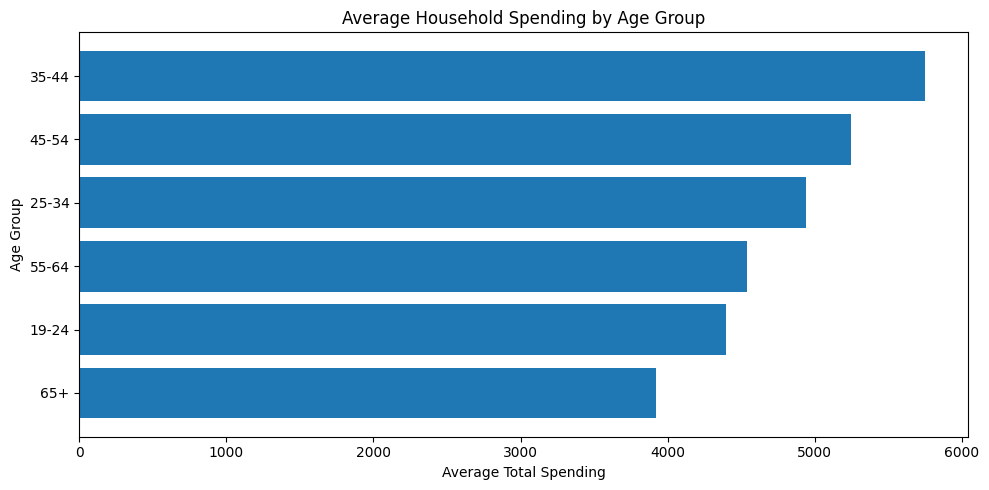

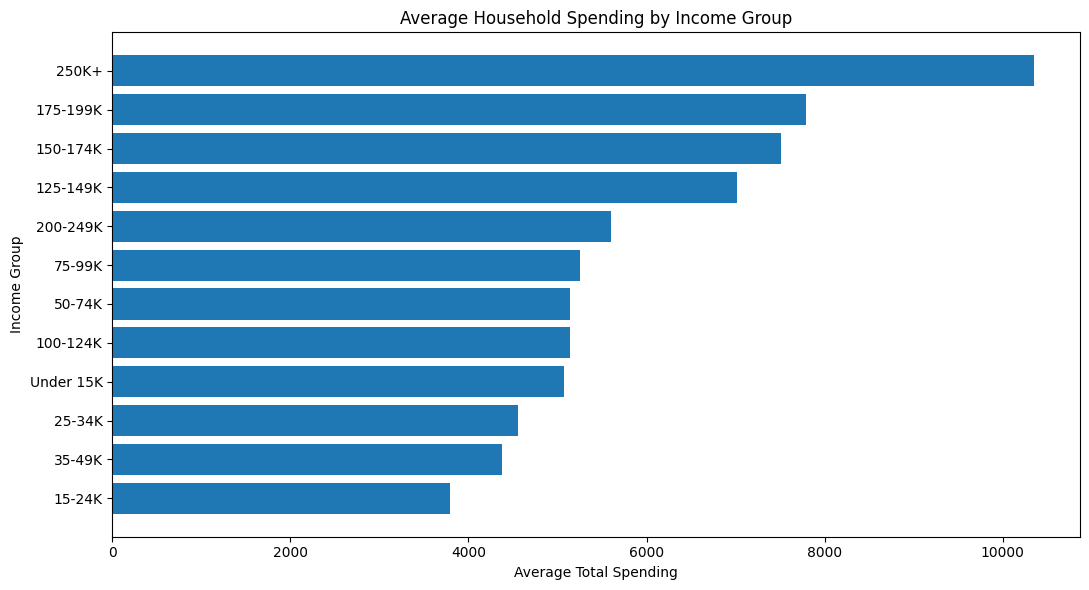

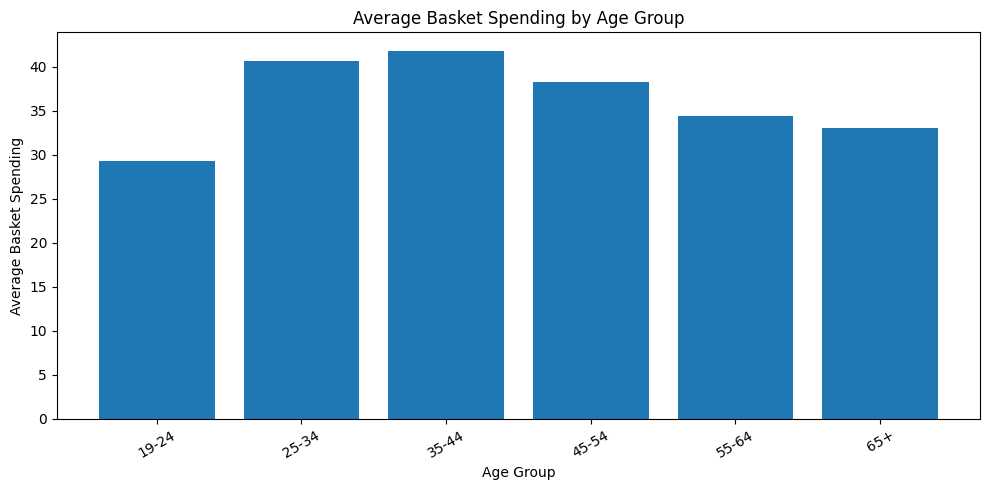

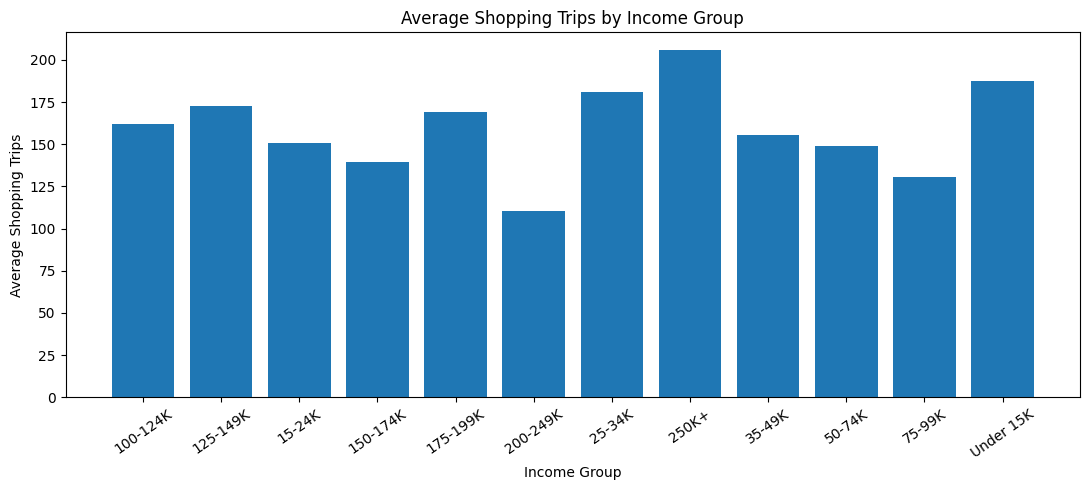

In [255]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# AGE GROUP SPENDING
# --------------------------------------------------

age_plot = age_analysis.sort_values("average_total_spending")

plt.figure(figsize=(10, 5))

plt.barh(
    age_plot["AGE_DESC"],
    age_plot["average_total_spending"]
)

plt.title("Average Household Spending by Age Group")
plt.xlabel("Average Total Spending")
plt.ylabel("Age Group")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# INCOME GROUP SPENDING
# --------------------------------------------------

income_plot = income_analysis.sort_values(
    "average_total_spending"
)

plt.figure(figsize=(11, 6))

plt.barh(
    income_plot["INCOME_DESC"],
    income_plot["average_total_spending"]
)

plt.title("Average Household Spending by Income Group")
plt.xlabel("Average Total Spending")
plt.ylabel("Income Group")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# AVERAGE BASKET SPENDING BY AGE
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    age_analysis["AGE_DESC"],
    age_analysis["average_basket_spending"]
)

plt.title("Average Basket Spending by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Basket Spending")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# SHOPPING FREQUENCY BY INCOME
# --------------------------------------------------

plt.figure(figsize=(11, 5))

plt.bar(
    income_analysis["INCOME_DESC"],
    income_analysis["average_shopping_trips"]
)

plt.title("Average Shopping Trips by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Average Shopping Trips")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [256]:
# --------------------------------------------------
# EXPORT CUSTOMER DEMOGRAPHIC DATA
# --------------------------------------------------

import os

os.makedirs("pricing_dashboard_data", exist_ok=True)

demographic_export = household_demographics.copy()

demographic_export.to_csv(
    "pricing_dashboard_data/customer_demographics.csv",
    index=False
)

print("Customer demographics exported successfully.")
print("Rows:", len(demographic_export))
print("Columns:", len(demographic_export.columns))

Customer demographics exported successfully.
Rows: 2500
Columns: 13
